In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 140)

In [3]:
import os
os.getcwd()

'/Users/mohitsinghal/opioid-risk-medicaid/Notebooks'

In [4]:
os.listdir()

['01_medicaid_opioid_analysis.ipynb', '.ipynb_checkpoints']

In [5]:
SDUD_FILES = [
    "../Data/utilization_2021.csv",
    "../Data/utilization_2022.csv",
    "../Data/utilization_2023.csv",
]

ENROLLMENT_FILES = [
    "../Data/enrollment_2021.csv",
    "../Data/enrollment_2022.csv",
    "../Data/enrollment_2023.csv",
]
EXPANSION_FILE  = "../Data/medicaid_expansion.csv"

FDA_PRODUCT = pd.read_csv(
    "../Data/product.txt",
    sep="\t",
    dtype=str, encoding="latin1",
    low_memory=False
)



YEARS = [2021, 2022, 2023]


In [6]:
EXPANSION_FILE = "../Data/medicaid_expansion.csv"

with open(EXPANSION_FILE, "r", encoding="utf-8", errors="replace") as f:
    for i in range(10):
        print(f"{i+1:02d}:", f.readline().rstrip("\n"))


01: ﻿"Title: Status of State Action on the Medicaid Expansion Decision | KFF State Health Facts"
02: "Timeframe: September 2025"
03: "Location","Status of Medicaid Expansion Decision","Expansion Implementation Date","Expansion Adopted Through Ballot Initiative","Trigger Law In Place",Footnotes
04: "United States","Adopted: 41 states (incl. DC)  Not Adopted: 10 states","","Yes: 7 states   No: 34 states (incl. DC)  Not Adopted: 10 states","Yes: 13 states  No: 28 states (incl. DC)  Not Adopted: 10 states"
05: "Alabama","Not Adopted","N/A","N/A",""
06: "Alaska","Adopted","9/1/2015","No","No"
07: "Arizona","Adopted","1/1/2014","No","Yes","1"
08: "Arkansas","Adopted","1/1/2014","No","Yes","1"
09: "California","Adopted","1/1/2014","No","No"
10: "Colorado","Adopted","1/1/2014","No","No"


In [7]:
exp = pd.read_csv(EXPANSION_FILE,skiprows=2)

exp = exp.rename(columns={
    "Location": "state",
    "Status of Medicaid Expansion Decision": "expansion_status"
})
exp["state"] = exp["state"].astype(str).str.strip().str.upper()
exp["expansion"] = pd.to_numeric(exp["expansion_status"], errors="coerce")

exp_years = (
    exp.assign(key=1)
       .merge(pd.DataFrame({"year": YEARS, "key": 1}), on="key")
       .drop(columns="key")
)

exp_years.head()

,state,expansion_status,Expansion Implementation Date,Expansion Adopted Through Ballot Initiative,Trigger Law In Place,Footnotes,expansion,year
0,UNITED STATES,Adopted: 41 states (incl. DC) Not Adopted: 10...,NaN,Yes: 7 states No: 34 states (incl. DC) Not ...,Yes: 13 states No: 28 states (incl. DC) Not ...,NaN,NaN,2021
1,UNITED STATES,Adopted: 41 states (incl. DC) Not Adopted: 10...,NaN,Yes: 7 states No: 34 states (incl. DC) Not ...,Yes: 13 states No: 28 states (incl. DC) Not ...,NaN,NaN,2022
2,UNITED STATES,Adopted: 41 states (incl. DC) Not Adopted: 10...,NaN,Yes: 7 states No: 34 states (incl. DC) Not ...,Yes: 13 states No: 28 states (incl. DC) Not ...,NaN,NaN,2023
3,ALABAMA,Not Adopted,NaN,NaN,NaN,NaN,NaN,2021
4,ALABAMA,Not Adopted,NaN,NaN,NaN,NaN,NaN,2022


In [8]:
exp = exp_years[exp_years["state"] != "UNITED STATES"].copy()

In [9]:
exp["state"].head()

3    ALABAMA
4    ALABAMA
5    ALABAMA
6     ALASKA
7     ALASKA
Name: state, dtype: object

In [10]:
exp["medicaid_expansion"] = exp["expansion_status"].map({
    "Adopted": 1,
    "Not Adopted": 0
})

In [11]:
exp.head(3)

,state,expansion_status,Expansion Implementation Date,Expansion Adopted Through Ballot Initiative,Trigger Law In Place,Footnotes,expansion,year,medicaid_expansion
3,ALABAMA,Not Adopted,NaN,NaN,NaN,NaN,NaN,2021,0.0
4,ALABAMA,Not Adopted,NaN,NaN,NaN,NaN,NaN,2022,0.0
5,ALABAMA,Not Adopted,NaN,NaN,NaN,NaN,NaN,2023,0.0


In [12]:
exp[["state", "year", "expansion_status", "medicaid_expansion"]].head(10)

,state,year,expansion_status,medicaid_expansion
3,ALABAMA,2021,Not Adopted,0.0
4,ALABAMA,2022,Not Adopted,0.0
5,ALABAMA,2023,Not Adopted,0.0
6,ALASKA,2021,Adopted,1.0
7,ALASKA,2022,Adopted,1.0
8,ALASKA,2023,Adopted,1.0
9,ARIZONA,2021,Adopted,1.0
10,ARIZONA,2022,Adopted,1.0
11,ARIZONA,2023,Adopted,1.0
12,ARKANSAS,2021,Adopted,1.0


In [13]:
exp = exp[["state", "year", "medicaid_expansion"]]

In [14]:
exp.groupby("medicaid_expansion")["state"].nunique()

medicaid_expansion
0.0    10
1.0    41
Name: state, dtype: int64

In [15]:
STATE_NAME_TO_ABBR = {
    "ALABAMA":"AL","ALASKA":"AK","ARIZONA":"AZ","ARKANSAS":"AR","CALIFORNIA":"CA",
    "COLORADO":"CO","CONNECTICUT":"CT","DELAWARE":"DE","DISTRICT OF COLUMBIA":"DC",
    "FLORIDA":"FL","GEORGIA":"GA","HAWAII":"HI","IDAHO":"ID","ILLINOIS":"IL",
    "INDIANA":"IN","IOWA":"IA","KANSAS":"KS","KENTUCKY":"KY","LOUISIANA":"LA",
    "MAINE":"ME","MARYLAND":"MD","MASSACHUSETTS":"MA","MICHIGAN":"MI","MINNESOTA":"MN",
    "MISSISSIPPI":"MS","MISSOURI":"MO","MONTANA":"MT","NEBRASKA":"NE","NEVADA":"NV",
    "NEW HAMPSHIRE":"NH","NEW JERSEY":"NJ","NEW MEXICO":"NM","NEW YORK":"NY",
    "NORTH CAROLINA":"NC","NORTH DAKOTA":"ND","OHIO":"OH","OKLAHOMA":"OK","OREGON":"OR",
    "PENNSYLVANIA":"PA","RHODE ISLAND":"RI","SOUTH CAROLINA":"SC","SOUTH DAKOTA":"SD",
    "TENNESSEE":"TN","TEXAS":"TX","UTAH":"UT","VERMONT":"VT","VIRGINIA":"VA",
    "WASHINGTON":"WA","WEST VIRGINIA":"WV","WISCONSIN":"WI","WYOMING":"WY"
}


In [16]:
exp["state"] = exp["state"].astype(str).str.strip().str.upper()
exp["State"] = exp["state"].map(STATE_NAME_TO_ABBR)

# keep only what we need
print(
    exp.loc[exp["State"].isna(), "state"]
    .drop_duplicates()
    .head(20)
)


156                                                NOTES
159    STATES' DECISIONS ABOUT ADOPTING THE MEDICAID ...
162                                                  NAN
165    A CENTRAL GOAL OF THE AFFORDABLE CARE ACT (ACA...
171    FOR ADDITIONAL INFORMATION, INCLUDING A DOWNLO...
174                                              SOURCES
177    CURRENT STATUS FOR EACH STATE IS BASED ON KFF ...
180                                            FOOTNOTES
183    1. TEN STATES (ARIZONA, ARKANSAS, ILLINOIS, IN...
186    2. IDAHO VOTED TO ADOPT MEDICAID EXPANSION IN ...
189    3. THREE STATES (IDAHO, IOWA, AND NEW MEXICO) ...
192    4. MAINE VOTED TO ADOPT MEDICAID EXPANSION THR...
195    5. MEDICAID COVERAGE UNDER EXPANSION BEGAN IN ...
198    6. AFTER NEBRASKA VOTERS APPROVED OF THE BALLO...
201    7. NORTH CAROLINA'S LEGISLATION TO EXPAND MEDI...
204    8. OKLAHOMA VOTERS APPROVED A BALLOT MEASURE O...
207    9. VOTERS IN SOUTH DAKOTA APPROVED A BALLOT ME...
210    10. AFTER UTAH VOTERS AP

In [17]:
util_dfs = []

for f in SDUD_FILES:
    print("Loading:", f)
    df = pd.read_csv(f, low_memory=False)
    util_dfs.append(df)

util_raw = pd.concat(util_dfs, ignore_index=True)

print(util_raw.shape)
util_raw.head()


Loading: ../Data/utilization_2021.csv
Loading: ../Data/utilization_2022.csv
Loading: ../Data/utilization_2023.csv
(15557876, 15)


,Utilization Type,State,NDC,Labeler Code,Product Code,Package Size,Year,Quarter,Suppression Used,Product Name,Units Reimbursed,Number of Prescriptions,Total Amount Reimbursed,Medicaid Amount Reimbursed,Non Medicaid Amount Reimbursed
0,FFSU,AK,00002143380,2,1433,80,2021,4,False,TRULICITY,544.0,222.0,220042.29,215557.09,4485.20
1,FFSU,AK,00002143480,2,1434,80,2021,4,False,TRULICITY,706.0,275.0,286542.68,281194.56,5348.12
2,FFSU,AK,00002143611,2,1436,11,2021,4,False,EMGALITY P,27.0,27.0,16648.52,16648.52,0.00
3,FFSU,AK,00002144511,2,1445,11,2021,4,False,TALTZ AUTO,14.0,14.0,83578.05,72671.03,10907.02
4,FFSU,AK,00002144527,2,1445,27,2021,4,True,TALTZ AUTO,NaN,NaN,NaN,NaN,NaN


In [18]:
print(FDA_PRODUCT.shape)
FDA_PRODUCT.columns.tolist()
FDA_PRODUCT.head(3)

(108974, 20)


,PRODUCTID,PRODUCTNDC,PRODUCTTYPENAME,PROPRIETARYNAME,PROPRIETARYNAMESUFFIX,NONPROPRIETARYNAME,DOSAGEFORMNAME,ROUTENAME,STARTMARKETINGDATE,ENDMARKETINGDATE,MARKETINGCATEGORYNAME,APPLICATIONNUMBER,LABELERNAME,SUBSTANCENAME,ACTIVE_NUMERATOR_STRENGTH,ACTIVE_INGRED_UNIT,PHARM_CLASSES,DEASCHEDULE,NDC_EXCLUDE_FLAG,LISTING_RECORD_CERTIFIED_THROUGH
0,0002-0152_c2c23f77-fa0e-4e51-af90-77a1a5060924,0002-0152,HUMAN PRESCRIPTION DRUG,Zepbound,NaN,tirzepatide,"INJECTION, SOLUTION",SUBCUTANEOUS,20231108,NaN,NDA,NDA217806,Eli Lilly and Company,TIRZEPATIDE,2.5,mg/.5mL,"G-Protein-linked Receptor Interactions [MoA], ...",NaN,N,20261231
1,0002-0213_42527ae4-c593-4e13-8b77-c0511198c708,0002-0213,HUMAN OTC DRUG,Humulin,R,Insulin human,"INJECTION, SOLUTION",PARENTERAL,19830627,20261215,BLA,BLA018780,Eli Lilly and Company,INSULIN HUMAN,100,[iU]/mL,"Insulin [CS], Insulin [EPC]",NaN,N,NaN
2,0002-0243_c2c23f77-fa0e-4e51-af90-77a1a5060924,0002-0243,HUMAN PRESCRIPTION DRUG,Zepbound,NaN,tirzepatide,"INJECTION, SOLUTION",SUBCUTANEOUS,20231108,NaN,NDA,NDA217806,Eli Lilly and Company,TIRZEPATIDE,5,mg/.5mL,"G-Protein-linked Receptor Interactions [MoA], ...",NaN,N,20261231


In [19]:
FDA_PRODUCT.columns.tolist()

['PRODUCTID',
 'PRODUCTNDC',
 'PRODUCTTYPENAME',
 'PROPRIETARYNAME',
 'PROPRIETARYNAMESUFFIX',
 'NONPROPRIETARYNAME',
 'DOSAGEFORMNAME',
 'ROUTENAME',
 'STARTMARKETINGDATE',
 'ENDMARKETINGDATE',
 'MARKETINGCATEGORYNAME',
 'APPLICATIONNUMBER',
 'LABELERNAME',
 'SUBSTANCENAME',
 'ACTIVE_NUMERATOR_STRENGTH',
 'ACTIVE_INGRED_UNIT',
 'PHARM_CLASSES',
 'DEASCHEDULE',
 'NDC_EXCLUDE_FLAG',
 'LISTING_RECORD_CERTIFIED_THROUGH']

In [20]:
FDA_PRODUCT["SUBSTANCENAME"] = FDA_PRODUCT["SUBSTANCENAME"].str.upper()
FDA_PRODUCT["DEA_SCHEDULE"] = FDA_PRODUCT["DEASCHEDULE"].str.upper()

In [21]:
opioid_substances = [
    "MORPHINE",
    "OXYCODONE",
    "HYDROCODONE",
    "CODEINE",
    "FENTANYL",
    "HYDROMORPHONE",
    "OXMORPHONE",
    "MEPERIDINE",
    "TAPENTADOL",
    "TRAMADOL",
    "BUPRENORPHINE",
    "METHADONE"
]

In [22]:
FDA_PRODUCT["is_opioid_substance"] = FDA_PRODUCT["SUBSTANCENAME"].apply(
    lambda x: any(op in x for op in opioid_substances) if pd.notna(x) else False
)

print("Opioid products (substance-based):",
      FDA_PRODUCT["is_opioid_substance"].sum())

Opioid products (substance-based): 1376


In [23]:
opioid_schedules = ["SCHEDULE II", "SCHEDULE III"]

FDA_PRODUCT["is_opioid_dea"] = FDA_PRODUCT["DEA_SCHEDULE"].isin(opioid_schedules)

pd.crosstab(
    FDA_PRODUCT["is_opioid_substance"],
    FDA_PRODUCT["is_opioid_dea"]
)

is_opioid_dea,False
is_opioid_substance,
False,107598
True,1376


In [24]:
opioid_ref = FDA_PRODUCT[
    FDA_PRODUCT["is_opioid_substance"]
][["PRODUCTNDC", "SUBSTANCENAME", "DEA_SCHEDULE"]].copy()

# Standardize NDC format
opioid_ref["PRODUCTNDC"] = opioid_ref["PRODUCTNDC"].str.replace("-", "").str.zfill(11)

print("Final opioid reference rows:", opioid_ref.shape)
opioid_ref.head()

Final opioid reference rows: (1376, 3)


,PRODUCTNDC,SUBSTANCENAME,DEA_SCHEDULE
748,00000540176,BUPRENORPHINE HYDROCHLORIDE,CIII
749,00000540177,BUPRENORPHINE HYDROCHLORIDE,CIII
750,00000540188,BUPRENORPHINE HYDROCHLORIDE; NALOXONE HYDROCHL...,CIII
751,00000540189,BUPRENORPHINE HYDROCHLORIDE; NALOXONE HYDROCHL...,CIII
758,00000540235,MORPHINE SULFATE,CII


In [25]:
# Standardize utilization NDC
util_raw["NDC"] = util_raw["NDC"].astype(str).str.zfill(11)

# Filter to opioid-only utilization
util_opioid = util_raw.merge(
    opioid_ref,
    left_on="NDC",
    right_on="PRODUCTNDC",
    how="inner"
)

print("All utilization rows:", util_raw.shape[0])
print("Opioid-only utilization rows:", util_opioid.shape[0])

util_opioid[["Product Name", "SUBSTANCENAME", "DEA_SCHEDULE"]].head()

All utilization rows: 15557876
Opioid-only utilization rows: 0


,Product Name,SUBSTANCENAME,DEA_SCHEDULE


In [26]:
# Ensure both are strings, 11 chars
u_ndc = util_raw["NDC"].astype(str).str.zfill(11)
p_ndc = opioid_ref["PRODUCTNDC"].astype(str).str.zfill(11)

print("Unique util NDCs:", u_ndc.nunique())
print("Unique opioid PRODUCTNDCs:", p_ndc.nunique())

# Intersection size
common = set(u_ndc.unique()).intersection(set(p_ndc.unique()))
print("Common NDCs:", len(common))

# Show a few common values if any
print("Sample common:", list(common)[:10])

Unique util NDCs: 63098
Unique opioid PRODUCTNDCs: 1368
Common NDCs: 0
Sample common: []


In [27]:
util_raw["NDC"] = util_raw["NDC"].astype(str).str.zfill(11)
util_raw["PRODUCT_KEY"] = util_raw["NDC"].str[:9]   # labeler+product
opioid_ref["PRODUCT_KEY"] = opioid_ref["PRODUCTNDC"].astype(str).str.zfill(11).str[:9]

util_opioid = util_raw.merge(
    opioid_ref[["PRODUCT_KEY", "SUBSTANCENAME", "DEA_SCHEDULE"]].drop_duplicates(),
    on="PRODUCT_KEY",
    how="inner"
)

print("Opioid-only rows:", util_opioid.shape[0])
util_opioid[["Product Name", "NDC", "SUBSTANCENAME", "DEA_SCHEDULE"]].head()

Opioid-only rows: 6


,Product Name,NDC,SUBSTANCENAME,DEA_SCHEDULE
0,,00009046665,OXYCODONE HYDROCHLORIDE,CII
1,,00009046808,OXYCODONE HYDROCHLORIDE,CII
2,,00009046917,OXYCODONE HYDROCHLORIDE,CII
3,UNKNOWN,00009046665,OXYCODONE HYDROCHLORIDE,CII
4,UNKNOWN,00009046808,OXYCODONE HYDROCHLORIDE,CII


In [28]:
# Clean NDC
util_raw["NDC"] = util_raw["NDC"].astype(str).str.replace(r"\D", "", regex=True).str.zfill(11)

# Build PRODUCT_KEY using Labeler Code + Product Code as strings
lab = util_raw["Labeler Code"].astype(str).str.strip()
prd = util_raw["Product Code"].astype(str).str.strip()

# If codes contain non-digits, keep only digits (safe for NDC logic)
lab = lab.str.replace(r"\D", "", regex=True).str.zfill(5)
prd = prd.str.replace(r"\D", "", regex=True).str.zfill(4)

util_raw["PRODUCT_KEY"] = lab + prd

# Clean FDA product ndc and build key
opioid_ref["PRODUCTNDC_clean"] = opioid_ref["PRODUCTNDC"].astype(str).str.replace(r"\D", "", regex=True).str.zfill(11)
opioid_ref["PRODUCT_KEY"] = opioid_ref["PRODUCTNDC_clean"].str[:9]

# Merge
util_opioid = util_raw.merge(
    opioid_ref[["PRODUCT_KEY", "SUBSTANCENAME", "DEA_SCHEDULE"]].drop_duplicates(),
    on="PRODUCT_KEY",
    how="inner"
)

print("All utilization rows:", util_raw.shape[0])
print("Opioid-only rows:", util_opioid.shape[0])

util_opioid[["State","Year","Quarter","Product Name","NDC","SUBSTANCENAME","DEA_SCHEDULE"]].head(20)

All utilization rows: 15557876
Opioid-only rows: 6


,State,Year,Quarter,Product Name,NDC,SUBSTANCENAME,DEA_SCHEDULE
0,XX,2022,2,,00009046665,OXYCODONE HYDROCHLORIDE,CII
1,XX,2022,2,,00009046808,OXYCODONE HYDROCHLORIDE,CII
2,XX,2022,2,,00009046917,OXYCODONE HYDROCHLORIDE,CII
3,VA,2022,2,UNKNOWN,00009046665,OXYCODONE HYDROCHLORIDE,CII
4,VA,2022,2,UNKNOWN,00009046808,OXYCODONE HYDROCHLORIDE,CII
5,VA,2022,2,UNKNOWN,00009046917,OXYCODONE HYDROCHLORIDE,CII


In [29]:
import re

opioid_name_patterns = [
    r"OXYCODONE",
    r"HYDROCODONE",
    r"MORPHINE",
    r"FENTANYL",
    r"CODEINE",
    r"HYDROMORPHONE",
    r"OXMORPHONE",
    r"TRAMADOL",
    r"BUPRENORPHINE",
    r"METHADONE",
    r"TAPENTADOL"
]

rx = re.compile("|".join(opioid_name_patterns))

util_raw["is_opioid_name"] = util_raw["Product Name"].astype(str).str.upper().apply(
    lambda x: bool(rx.search(x))
)

util_opioid = util_raw[util_raw["is_opioid_name"]].copy()

print("Opioid rows (name-based):", util_opioid.shape[0])
util_opioid[["State","Year","Product Name"]].head(20)

Opioid rows (name-based): 230599


,State,Year,Product Name
265,AK,2021,MORPHINE S
266,AK,2021,MORPHINE S
267,AK,2021,MORPHINE S
268,AK,2021,MORPHINE S
269,AK,2021,CODEINE SU
277,AK,2021,OXYCODONE
285,AK,2021,MORPHINE S
286,AK,2021,MORPHINE S
293,AK,2021,METHADONE
294,AK,2021,METHADONE


In [30]:
util_opioid = util_raw[util_raw["is_opioid_name"]].copy()

In [31]:
for c in ["Number of Prescriptions", "Medicaid Amount Reimbursed"]:
    util_opioid[c] = pd.to_numeric(util_opioid[c], errors="coerce")

In [32]:
state_year = (
    util_opioid
    .groupby(["State", "Year"], as_index=False)
    .agg(
        opioid_rx=("Number of Prescriptions", "sum"),
        opioid_spend=("Medicaid Amount Reimbursed", "sum")
    )
)

state_year["spend_per_rx"] = state_year["opioid_spend"] / state_year["opioid_rx"]
state_year.head()

,State,Year,opioid_rx,opioid_spend,spend_per_rx
0,AK,2021,32189.0,676322.22,21.010973
1,AK,2022,28953.0,547231.37,18.900679
2,AK,2023,23514.0,476553.70,20.266807
3,AL,2021,76216.0,1158364.34,15.198440
4,AL,2022,66484.0,950192.93,14.292054


In [33]:
enroll_dfs = []

for f in ENROLLMENT_FILES:
    df = pd.read_csv(f, low_memory=False)
    enroll_dfs.append(df)

enrollment_raw = pd.concat(enroll_dfs, ignore_index=True)
print(enrollment_raw.shape)
enrollment_raw.head()

(30600, 44)


,State Abbreviation,State Name,Reporting Period,State Expanded Medicaid,Preliminary or Updated,Final Report,New Applications Submitted to Medicaid and CHIP Agencies,New Applications Submitted to Medicaid and CHIP Agencies - footnotes,Applications for Financial Assistance Submitted to the State Based Marketplace,Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes,Total Applications for Financial Assistance Submitted at State Level,Total Applications for Financial Assistance Submitted at State Level - footnotes,Individuals Determined Eligible for Medicaid at Application,Individuals Determined Eligible for Medicaid at Application - footnotes,Individuals Determined Eligible for CHIP at Application,Individuals Determined Eligible for CHIP at Application - footnotes,Total Medicaid and CHIP Determinations,Total Medicaid and CHIP Determinations - footnotes,Medicaid and CHIP Child Enrollment,Medicaid and CHIP Child Enrollment - footnotes,Total Medicaid and CHIP Enrollment,Total Medicaid and CHIP Enrollment - footnotes,Total Medicaid Enrollment,Total Medicaid Enrollment - footnotes,Total CHIP Enrollment,Total CHIP Enrollment - footnotes,Total Adult Medicaid Enrollment,Total Adult Medicaid Enrollment - footnotes,Total Medicaid and CHIP Determinations Processed in Less than 24 Hours,Total Medicaid and CHIP Determinations Processed in Less than 24 Hours - footnotes,Total Medicaid and CHIP Determinations Processed Between 24 Hours and 7 Days,Total Medicaid and CHIP Determinations Processed Between 24 Hours and 7 Days - footnotes,Total Medicaid and CHIP Determinations Processed Between 8 Days and 30 Days,Total Medicaid and CHIP Determinations Processed Between 8 Days and 30 Days - footnotes,Total Medicaid and CHIP Determinations Processed between 31 days and 45 days,Total Medicaid and CHIP Determinations Processed between 31 days and 45 days - footnotes,Total Medicaid and CHIP Determinations Processed in More than 45 Days,Total Medicaid and CHIP Determinations Processed in More than 45 Days - footnotes,Total Call Center Volume (Number of Calls),Total Call Center Volume (Number of Calls) - footnotes,Average Call Center Wait Time (Minutes),Average Call Center Wait Time (Minutes) - footnotes,Average Call Center Abandonment Rate,Average Call Center Abandonment Rate - footnotes
0,AK,Alaska,201309,N,U,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,122334.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,AK,Alaska,201706,Y,P,N,3017.0,Includes Renewals and/or Redeterminations,0.0,NaN,3017.0,Includes Renewals and/or Redeterminations,3422.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3422.0,Includes Renewals and/or Redeterminations,88766.0,NaN,191171.0,NaN,179001.0,NaN,12170.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,AK,Alaska,201706,Y,U,Y,3069.0,Includes Renewals and/or Redeterminations,0.0,NaN,3069.0,Includes Renewals and/or Redeterminations,3422.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3422.0,Includes Renewals and/or Redeterminations,90081.0,NaN,194534.0,NaN,182080.0,NaN,12454.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,AK,Alaska,201707,Y,P,N,3187.0,Includes Renewals and/or Redeterminations,0.0,NaN,3187.0,Includes Renewals and/or Redeterminations,3159.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3159.0,Includes Renewals and/or Redeterminations,89358.0,NaN,193019.0,NaN,180641.0,NaN,12378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,AK,Alaska,201707,Y,U,Y,3265.0,Includes Renewals and/or Redeterminations,0.0,NaN,3265.0,Includes Renewals and/or Redeterminations,3159.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3159.0,Includes Renewals and/or Redeterminations,90562.0,NaN,196121.0,NaN,183516.0,NaN,12605.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [34]:
enrollment_raw.columns.tolist()

['State Abbreviation',
 'State Name',
 'Reporting Period',
 'State Expanded Medicaid',
 'Preliminary or Updated',
 'Final Report',
 'New Applications Submitted to Medicaid and CHIP Agencies',
 'New Applications Submitted to Medicaid and CHIP Agencies - footnotes',
 'Applications for Financial Assistance Submitted to the State Based Marketplace',
 'Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes',
 'Total Applications for Financial Assistance Submitted at State Level',
 'Total Applications for Financial Assistance Submitted at State Level - footnotes',
 'Individuals Determined Eligible for Medicaid at Application',
 'Individuals Determined Eligible for Medicaid at Application - footnotes',
 'Individuals Determined Eligible for CHIP at Application',
 'Individuals Determined Eligible for CHIP at Application - footnotes',
 'Total Medicaid and CHIP Determinations',
 'Total Medicaid and CHIP Determinations - footnotes',
 'Medicaid and CHIP Child Enr

In [35]:
rp = enrollment_raw["Reporting Period"]
rp = pd.to_numeric(rp, errors="coerce")

enrollment_raw["rp_year"] = (rp // 100).astype("Int64")
enrollment_raw["rp_month"] = (rp % 100).astype("Int64")

enrollment_raw["rp_year"].describe()

count     30600.0
mean      2021.02
std      2.481895
min        2013.0
25%        2019.0
50%        2021.0
75%        2023.0
max        2025.0
Name: rp_year, dtype: Float64

In [36]:
enrollment_raw["Reporting Period"].head(20).tolist()

[201309,
 201706,
 201706,
 201707,
 201707,
 201708,
 201708,
 201709,
 201709,
 201710,
 201710,
 201711,
 201711,
 201712,
 201712,
 201801,
 201801,
 201802,
 201802,
 201803]

In [37]:
enrollment_raw["rp_year"].value_counts().sort_index().tail(15)

rp_year
2013     153
2017    2142
2018    3672
2019    3672
2020    3672
2021    3672
2022    3672
2023    3672
2024    3672
2025    2601
Name: count, dtype: Int64

In [38]:
rp = enrollment_raw["Reporting Period"].astype(str).str.extract(r"(\d{6})")[0]
enrollment_raw["rp_dt"] = pd.to_datetime(rp, format="%Y%m", errors="coerce")

In [39]:
enrollment_raw.head()

,State Abbreviation,State Name,Reporting Period,State Expanded Medicaid,Preliminary or Updated,Final Report,New Applications Submitted to Medicaid and CHIP Agencies,New Applications Submitted to Medicaid and CHIP Agencies - footnotes,Applications for Financial Assistance Submitted to the State Based Marketplace,Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes,Total Applications for Financial Assistance Submitted at State Level,Total Applications for Financial Assistance Submitted at State Level - footnotes,Individuals Determined Eligible for Medicaid at Application,Individuals Determined Eligible for Medicaid at Application - footnotes,Individuals Determined Eligible for CHIP at Application,Individuals Determined Eligible for CHIP at Application - footnotes,Total Medicaid and CHIP Determinations,Total Medicaid and CHIP Determinations - footnotes,Medicaid and CHIP Child Enrollment,Medicaid and CHIP Child Enrollment - footnotes,Total Medicaid and CHIP Enrollment,Total Medicaid and CHIP Enrollment - footnotes,Total Medicaid Enrollment,Total Medicaid Enrollment - footnotes,Total CHIP Enrollment,Total CHIP Enrollment - footnotes,Total Adult Medicaid Enrollment,Total Adult Medicaid Enrollment - footnotes,Total Medicaid and CHIP Determinations Processed in Less than 24 Hours,Total Medicaid and CHIP Determinations Processed in Less than 24 Hours - footnotes,Total Medicaid and CHIP Determinations Processed Between 24 Hours and 7 Days,Total Medicaid and CHIP Determinations Processed Between 24 Hours and 7 Days - footnotes,Total Medicaid and CHIP Determinations Processed Between 8 Days and 30 Days,Total Medicaid and CHIP Determinations Processed Between 8 Days and 30 Days - footnotes,Total Medicaid and CHIP Determinations Processed between 31 days and 45 days,Total Medicaid and CHIP Determinations Processed between 31 days and 45 days - footnotes,Total Medicaid and CHIP Determinations Processed in More than 45 Days,Total Medicaid and CHIP Determinations Processed in More than 45 Days - footnotes,Total Call Center Volume (Number of Calls),Total Call Center Volume (Number of Calls) - footnotes,Average Call Center Wait Time (Minutes),Average Call Center Wait Time (Minutes) - footnotes,Average Call Center Abandonment Rate,Average Call Center Abandonment Rate - footnotes,rp_year,rp_month,rp_dt
0,AK,Alaska,201309,N,U,Y,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,122334.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013,9,2013-09-01
1,AK,Alaska,201706,Y,P,N,3017.0,Includes Renewals and/or Redeterminations,0.0,NaN,3017.0,Includes Renewals and/or Redeterminations,3422.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3422.0,Includes Renewals and/or Redeterminations,88766.0,NaN,191171.0,NaN,179001.0,NaN,12170.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017,6,2017-06-01
2,AK,Alaska,201706,Y,U,Y,3069.0,Includes Renewals and/or Redeterminations,0.0,NaN,3069.0,Includes Renewals and/or Redeterminations,3422.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3422.0,Includes Renewals and/or Redeterminations,90081.0,NaN,194534.0,NaN,182080.0,NaN,12454.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017,6,2017-06-01
3,AK,Alaska,201707,Y,P,N,3187.0,Includes Renewals and/or Redeterminations,0.0,NaN,3187.0,Includes Renewals and/or Redeterminations,3159.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3159.0,Includes Renewals and/or Redeterminations,89358.0,NaN,193019.0,NaN,180641.0,NaN,12378.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017,7,2017-07-01
4,AK,Alaska,201707,Y,U,Y,3265.0,Includes Renewals and/or Redeterminations,0.0,NaN,3265.0,Includes Renewals and/or Redeterminations,3159.0,Includes Renewals and/or Redeterminations; Inc...,0.0,NaN,3159.0,Includes Renewals and/or Redeterminations,90562.0,NaN,196121.0,NaN,183516.0,NaN,1

In [40]:
opioid_state_yq = opioid_state_yq.merge(
    enrollment_state_year_quarter,
    left_on=["State","Year","Quarter"],
    right_on=["State Abbreviation","Year","Quarter"],
    how="left"
).drop(columns=["State Abbreviation"])

print("Missing enrollment rate:", opioid_state_yq["enrollment"].isna().mean())


NameError: name 'opioid_state_yq' is not defined

In [ ]:
opioid_state_yq_valid = opioid_state_yq.dropna(subset=["enrollment"]).copy()

In [ ]:
opioid_state_yq_valid["rx_per_1k"] = opioid_state_yq_valid["opioid_rx"] / opioid_state_yq_valid["enrollment"] * 1000
opioid_state_yq_valid["spend_per_member"] = opioid_state_yq_valid["opioid_spend"] / opioid_state_yq_valid["enrollment"]
opioid_state_yq_valid["spend_per_rx"] = opioid_state_yq_valid["opioid_spend"] / opioid_state_yq_valid["opioid_rx"]

opioid_state_yq_valid.replace([float("inf"), -float("inf")], pd.NA, inplace=True)
opioid_state_yq_valid.head()

In [ ]:

opioid_state_year = (
    opioid_state_yq_valid
    .groupby(["State","Year"], as_index=False)
    .agg(
        opioid_rx=("opioid_rx","sum"),
        opioid_spend=("opioid_spend","sum"),
        enrollment=("enrollment","mean")  # avg enrollment across quarters
    )
)

opioid_state_year["rx_per_1k"] = opioid_state_year["opioid_rx"] / opioid_state_year["enrollment"] * 1000
opioid_state_year["spend_per_member"] = opioid_state_year["opioid_spend"] / opioid_state_year["enrollment"]
opioid_state_year["spend_per_rx"] = opioid_state_year["opioid_spend"] / opioid_state_year["opioid_rx"]

opioid_state_year.head()


In [ ]:
exp.head()

In [ ]:
print(opioid_state_year.columns.tolist())
print(exp2.columns.tolist())

In [ ]:
# Defensive: remove any old expansion columns (just in case)
opioid_state_year = opioid_state_year.drop(
    columns=[c for c in opioid_state_year.columns if "expansion" in c.lower()],
    errors="ignore"
)

# Merge
opioid_state_year = opioid_state_year.merge(
    exp2,
    on=["State", "Year"],
    how="left"
)

# Verify
print(opioid_state_year.columns.tolist())
print(opioid_state_year["medicaid_expansion"].value_counts(dropna=False))

In [ ]:
exp_compare = (
    opioid_state_year.dropna(subset=["medicaid_expansion"])
    .groupby(["Year","medicaid_expansion"], as_index=False)
    .agg(
        spend_per_member=("spend_per_member","mean"),
        rx_per_1k=("rx_per_1k","mean"),
        spend_per_rx=("spend_per_rx","mean"),
        states=("State","nunique")
    )
)

exp_compare

In [ ]:
import matplotlib.pyplot as plt

d = exp_compare.sort_values(["medicaid_expansion","Year"])

plt.figure()
for val in sorted(d["medicaid_expansion"].unique()):
    dd = d[d["medicaid_expansion"]==val]
    plt.plot(dd["Year"], dd["rx_per_1k"], marker="o", label=f"Expansion={int(val)}")
plt.title("Opioid Prescribing Intensity (Rx per 1,000 Enrollees)")
plt.xlabel("Year")
plt.xticks([2021, 2022, 2023])
plt.ylabel("Rx per 1,000")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
plt.figure()
for val in sorted(d["medicaid_expansion"].unique()):
    dd = d[d["medicaid_expansion"]==val]
    plt.plot(dd["Year"], dd["spend_per_member"], marker="o", label=f"Expansion={int(val)}")
plt.title("Opioid Spend per Medicaid Enrollee ($)")
plt.xlabel("Year")
plt.xticks([2021, 2022, 2023])
plt.ylabel("Spend per member ($)")
plt.grid(True)
plt.legend()
plt.show()

In [ ]:
plt.figure()
for val in sorted(d["medicaid_expansion"].unique()):
    dd = d[d["medicaid_expansion"]==val]
    plt.plot(dd["Year"], dd["spend_per_rx"], marker="o", label=f"Expansion={int(val)}")
plt.title("Opioid Spend per Prescription ($)")
plt.xlabel("Year")
plt.xticks([2021, 2022, 2023])
plt.ylabel("Spend per Rx ($)")
plt.grid(True)
plt.legend()
plt.show()

#### exp_compare_weighted = (
    opioid_state_year.dropna(subset=["medicaid_expansion"])
    .assign(
        w_enroll=lambda x: x["enrollment"]
    )
    .groupby(["Year","medicaid_expansion"], as_index=False)
    .apply(lambda g: pd.Series({
        "spend_per_member_w": (g["opioid_spend"].sum() / g["enrollment"].sum()),
        "rx_per_1k_w": (g["opioid_rx"].sum() / g["enrollment"].sum() * 1000),
        "spend_per_rx_w": (g["opioid_spend"].sum() / g["opioid_rx"].sum()),
        "states": g["State"].nunique()
    }))
)

exp_compare_weighted

In [ ]:
req_cols = ["State","Year","opioid_rx","opioid_spend","enrollment","medicaid_expansion"]
missing = [c for c in req_cols if c not in opioid_state_year.columns]
print("Missing in opioid_state_year:", missing)

opioid_state_year = opioid_state_year.dropna(subset=["enrollment"]).copy()

opioid_state_year["rx_per_1k"] = opioid_state_year["opioid_rx"] / opioid_state_year["enrollment"] * 1000
opioid_state_year["spend_per_member"] = opioid_state_year["opioid_spend"] / opioid_state_year["enrollment"]
opioid_state_year["spend_per_rx"] = opioid_state_year["opioid_spend"] / opioid_state_year["opioid_rx"]
opioid_state_year.replace([float("inf"), -float("inf")], pd.NA, inplace=True)

In [ ]:
import matplotlib.pyplot as plt

d = opioid_state_year.dropna(subset=["medicaid_expansion","rx_per_1k"]).copy()
d["medicaid_expansion"] = d["medicaid_expansion"].astype(int)

years = sorted(d["Year"].unique())
labels = {0:"Non-expansion", 1:"Expansion"}

for y in years:
    dy = d[d["Year"]==y]
    data0 = dy[dy["medicaid_expansion"]==0]["rx_per_1k"].dropna().values
    data1 = dy[dy["medicaid_expansion"]==1]["rx_per_1k"].dropna().values
    
    plt.figure()
    plt.boxplot([data0, data1], labels=[labels[0], labels[1]], showfliers=False)
    plt.title(f"Distribution of Opioid Prescribing Intensity (Rx per 1,000) — {y}")
    plt.xlabel("")
    plt.ylabel("Rx per 1,000 enrollees")
    plt.grid(True, axis="y")
    plt.show()

In [ ]:
import matplotlib.pyplot as plt

d = opioid_state_year.dropna(subset=["medicaid_expansion","rx_per_1k","spend_per_member"]).copy()
d["medicaid_expansion"] = d["medicaid_expansion"].astype(int)

for y in sorted(d["Year"].unique()):
    dy = d[d["Year"]==y]
    
    plt.figure()
    # two groups: non-expansion then expansion
    for val in [0,1]:
        g = dy[dy["medicaid_expansion"]==val]
        plt.scatter(g["rx_per_1k"], g["spend_per_member"], label=f"Expansion={val}")
        
        # simple trend line (least squares)
        if len(g) >= 2:
            x = g["rx_per_1k"].values
            yv = g["spend_per_member"].values
            # drop NaNs just in case
            mask = (~pd.isna(x)) & (~pd.isna(yv))
            x = x[mask]; yv = yv[mask]
            if len(x) >= 2:
                import numpy as np
                m, b = np.polyfit(x, yv, 1)
                xs = np.linspace(x.min(), x.max(), 50)
                plt.plot(xs, m*xs + b)
    
    plt.title(f"Cost–Utilization Relationship (Spend per member vs Rx per 1,000) — {y}")
    plt.xlabel("Rx per 1,000 enrollees")
    plt.ylabel("Spend per member ($)")
    plt.grid(True)
    plt.legend()
    plt.show()

In [ ]:
util_opioid.head()

In [ ]:
import numpy as np
import pandas as pd

tmp = util_opioid.copy()
tmp["Product Name U"] = tmp["Product Name"].astype(str).str.upper()

# simple opioid-type classifier
def opioid_type(name: str) -> str:
    if "BUPRENORPHINE" in name: return "BUPRENORPHINE"
    if "METHADONE" in name: return "METHADONE"
    if "FENTANYL" in name: return "FENTANYL"
    if "OXYCODONE" in name: return "OXYCODONE"
    if "HYDROCODONE" in name: return "HYDROCODONE"
    if "MORPHINE" in name: return "MORPHINE"
    if "TRAMADOL" in name: return "TRAMADOL"
    if "CODEINE" in name: return "CODEINE"
    if "HYDROMORPHONE" in name: return "HYDROMORPHONE"
    if "OXMORPHONE" in name: return "OXMORPHONE"
    if "TAPENTADOL" in name: return "TAPENTADOL"
    return "OTHER OPIOID"

tmp["opioid_type"] = tmp["Product Name U"].apply(opioid_type)

# numeric Rx
tmp["Number of Prescriptions"] = pd.to_numeric(tmp["Number of Prescriptions"], errors="coerce")

type_state_year = (
    tmp.groupby(["State","Year","opioid_type"], as_index=False)
       .agg(rx=("Number of Prescriptions","sum"))
)

type_state_year.head()

In [ ]:
type_state_year = type_state_year.merge(
    opioid_state_year[["State","Year","medicaid_expansion"]],
    on=["State","Year"],
    how="left"
)

type_group = (
    type_state_year.dropna(subset=["medicaid_expansion"])
    .groupby(["Year","medicaid_expansion","opioid_type"], as_index=False)
    .agg(rx=("rx","sum"))
)

# convert to shares
tot = type_group.groupby(["Year","medicaid_expansion"], as_index=False)["rx"].sum().rename(columns={"rx":"rx_total"})
type_group = type_group.merge(tot, on=["Year","medicaid_expansion"], how="left")
type_group["share"] = type_group["rx"] / type_group["rx_total"]

type_group.sort_values(["Year","medicaid_expansion","share"], ascending=[True,True,False]).head(20)

In [ ]:
import matplotlib.pyplot as plt

for y in sorted(type_group["Year"].unique()):
    dy = type_group[type_group["Year"]==y].copy()
    # keep top 6 types, group rest into OTHER for readability
    top_types = (dy.groupby("opioid_type")["rx"].sum().sort_values(ascending=False).head(6).index.tolist())
    dy["opioid_type2"] = dy["opioid_type"].where(dy["opioid_type"].isin(top_types), "OTHER (combined)")
    
    dy2 = dy.groupby(["medicaid_expansion","opioid_type2"], as_index=False)["share"].sum()
    piv = dy2.pivot(index="medicaid_expansion", columns="opioid_type2", values="share").fillna(0)
    piv = piv.reindex([0,1])  # non-expansion then expansion
    
    plt.figure()
    bottom = None
    for col in piv.columns:
        if bottom is None:
            plt.bar(["Non-expansion","Expansion"], piv[col].values, label=col)
            bottom = piv[col].values
        else:
            plt.bar(["Non-expansion","Expansion"], piv[col].values, bottom=bottom, label=col)
            bottom = bottom + piv[col].values
            
    plt.title(f"Opioid Mix by Product Name — {y}")
    plt.ylabel("Share of opioid prescriptions")
    plt.grid(True, axis="y")
    plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

In [ ]:
# Build product key from utilization
u = util_opioid.copy()
u["Labeler Code"] = u["Labeler Code"].astype(str).str.replace(r"\D","",regex=True).str.zfill(5)
u["Product Code"] = u["Product Code"].astype(str).str.replace(r"\D","",regex=True).str.zfill(4)
u["PRODUCT_KEY"] = u["Labeler Code"] + u["Product Code"]

# Build FDA product key
FDA_PRODUCT["PRODUCTNDC_clean"] = FDA_PRODUCT["PRODUCTNDC"].astype(str).str.replace(r"\D","",regex=True).str.zfill(11)
FDA_PRODUCT["PRODUCT_KEY"] = FDA_PRODUCT["PRODUCTNDC_clean"].str[:9]
FDA_PRODUCT["DEA_SCHEDULE"] = FDA_PRODUCT["DEA_SCHEDULE"].astype(str).str.upper().str.strip()

dea_ref = FDA_PRODUCT[["PRODUCT_KEY","DEA_SCHEDULE","SUBSTANCENAME"]].drop_duplicates()

u = u.merge(dea_ref, on="PRODUCT_KEY", how="left")
u[["DEA_SCHEDULE","SUBSTANCENAME"]].head(10)

In [ ]:
enrollment_state_year_quarter["Year"].describe()

In [ ]:
util_opioid.columns.tolist()

In [ ]:
util_opioid.head()

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

df = util_opioid.copy()

df["PRODUCT_NAME_U"] = df["Product Name"].astype(str).str.upper().str.strip()

def extract_substance(name: str) -> str:
    # MOUD / OUD-related
    if "BUPRENORPHINE" in name: return "BUPRENORPHINE"
    if "METHADONE" in name: return "METHADONE"
    # full agonists commonly used for pain
    if "OXYCODONE" in name: return "OXYCODONE"
    if "HYDROCODONE" in name: return "HYDROCODONE"
    if "MORPHINE" in name: return "MORPHINE"
    if "FENTANYL" in name: return "FENTANYL"
    if "CODEINE" in name: return "CODEINE"
    if "HYDROMORPHONE" in name: return "HYDROMORPHONE"
    if "OXMORPHONE" in name: return "OXMORPHONE"
    if "TAPENTADOL" in name: return "TAPENTADOL"
    # other opioids / weak opioids
    if "TRAMADOL" in name: return "TRAMADOL"
    return "OTHER"

df["opioid_substance"] = df["PRODUCT_NAME_U"].apply(extract_substance)

opioid_class_map = {
    "BUPRENORPHINE": "MOUD",
    "METHADONE": "MOUD",
    "TRAMADOL": "OTHER",
    "OTHER": "OTHER",
    # treat the rest as full agonists for a clean policy story
    "OXYCODONE": "FULL_AGONIST",
    "HYDROCODONE": "FULL_AGONIST",
    "MORPHINE": "FULL_AGONIST",
    "FENTANYL": "FULL_AGONIST",
    "CODEINE": "FULL_AGONIST",
    "HYDROMORPHONE": "FULL_AGONIST",
    "OXMORPHONE": "FULL_AGONIST",
    "TAPENTADOL": "FULL_AGONIST",
}

df["opioid_class"] = df["opioid_substance"].map(opioid_class_map).fillna("OTHER")

df["opioid_substance"].value_counts().head(15)

In [ ]:
df["Number of Prescriptions"] = pd.to_numeric(df["Number of Prescriptions"], errors="coerce")
df["Medicaid Amount Reimbursed"] = pd.to_numeric(df["Medicaid Amount Reimbursed"], errors="coerce")
df["Total Amount Reimbursed"] = pd.to_numeric(df["Total Amount Reimbursed"], errors="coerce")

df[["Number of Prescriptions","Medicaid Amount Reimbursed","Total Amount Reimbursed"]].describe()

In [ ]:
mix_state_year = (
    df.groupby(["State","Year","opioid_class"], as_index=False)
      .agg(rx=("Number of Prescriptions","sum"))
)

mix_total = (
    mix_state_year.groupby(["State","Year"], as_index=False)["rx"]
    .sum()
    .rename(columns={"rx":"rx_total"})
)

mix_state_year = mix_state_year.merge(mix_total, on=["State","Year"], how="left")
mix_state_year["rx_share"] = mix_state_year["rx"] / mix_state_year["rx_total"]

mix_state_year = mix_state_year.merge(
    opioid_state_year[["State","Year","medicaid_expansion"]],
    on=["State","Year"],
    how="left"
)

mix_expansion = (
    mix_state_year.dropna(subset=["medicaid_expansion"])
    .groupby(["Year","medicaid_expansion","opioid_class"], as_index=False)
    .agg(mean_share=("rx_share","mean"))
)

mix_expansion

In [ ]:
for y in sorted(mix_expansion["Year"].unique()):
    dy = mix_expansion[mix_expansion["Year"] == y]
    piv = (dy.pivot(index="medicaid_expansion", columns="opioid_class", values="mean_share")
             .fillna(0)
             .reindex([0,1]))

    plt.figure(figsize=(6,4))
    bottom = None
    for col in piv.columns:
        if bottom is None:
            plt.bar(["Non-expansion","Expansion"], piv[col].values, label=col)
            bottom = piv[col].values
        else:
            plt.bar(["Non-expansion","Expansion"], piv[col].values, bottom=bottom, label=col)
            bottom = bottom + piv[col].values

    plt.title(f"Opioid Prescription Mix by Expansion Status — {y}")
    plt.ylabel("Share of opioid prescriptions")
    plt.grid(axis="y", alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
cost_state_year = (
    df.groupby(["State","Year","opioid_class"], as_index=False)
      .agg(
          rx=("Number of Prescriptions","sum"),
          spend_medicaid=("Medicaid Amount Reimbursed","sum"),
          spend_total=("Total Amount Reimbursed","sum")
      )
)

cost_state_year["medicaid_spend_per_rx"] = cost_state_year["spend_medicaid"] / cost_state_year["rx"]
cost_state_year["total_spend_per_rx"] = cost_state_year["spend_total"] / cost_state_year["rx"]

cost_state_year = cost_state_year.merge(
    opioid_state_year[["State","Year","medicaid_expansion"]],
    on=["State","Year"],
    how="left"
)

cost_expansion = (
    cost_state_year.dropna(subset=["medicaid_expansion","medicaid_spend_per_rx"])
    .groupby(["Year","medicaid_expansion","opioid_class"], as_index=False)
    .agg(avg_medicaid_spend_per_rx=("medicaid_spend_per_rx","mean"))
)

cost_expansion

In [ ]:
for y in sorted(cost_expansion["Year"].unique()):
    dy = cost_expansion[cost_expansion["Year"] == y]

    plt.figure(figsize=(7,4))
    for m in [0,1]:
        sub = dy[dy["medicaid_expansion"] == m].sort_values("opioid_class")
        plt.plot(sub["opioid_class"], sub["avg_medicaid_spend_per_rx"], marker="o",
                 label="Expansion" if m==1 else "Non-expansion")

    plt.title(f"Medicaid Spend per Opioid Rx by Class — {y}")
    plt.xlabel("Opioid class")
    plt.ylabel("Medicaid spend per Rx ($)")
    plt.grid(alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()

In [ ]:
top_sub_2023 = (
    df[df["Year"]==2023]
    .groupby("opioid_substance", as_index=False)
    .agg(rx=("Number of Prescriptions","sum"))
    .sort_values("rx", ascending=False)
    .head(10)
)

plt.figure(figsize=(7,4))
plt.bar(top_sub_2023["opioid_substance"], top_sub_2023["rx"])
plt.title("Top Opioid Substances by Prescriptions (2023)")
plt.xlabel("Substance")
plt.ylabel("Prescriptions")
plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

top_sub_2023

In [41]:
import pandas as pd
import numpy as np
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# ── 1. REBUILD CLEAN BASE ─────────────────────────────────────────
df = util_opioid.copy()
df["Number of Prescriptions"] = pd.to_numeric(df["Number of Prescriptions"], errors="coerce")
df["Medicaid Amount Reimbursed"] = pd.to_numeric(df["Medicaid Amount Reimbursed"], errors="coerce")
df["PRODUCT_NAME_U"] = df["Product Name"].astype(str).str.upper().str.strip()

# ── 2. CLASSIFY: MOUD vs PAIN OPIOID ────────────────────────────
def opioid_class(name):
    if any(x in name for x in ["BUPRENORPHINE","METHADONE","NALTREXONE"]): return "MOUD"
    if any(x in name for x in ["OXYCODONE","HYDROCODONE","MORPHINE","FENTANYL",
                                 "CODEINE","HYDROMORPHONE","TAPENTADOL","TRAMADOL"]): return "PAIN"
    return "OTHER"

df["opioid_class"] = df["PRODUCT_NAME_U"].apply(opioid_class)
print("Class distribution:")
print(df.groupby("opioid_class")["Number of Prescriptions"].sum().apply(lambda x: f"{x:,.0f}"))

# ── 3. STATE-YEAR-CLASS PANEL ────────────────────────────────────
panel = (
    df[df["opioid_class"].isin(["MOUD","PAIN"])]
    .groupby(["State","Year","opioid_class"], as_index=False)
    .agg(rx=("Number of Prescriptions","sum"),
         spend=("Medicaid Amount Reimbursed","sum"))
)

# pivot wide
wide = panel.pivot_table(index=["State","Year"], columns="opioid_class",
                          values=["rx","spend"], aggfunc="sum").reset_index()
wide.columns = ["State","Year","rx_MOUD","rx_PAIN","spend_MOUD","spend_PAIN"]
wide["rx_total"] = wide["rx_MOUD"] + wide["rx_PAIN"]
wide["moud_share"] = wide["rx_MOUD"] / wide["rx_total"]
wide["pain_share"] = wide["rx_PAIN"] / wide["rx_total"]

# ── 4. MERGE EXPANSION STATUS ───────────────────────────────────
exp2 = exp[["State","year","medicaid_expansion"]].rename(columns={"year":"Year","State":"state_full"})
# map state abbreviation
exp2["State"] = exp2["state_full"].map(STATE_NAME_TO_ABBR)
wide = wide.merge(exp2[["State","Year","medicaid_expansion"]].dropna(), on=["State","Year"], how="left")
wide = wide.dropna(subset=["medicaid_expansion"])
wide["medicaid_expansion"] = wide["medicaid_expansion"].astype(int)

print(f"\nPanel: {wide.shape[0]} state-years | Expansion states: {wide[wide['medicaid_expansion']==1]['State'].nunique()} | Non-expansion: {wide[wide['medicaid_expansion']==0]['State'].nunique()}")

# ── 5. KEY FINDINGS ──────────────────────────────────────────────
print("\n=== MOUD SHARE BY EXPANSION STATUS ===")
summary = wide.groupby(["Year","medicaid_expansion"]).agg(
    moud_share=("moud_share","mean"),
    rx_MOUD=("rx_MOUD","sum"),
    rx_PAIN=("rx_PAIN","sum"),
    n_states=("State","nunique")
).round(4)
print(summary)

print("\n=== STATISTICAL TEST: MOUD SHARE expansion vs non-expansion ===")
for yr in sorted(wide["Year"].unique()):
    exp_moud = wide[(wide["Year"]==yr) & (wide["medicaid_expansion"]==1)]["moud_share"].dropna()
    non_moud = wide[(wide["Year"]==yr) & (wide["medicaid_expansion"]==0)]["moud_share"].dropna()
    stat, p = stats.mannwhitneyu(exp_moud, non_moud, alternative="two-sided")
    print(f"{yr}: Expansion={exp_moud.mean():.3f} | Non-expansion={non_moud.mean():.3f} | p={p:.4f}")

# ── 6. OPII-M ────────────────────────────────────────────────────
# rx_per_enrollee × spend_per_enrollee proxy (no population needed)
# use enrollment from opioid_state_year if available
try:
    opii_base = opioid_state_year[["State","Year","enrollment","rx_per_1k","spend_per_member"]].copy()
    opii_base = opii_base.merge(exp2[["State","Year","medicaid_expansion"]].dropna(), on=["State","Year"], how="left")
    opii_base["medicaid_expansion"] = opii_base["medicaid_expansion"].astype(int)
    opii_base["OPII_M"] = (opii_base["rx_per_1k"] ** 2) / opii_base["enrollment"] * 1e6

    print("\n=== OPII-M BY EXPANSION STATUS ===")
    print(opii_base.groupby(["Year","medicaid_expansion"])[["OPII_M","rx_per_1k","spend_per_member"]].mean().round(3))

    stat2, p2 = stats.mannwhitneyu(
        opii_base[opii_base["medicaid_expansion"]==1]["OPII_M"].dropna(),
        opii_base[opii_base["medicaid_expansion"]==0]["OPII_M"].dropna(),
        alternative="two-sided"
    )
    print(f"\nOPII-M overall Mann-Whitney p={p2:.4f}")
except Exception as e:
    print(f"OPII-M skipped: {e}")

Class distribution:
opioid_class
MOUD    17,671,554
PAIN    59,792,480
Name: Number of Prescriptions, dtype: object

Panel: 0 state-years | Expansion states: 0 | Non-expansion: 0

=== MOUD SHARE BY EXPANSION STATUS ===
Empty DataFrame
Columns: [moud_share, rx_MOUD, rx_PAIN, n_states]
Index: []

=== STATISTICAL TEST: MOUD SHARE expansion vs non-expansion ===
OPII-M skipped: name 'opioid_state_year' is not defined


In [42]:
print("exp columns:", exp.columns.tolist())
print("exp sample:")
print(exp.head(3))
print("\nwide State sample:", wide["State"].head(5).tolist())
print("exp State sample:", exp["State"].head(5).tolist() if "State" in exp.columns else exp.iloc[:,0].head(5).tolist())

exp columns: ['state', 'year', 'medicaid_expansion', 'State']
exp sample:
     state  year  medicaid_expansion State
3  ALABAMA  2021                 0.0    AL
4  ALABAMA  2022                 0.0    AL
5  ALABAMA  2023                 0.0    AL

wide State sample: []
exp State sample: ['AL', 'AL', 'AL', 'AK', 'AK']


In [43]:
print("panel shape:", panel.shape)
print("panel sample:")
print(panel.head(5))
print("\ndf State sample:", df["State"].head(5).tolist())
print("df Year sample:", df["Year"].head(5).tolist())
print("df opioid_class counts:", df["opioid_class"].value_counts())

panel shape: (313, 5)
panel sample:
  State  Year opioid_class       rx      spend
0    AK  2021         MOUD    621.0   12139.30
1    AK  2021         PAIN  31568.0  664182.92
2    AK  2022         MOUD    556.0   10322.07
3    AK  2022         PAIN  28397.0  536909.30
4    AK  2023         MOUD    425.0    8029.60

df State sample: ['AK', 'AK', 'AK', 'AK', 'AK']
df Year sample: [2021, 2021, 2021, 2021, 2021]
df opioid_class counts: opioid_class
PAIN    219447
MOUD     11152
Name: count, dtype: int64


In [44]:
import pandas as pd
import numpy as np
from scipy import stats

# ── PIVOT ────────────────────────────────────────────────────────
wide = panel.pivot_table(index=["State","Year"], columns="opioid_class",
                          values=["rx","spend"], aggfunc="sum").reset_index()
wide.columns = ["State","Year","rx_MOUD","rx_PAIN","spend_MOUD","spend_PAIN"]
wide["rx_total"] = wide["rx_MOUD"] + wide["rx_PAIN"]
wide["moud_share"] = wide["rx_MOUD"] / wide["rx_total"]
wide["pain_share"] = wide["rx_PAIN"] / wide["rx_total"]

# ── MERGE EXPANSION (exp already has State abbreviation) ─────────
wide = wide.merge(
    exp[["State","year","medicaid_expansion"]].rename(columns={"year":"Year"}),
    on=["State","Year"], how="left"
)
wide = wide.dropna(subset=["medicaid_expansion"])
wide["medicaid_expansion"] = wide["medicaid_expansion"].astype(int)

print(f"Panel: {wide.shape[0]} state-years")
print(f"Expansion states: {wide[wide['medicaid_expansion']==1]['State'].nunique()}")
print(f"Non-expansion states: {wide[wide['medicaid_expansion']==0]['State'].nunique()}")

# ── KEY FINDINGS ─────────────────────────────────────────────────
print("\n=== MOUD SHARE BY EXPANSION STATUS ===")
print(wide.groupby(["Year","medicaid_expansion"])[["moud_share"]].mean().round(4))

print("\n=== MANN-WHITNEY BY YEAR ===")
for yr in sorted(wide["Year"].unique()):
    exp_moud = wide[(wide["Year"]==yr) & (wide["medicaid_expansion"]==1)]["moud_share"].dropna()
    non_moud = wide[(wide["Year"]==yr) & (wide["medicaid_expansion"]==0)]["moud_share"].dropna()
    stat, p = stats.mannwhitneyu(exp_moud, non_moud, alternative="two-sided")
    print(f"{yr}: Expansion={exp_moud.mean():.3f} | Non-expansion={non_moud.mean():.3f} | diff={exp_moud.mean()-non_moud.mean():.3f} | p={p:.4f}")

print("\n=== OVERALL (ALL YEARS) ===")
exp_all = wide[wide["medicaid_expansion"]==1]["moud_share"].dropna()
non_all = wide[wide["medicaid_expansion"]==0]["moud_share"].dropna()
stat, p = stats.mannwhitneyu(exp_all, non_all, alternative="two-sided")
print(f"Expansion mean MOUD share: {exp_all.mean():.3f}")
print(f"Non-expansion mean MOUD share: {non_all.mean():.3f}")
print(f"Difference: {exp_all.mean()-non_all.mean():.3f}")
print(f"p-value: {p:.4f}")

Panel: 153 state-years
Expansion states: 41
Non-expansion states: 10

=== MOUD SHARE BY EXPANSION STATUS ===
                         moud_share
Year medicaid_expansion            
2021 0                       0.0371
     1                       0.0718
2022 0                       0.0388
     1                       0.0892
2023 0                       0.0516
     1                       0.0866

=== MANN-WHITNEY BY YEAR ===
2021: Expansion=0.072 | Non-expansion=0.037 | diff=0.035 | p=0.2698
2022: Expansion=0.089 | Non-expansion=0.039 | diff=0.050 | p=0.1725
2023: Expansion=0.087 | Non-expansion=0.052 | diff=0.035 | p=0.1763

=== OVERALL (ALL YEARS) ===
Expansion mean MOUD share: 0.083
Non-expansion mean MOUD share: 0.042
Difference: 0.040
p-value: 0.0248


In [47]:
# DiD: Did expansion states gain more MOUD share after 2023 deregulation?
did = wide.copy()
did['post'] = (did['Year'] >= 2023).astype(int)

# Interaction term: expansion × post
did['expansion_post'] = did['medicaid_expansion'] * did['post']

import statsmodels.formula.api as smf
model_did = smf.ols(
    'moud_share ~ medicaid_expansion + post + expansion_post + C(State)',
    data=did
).fit(cov_type='HC3')

print(model_did.summary().tables[1])
print("\nDiD coefficient (expansion × post):", 
      round(model_did.params['expansion_post'], 4),
      "p=", round(model_did.pvalues['expansion_post'], 4))

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.0330      0.003     10.043      0.000       0.027       0.039
C(State)[T.AL]        -0.0305      0.007     -4.255      0.000      -0.045      -0.016
C(State)[T.AR]        -0.0151      0.004     -3.849      0.000      -0.023      -0.007
C(State)[T.AZ]        -0.0162      0.004     -4.114      0.000      -0.024      -0.009
C(State)[T.CA]        -0.0031      0.005     -0.595      0.552      -0.013       0.007
C(State)[T.CO]        -0.0136      0.004     -3.196      0.001      -0.022      -0.005
C(State)[T.CT]        -0.0082      0.004     -2.188      0.029      -0.016      -0.001
C(State)[T.DC]        -0.0181      0.004     -4.983      0.000      -0.025      -0.011
C(State)[T.DE]        -0.0086      0.004     -2.287      0.022      -0.016      -0.001
C(State)[T.FL]        -0.0314      0.008   

In [49]:
print(panel.columns.tolist())
print(panel['opioid_class'].unique())
print(panel.head(3))

['State', 'Year', 'opioid_class', 'rx', 'spend']
['MOUD' 'PAIN']
  State  Year opioid_class       rx      spend
0    AK  2021         MOUD    621.0   12139.30
1    AK  2021         PAIN  31568.0  664182.92
2    AK  2022         MOUD    556.0   10322.07


In [52]:
moud_drugs = df[df['opioid_class'] == 'MOUD']['Product Name'].value_counts()
print(moud_drugs.head(40))

Product Name
METHADONE     10659
Methadone       493
Name: count, dtype: int64


In [51]:
print(df.columns.tolist())

['Utilization Type', 'State', 'NDC', 'Labeler Code', 'Product Code', 'Package Size', 'Year', 'Quarter', 'Suppression Used', 'Product Name', 'Units Reimbursed', 'Number of Prescriptions', 'Total Amount Reimbursed', 'Medicaid Amount Reimbursed', 'Non Medicaid Amount Reimbursed', 'PRODUCT_KEY', 'is_opioid_name', 'PRODUCT_NAME_U', 'opioid_class']


In [53]:
# See what buprenorphine-related products exist in the full dataset
bupe_check = df[df['PRODUCT_NAME_U'].str.contains('BUPRENORPHINE|SUBOXONE|SUBUTEX|ZUBSOLV|BUNAVAIL', 
                                                     na=False, case=False)]['Product Name'].value_counts()
print(bupe_check.head(30))

# Also check opioid_class assignment for these
bupe_class = df[df['PRODUCT_NAME_U'].str.contains('BUPRENORPHINE|SUBOXONE|SUBUTEX|ZUBSOLV|BUNAVAIL',
                                                    na=False, case=False)]['opioid_class'].value_counts()
print(bupe_class)

Series([], Name: count, dtype: int64)
Series([], Name: count, dtype: int64)


In [54]:
# What did the original MOUD filter actually match?
print(df[df['is_opioid_name'] == True]['PRODUCT_NAME_U'].value_counts().head(50))

PRODUCT_NAME_U
OXYCODONE     67462
MORPHINE S    49650
TRAMADOL H    26294
OXYCODONE-    24419
FENTANYL C    16494
METHADONE     11152
FENTANYL       7680
FENTANYL T     6725
FENTANYL 1     2846
CODEINE-GU     2104
OXYCODONE/     2085
CODEINE PH     1920
CODEINE SU     1782
FENTANYL 2     1487
MORPHINE 2     1133
FENTANYL 5     1108
MORPHINE 4      982
TRAMADOL T      951
TRAMADOL-A      800
TRAMADOL 5      549
FENTANYL 7      492
MORPHINE 1      468
CODEINE -       454
FENTANYL P      330
CODEINE GU      179
FENTANYL R      177
TRAMADOL E      129
FENTANYL 3      128
TRAMADOL 1      123
TRAMADOL W      104
FENTANYL B       89
FENTANYL 0       79
MORPHINE 5       58
MORPHINE 8       33
MORPHINE P       22
TRAMADOL/A       22
MORPHINE 3       21
FENTANYL 6       18
MORPHINE I       14
FENTANYL M       12
TRAMADOL /       11
OXYCODONE&        7
FENTANYL 8        2
MORPHINE/N        1
MORPHINE O        1
OXYCODONEH        1
TRAMADOL A        1
Name: count, dtype: int64


In [55]:
# How was opioid_class assigned?
print(df['opioid_class'].value_counts())

opioid_class
PAIN    219447
MOUD     11152
Name: count, dtype: int64


In [56]:
# Check for truncated buprenorphine
bupe_check = df[df['PRODUCT_NAME_U'].str.startswith('BUPRENOR', na=False)]
print(bupe_check.shape)
print(bupe_check['PRODUCT_NAME_U'].value_counts().head(10))

(0, 19)
Series([], Name: count, dtype: int64)


In [57]:
print(df['Year'].value_counts().sort_index())
print(df.shape)

Year
2021    79555
2022    77362
2023    73682
Name: count, dtype: int64
(230599, 19)


In [58]:
print(os.path.exists("../Data/product.txt"))

# Also check if PRODUCTID or similar NDC-based column exists in df
print(df.columns.tolist())

True
['Utilization Type', 'State', 'NDC', 'Labeler Code', 'Product Code', 'Package Size', 'Year', 'Quarter', 'Suppression Used', 'Product Name', 'Units Reimbursed', 'Number of Prescriptions', 'Total Amount Reimbursed', 'Medicaid Amount Reimbursed', 'Non Medicaid Amount Reimbursed', 'PRODUCT_KEY', 'is_opioid_name', 'PRODUCT_NAME_U', 'opioid_class']


In [59]:
# Check what the MOUD classification criterion was
# Look at a few MOUD rows - what do their Product Name / PRODUCT_NAME_U look like?
print(df[df['opioid_class'] == 'MOUD'][['Product Name', 'PRODUCT_NAME_U', 'NDC']].drop_duplicates().head(20))

       Product Name PRODUCT_NAME_U          NDC
293      METHADONE       METHADONE  00054070925
294      METHADONE       METHADONE  00054071025
1693     METHADONE       METHADONE  00406575501
1694     METHADONE       METHADONE  00406577101
1695     METHADONE       METHADONE  00406577162
2825     METHADONE       METHADONE  00904653061
3049     METHADONE       METHADONE  13107008801
3050     METHADONE       METHADONE  13107008901
8502     METHADONE       METHADONE  67877011601
11026    METHADONE       METHADONE  00054457125
15247    METHADONE       METHADONE  31722094701
21921    METHADONE       METHADONE  00054457025
34245    METHADONE       METHADONE  00406575562
43857    METHADONE       METHADONE  00054355563
66770    METHADONE       METHADONE  31722094601
92882    Methadone       METHADONE  00054071025
97267    Methadone       METHADONE  13107008801
97268    Methadone       METHADONE  13107008901
105538   Methadone       METHADONE  67877011601
145938   METHADONE       METHADONE  6668

In [60]:
# Check if any buprenorphine NDCs exist at all
print(df[df['NDC'].astype(str).str.startswith('12496')].shape)
print(df[df['NDC'].astype(str).str.startswith('00054')].shape)

(0, 19)
(13536, 19)


In [61]:
# Simple pre-post comparison within each group
year_trend = wide.groupby(['medicaid_expansion', 'Year'])['moud_share'].mean().reset_index()
print(year_trend.pivot(index='Year', columns='medicaid_expansion', values='moud_share').round(4))

medicaid_expansion       0       1
Year                              
2021                0.0371  0.0718
2022                0.0388  0.0892
2023                0.0516  0.0866


In [63]:
# Time-varying expansion: 1 only if state was expanded for the FULL year
expansion_dates = {
    'MISSOURI': 2022,
    'OKLAHOMA': 2022,
    'SOUTH DAKOTA': 2024,   # outside study window → treated as non-expansion
    'NORTH CAROLINA': 2024  # outside study window → treated as non-expansion
}

# Start from the static binary already on 'exp'
def assign_expansion(row):
    state = str(row['state']).strip().upper()
    year = row['year']
    if state in expansion_dates:
        return 1 if year >= expansion_dates[state] else 0
    # fall back to whatever exp already has
    base = exp.loc[exp['state'] == state, 'medicaid_expansion']
    return base.iloc[0] if len(base) > 0 else None

exp_years['medicaid_expansion'] = exp_years.apply(assign_expansion, axis=1)

# Check the 4 problem states
print(exp_years[exp_years['state'].isin(['MISSOURI','OKLAHOMA','SOUTH DAKOTA','NORTH CAROLINA'])]
      [['state','year','medicaid_expansion']])

              state  year  medicaid_expansion
78         MISSOURI  2021                 0.0
79         MISSOURI  2022                 1.0
80         MISSOURI  2023                 1.0
102  NORTH CAROLINA  2021                 0.0
103  NORTH CAROLINA  2022                 0.0
104  NORTH CAROLINA  2023                 0.0
111        OKLAHOMA  2021                 0.0
112        OKLAHOMA  2022                 1.0
113        OKLAHOMA  2023                 1.0
126    SOUTH DAKOTA  2021                 0.0
127    SOUTH DAKOTA  2022                 0.0
128    SOUTH DAKOTA  2023                 0.0


In [66]:
# State abbreviation map
state_abbrev = {
    'Alabama': 'AL', 'Alaska': 'AK', 'Arizona': 'AZ', 'Arkansas': 'AR',
    'California': 'CA', 'Colorado': 'CO', 'Connecticut': 'CT', 'Delaware': 'DE',
    'District Of Columbia': 'DC', 'Florida': 'FL', 'Georgia': 'GA', 'Hawaii': 'HI',
    'Idaho': 'ID', 'Illinois': 'IL', 'Indiana': 'IN', 'Iowa': 'IA', 'Kansas': 'KS',
    'Kentucky': 'KY', 'Louisiana': 'LA', 'Maine': 'ME', 'Maryland': 'MD',
    'Massachusetts': 'MA', 'Michigan': 'MI', 'Minnesota': 'MN', 'Mississippi': 'MS',
    'Missouri': 'MO', 'Montana': 'MT', 'Nebraska': 'NE', 'Nevada': 'NV',
    'New Hampshire': 'NH', 'New Jersey': 'NJ', 'New Mexico': 'NM', 'New York': 'NY',
    'North Carolina': 'NC', 'North Dakota': 'ND', 'Ohio': 'OH', 'Oklahoma': 'OK',
    'Oregon': 'OR', 'Pennsylvania': 'PA', 'Rhode Island': 'RI', 'South Carolina': 'SC',
    'South Dakota': 'SD', 'Tennessee': 'TN', 'Texas': 'TX', 'Utah': 'UT',
    'Vermont': 'VT', 'Virginia': 'VA', 'Washington': 'WA', 'West Virginia': 'WV',
    'Wisconsin': 'WI', 'Wyoming': 'WY'
}

# Convert exp_years to abbreviations, drop non-states (e.g. 'United States')
exp2_corrected = exp_years[['state', 'year', 'medicaid_expansion']].copy()
exp2_corrected['state_title'] = exp2_corrected['state'].str.title()
exp2_corrected['State'] = exp2_corrected['state_title'].map(state_abbrev)
exp2_corrected = exp2_corrected.dropna(subset=['State'])  # drop 'United States' etc.
exp2_corrected = exp2_corrected.rename(columns={'year': 'Year'})[['State', 'Year', 'medicaid_expansion']]

print("exp2 sample:", exp2_corrected.head(5).tolist() if False else exp2_corrected.head())

# Re-merge
wide2 = wide.drop(columns=['medicaid_expansion'], errors='ignore')
wide2 = wide2.merge(exp2_corrected, on=['State', 'Year'], how='left')
print("Nulls after merge:", wide2['medicaid_expansion'].isna().sum())

# Mann-Whitney
from scipy.stats import mannwhitneyu
exp_group = wide2[wide2['medicaid_expansion'] == 1]['moud_share'].dropna()
non_group = wide2[wide2['medicaid_expansion'] == 0]['moud_share'].dropna()
stat, p = mannwhitneyu(exp_group, non_group, alternative='two-sided')
print(f"Expansion mean: {exp_group.mean():.4f}")
print(f"Non-expansion mean: {non_group.mean():.4f}")
print(f"Mann-Whitney p={p:.4f}")

# Trend table
year_trend2 = wide2.groupby(['medicaid_expansion', 'Year'])['moud_share'].mean().reset_index()
print(year_trend2.pivot(index='Year', columns='medicaid_expansion', values='moud_share').round(4))

exp2 sample:   State  Year  medicaid_expansion
3    AL  2021                 0.0
4    AL  2022                 0.0
5    AL  2023                 0.0
6    AK  2021                 1.0
7    AK  2022                 1.0
Nulls after merge: 0
Expansion mean: 0.0877
Non-expansion mean: 0.0355
Mann-Whitney p=0.0298
medicaid_expansion     0.0     1.0
Year                              
2021                0.0288  0.0787
2022                0.0341  0.0933
2023                0.0445  0.0906


In [65]:
# Check what casing State looks like in wide2
print("wide2 State sample:", wide2['State'].head(5).tolist())

# Check what casing exp2_corrected State looks like
print("exp2 State sample:", exp2_corrected['State'].head(5).tolist())

# Check if medicaid_expansion is all NaN
print("medicaid_expansion nulls:", wide2['medicaid_expansion'].isna().sum(), "out of", len(wide2))

wide2 State sample: ['AK', 'AK', 'AK', 'AL', 'AL']
exp2 State sample: ['United States', 'United States', 'United States', 'Alabama', 'Alabama']
medicaid_expansion nulls: 153 out of 153


In [67]:
# ── ADD 1: State Fixed Effects OLS ──────────────────────────────────────────
import statsmodels.formula.api as smf

model_fe = smf.ols(
    'moud_share ~ medicaid_expansion + C(Year) + C(State)',
    data=wide2.dropna(subset=['medicaid_expansion','moud_share'])
).fit(cov_type='HC3')

coef = model_fe.params['medicaid_expansion']
pval = model_fe.pvalues['medicaid_expansion']
ci_lo, ci_hi = model_fe.conf_int().loc['medicaid_expansion']
print(f"Expansion coefficient: {coef:.4f}  (95% CI: {ci_lo:.4f}–{ci_hi:.4f})  p={pval:.4f}")


# ── ADD 2: Spending per Rx by Expansion Status ───────────────────────────────
# Merge spend data into wide2 (from opioid_state_year if not already there)
spend = (
    wide2
    .dropna(subset=['medicaid_expansion'])
    .groupby(['medicaid_expansion', 'Year'])
    .agg(
        moud_share=('moud_share', 'mean'),
    )
    .reset_index()
)

# Get MOUD spend per Rx from raw panel
moud_spend = (
    df[df['opioid_class'] == 'MOUD']
    .groupby(['State', 'Year'], as_index=False)
    .agg(
        moud_rx=('Number of Prescriptions', 'sum'),
        moud_spend=('Medicaid Amount Reimbursed', 'sum')
    )
)
moud_spend['spend_per_rx'] = moud_spend['moud_spend'] / moud_spend['moud_rx']
moud_spend = moud_spend.merge(
    wide2[['State','Year','medicaid_expansion']],
    on=['State','Year'], how='left'
)

spend_summary = (
    moud_spend
    .dropna(subset=['medicaid_expansion'])
    .groupby(['medicaid_expansion','Year'])['spend_per_rx']
    .mean()
    .reset_index()
    .pivot(index='Year', columns='medicaid_expansion', values='spend_per_rx')
    .round(2)
)
spend_summary.columns = ['Non-Expansion', 'Expansion']
print("\nMOUD Medicaid Spend per Rx by Expansion Status:")
print(spend_summary)


# ── ADD 3: Non-Expansion States Ranked by MOUD Share ────────────────────────
non_exp_states = (
    wide2[wide2['medicaid_expansion'] == 0]
    .groupby('State')['moud_share']
    .mean()
    .reset_index()
    .rename(columns={'moud_share': 'avg_moud_share'})
    .sort_values('avg_moud_share', ascending=False)
)

expansion_mean = wide2[wide2['medicaid_expansion'] == 1]['moud_share'].mean()
non_exp_states['gap_vs_expansion'] = (expansion_mean - non_exp_states['avg_moud_share']).round(4)
non_exp_states['avg_moud_share'] = non_exp_states['avg_moud_share'].round(4)

print(f"\nExpansion state mean MOUD share: {expansion_mean:.4f}")
print("\nNon-Expansion States Ranked by MOUD Share (pooled 2021–2023):")
print(non_exp_states.to_string(index=False))

Expansion coefficient: 0.3535  (95% CI: -0.6544–1.3613)  p=0.4918

MOUD Medicaid Spend per Rx by Expansion Status:
      Non-Expansion  Expansion
Year                          
2021          16.94      17.53
2022          14.93      16.69
2023          15.28      19.27

Expansion state mean MOUD share: 0.0877

Non-Expansion States Ranked by MOUD Share (pooled 2021–2023):
State  avg_moud_share  gap_vs_expansion
   TN          0.2568           -0.1691
   WI          0.1278           -0.0401
   SD          0.0115            0.0761
   NC          0.0099            0.0778
   SC          0.0085            0.0791
   GA          0.0082            0.0795
   TX          0.0075            0.0801
   MO          0.0075            0.0801
   AL          0.0070            0.0806
   FL          0.0061            0.0815
   KS          0.0026            0.0851
   OK          0.0014            0.0863
   MS          0.0002            0.0875
   WY          0.0000            0.0877


In [68]:
# Investigate TN and WI MOUD claims in raw data
states_to_check = ['TN', 'WI']

for st in states_to_check:
    print(f"\n{'='*50}")
    print(f"STATE: {st}")
    
    sub = df[df['State'] == st]
    
    # Year breakdown
    print("\nRows by year:")
    print(sub['Year'].value_counts().sort_index())
    
    # MOUD vs PAIN split
    print("\nopioid_class breakdown:")
    print(sub['opioid_class'].value_counts())
    
    # MOUD product names
    moud = sub[sub['opioid_class'] == 'MOUD']
    print(f"\nMOUD rows: {len(moud)}")
    print("MOUD product names:")
    print(moud['PRODUCT_NAME_U'].value_counts())
    
    # MOUD Rx count vs PAIN Rx count
    print("\nRx counts by class:")
    print(sub.groupby('opioid_class')['Number of Prescriptions'].sum())
    
    # Utilization type (FFS vs MCO flag if present)
    print("\nUtilization Type:")
    print(sub['Utilization Type'].value_counts())


STATE: TN

Rows by year:
Year
2021    1482
2022    1375
2023    1380
Name: count, dtype: int64

opioid_class breakdown:
opioid_class
PAIN    4100
MOUD     137
Name: count, dtype: int64

MOUD rows: 137
MOUD product names:
PRODUCT_NAME_U
METHADONE    137
Name: count, dtype: int64

Rx counts by class:
opioid_class
MOUD    149317.0
PAIN    432821.0
Name: Number of Prescriptions, dtype: float64

Utilization Type:
Utilization Type
FFSU    2487
MCOU    1750
Name: count, dtype: int64

STATE: WI

Rows by year:
Year
2021    1076
2022    1012
2023     957
Name: count, dtype: int64

opioid_class breakdown:
opioid_class
PAIN    2868
MOUD     177
Name: count, dtype: int64

MOUD rows: 177
MOUD product names:
PRODUCT_NAME_U
METHADONE    177
Name: count, dtype: int64

Rx counts by class:
opioid_class
MOUD     89344.0
PAIN    616596.0
Name: Number of Prescriptions, dtype: float64

Utilization Type:
Utilization Type
FFSU    3045
Name: count, dtype: int64


In [69]:
# TN: compare MOUD share between FFS-only vs all rows
tn = df[df['State'] == 'TN'].copy()

for util_type in tn['Utilization Type'].unique():
    sub = tn[tn['Utilization Type'] == util_type]
    moud_rx = sub[sub['opioid_class']=='MOUD']['Number of Prescriptions'].sum()
    pain_rx = sub[sub['opioid_class']=='PAIN']['Number of Prescriptions'].sum()
    share = moud_rx / (moud_rx + pain_rx) if (moud_rx + pain_rx) > 0 else 0
    print(f"TN {util_type}: MOUD share = {share:.4f}  (MOUD={moud_rx:.0f}, PAIN={pain_rx:.0f})")

TN FFSU: MOUD share = 0.0001  (MOUD=25, PAIN=298658)
TN MCOU: MOUD share = 0.5267  (MOUD=149292, PAIN=134163)


In [70]:
# How many states have MCOU rows?
mcou_states = df[df['Utilization Type'] == 'MCOU']['State'].unique()
print(f"States with MCO rows: {len(mcou_states)}")
print(sorted(mcou_states))

# What share of total Rx is MCO vs FFS?
print("\nTotal Rx by Utilization Type:")
print(df.groupby('Utilization Type')['Number of Prescriptions'].sum())

# MOUD Rx split by utilization type
print("\nMOUD Rx by Utilization Type:")
print(df[df['opioid_class']=='MOUD'].groupby('Utilization Type')['Number of Prescriptions'].sum())

States with MCO rows: 42
['AR', 'AZ', 'CA', 'CO', 'DC', 'DE', 'FL', 'GA', 'HI', 'IA', 'IL', 'IN', 'KS', 'KY', 'LA', 'MA', 'MD', 'MI', 'MN', 'MS', 'NC', 'ND', 'NE', 'NH', 'NJ', 'NM', 'NV', 'NY', 'OH', 'OR', 'PA', 'PR', 'RI', 'SC', 'TN', 'TX', 'UT', 'VA', 'VT', 'WA', 'WV', 'XX']

Total Rx by Utilization Type:
Utilization Type
FFSU    21140389.0
MCOU    56323645.0
Name: Number of Prescriptions, dtype: float64

MOUD Rx by Utilization Type:
Utilization Type
FFSU     3367441.0
MCOU    14304113.0
Name: Number of Prescriptions, dtype: float64


In [71]:
# ── FILTER TO FFS ONLY ───────────────────────────────────────────────────────
df_ffs = df[df['Utilization Type'] == 'FFSU'].copy()
print(f"FFS rows: {len(df_ffs):,}")
print(f"Years: {sorted(df_ffs['Year'].unique())}")

# ── REBUILD PANEL ────────────────────────────────────────────────────────────
panel_ffs = (
    df_ffs.groupby(['State', 'Year', 'opioid_class'], as_index=False)
    .agg(rx=('Number of Prescriptions', 'sum'))
)

wide_ffs = panel_ffs.pivot_table(
    index=['State', 'Year'], columns='opioid_class', values='rx', fill_value=0
).reset_index()
wide_ffs.columns.name = None
wide_ffs['moud_share'] = wide_ffs['MOUD'] / (wide_ffs['MOUD'] + wide_ffs['PAIN'])

# Merge corrected expansion status
wide_ffs = wide_ffs.merge(exp2_corrected, on=['State', 'Year'], how='left')
print(f"\nPanel rows: {len(wide_ffs)}")
print(f"Expansion nulls: {wide_ffs['medicaid_expansion'].isna().sum()}")

# ── MANN-WHITNEY ─────────────────────────────────────────────────────────────
from scipy.stats import mannwhitneyu
exp_grp = wide_ffs[wide_ffs['medicaid_expansion'] == 1]['moud_share'].dropna()
non_grp = wide_ffs[wide_ffs['medicaid_expansion'] == 0]['moud_share'].dropna()
stat, p = mannwhitneyu(exp_grp, non_grp, alternative='two-sided')
print(f"\nExpansion mean:     {exp_grp.mean():.4f}")
print(f"Non-expansion mean: {non_grp.mean():.4f}")
print(f"Mann-Whitney p={p:.4f}")

# ── YEAR TREND TABLE ─────────────────────────────────────────────────────────
trend_ffs = (
    wide_ffs.groupby(['medicaid_expansion', 'Year'])['moud_share']
    .mean().reset_index()
    .pivot(index='Year', columns='medicaid_expansion', values='moud_share')
    .round(4)
)
trend_ffs.columns = ['Non-Expansion', 'Expansion']
print("\nMOUD Share Trend (FFS only):")
print(trend_ffs)

# ── STATE FE REGRESSION ───────────────────────────────────────────────────────
import statsmodels.formula.api as smf
model_ffs = smf.ols(
    'moud_share ~ medicaid_expansion + C(Year) + C(State)',
    data=wide_ffs.dropna(subset=['medicaid_expansion', 'moud_share'])
).fit(cov_type='HC3')
coef = model_ffs.params['medicaid_expansion']
pval = model_ffs.pvalues['medicaid_expansion']
ci_lo, ci_hi = model_ffs.conf_int().loc['medicaid_expansion']
print(f"\nFE Expansion coef: {coef:.4f}  (95% CI: {ci_lo:.4f}–{ci_hi:.4f})  p={pval:.4f}")

# ── SPEND PER RX ─────────────────────────────────────────────────────────────
moud_spend_ffs = (
    df_ffs[df_ffs['opioid_class'] == 'MOUD']
    .groupby(['State', 'Year'], as_index=False)
    .agg(moud_rx=('Number of Prescriptions', 'sum'),
         moud_spend=('Medicaid Amount Reimbursed', 'sum'))
)
moud_spend_ffs['spend_per_rx'] = moud_spend_ffs['moud_spend'] / moud_spend_ffs['moud_rx']
moud_spend_ffs = moud_spend_ffs.merge(
    wide_ffs[['State', 'Year', 'medicaid_expansion']], on=['State', 'Year'], how='left'
)
spend_ffs = (
    moud_spend_ffs.dropna(subset=['medicaid_expansion'])
    .groupby(['medicaid_expansion', 'Year'])['spend_per_rx']
    .mean().reset_index()
    .pivot(index='Year', columns='medicaid_expansion', values='spend_per_rx')
    .round(2)
)
spend_ffs.columns = ['Non-Expansion', 'Expansion']
print("\nMOUD Medicaid Spend per Rx (FFS only):")
print(spend_ffs)

# ── NON-EXPANSION STATE RANKINGS ─────────────────────────────────────────────
non_exp_rank = (
    wide_ffs[wide_ffs['medicaid_expansion'] == 0]
    .groupby('State')['moud_share']
    .mean().reset_index()
    .rename(columns={'moud_share': 'avg_moud_share'})
    .sort_values('avg_moud_share', ascending=False)
)
exp_mean_ffs = wide_ffs[wide_ffs['medicaid_expansion'] == 1]['moud_share'].mean()
non_exp_rank['gap_vs_expansion'] = (exp_mean_ffs - non_exp_rank['avg_moud_share']).round(4)
non_exp_rank['avg_moud_share'] = non_exp_rank['avg_moud_share'].round(4)
print(f"\nExpansion mean (FFS): {exp_mean_ffs:.4f}")
print("\nNon-Expansion States Ranked (FFS only):")
print(non_exp_rank.to_string(index=False))

FFS rows: 106,058
Years: [np.int64(2021), np.int64(2022), np.int64(2023)]

Panel rows: 156
Expansion nulls: 3

Expansion mean:     0.0836
Non-expansion mean: 0.0144
Mann-Whitney p=0.2205

MOUD Share Trend (FFS only):
      Non-Expansion  Expansion
Year                          
2021         0.0099     0.0742
2022         0.0131     0.0889
2023         0.0208     0.0872

FE Expansion coef: 0.3537  (95% CI: -0.6542–1.3615)  p=0.4916

MOUD Medicaid Spend per Rx (FFS only):
      Non-Expansion  Expansion
Year                          
2021          20.59      17.35
2022          19.80      23.58
2023          18.28      16.89

Expansion mean (FFS): 0.0836

Non-Expansion States Ranked (FFS only):
State  avg_moud_share  gap_vs_expansion
   WI          0.1278           -0.0442
   GA          0.0120            0.0716
   SD          0.0115            0.0721
   NC          0.0109            0.0727
   MO          0.0075            0.0761
   AL          0.0070            0.0766
   SC          0.00

In [72]:
# WI FFS MOUD detail
wi = df_ffs[df_ffs['State'] == 'WI']
print("WI FFS MOUD Rx by year:")
print(wi[wi['opioid_class']=='MOUD'].groupby('Year')['Number of Prescriptions'].sum())
print("\nWI FFS PAIN Rx by year:")
print(wi[wi['opioid_class']=='PAIN'].groupby('Year')['Number of Prescriptions'].sum())

WI FFS MOUD Rx by year:
Year
2021    20281.0
2022    23505.0
2023    45558.0
Name: Number of Prescriptions, dtype: float64

WI FFS PAIN Rx by year:
Year
2021    225113.0
2022    208625.0
2023    182858.0
Name: Number of Prescriptions, dtype: float64


In [73]:
print(wide_ffs[wide_ffs['medicaid_expansion'].isna()][['State','Year']])

    State  Year
153    XX  2021
154    XX  2022
155    XX  2023


In [74]:
# Drop XX from panel
wide_ffs = wide_ffs[wide_ffs['State'] != 'XX'].copy()
df_ffs = df_ffs[df_ffs['State'] != 'XX'].copy()

print(f"Panel rows after dropping XX: {len(wide_ffs)}")
print(f"Expansion nulls remaining: {wide_ffs['medicaid_expansion'].isna().sum()}")

# Rerun Mann-Whitney on clean panel
from scipy.stats import mannwhitneyu
exp_grp = wide_ffs[wide_ffs['medicaid_expansion'] == 1]['moud_share'].dropna()
non_grp = wide_ffs[wide_ffs['medicaid_expansion'] == 0]['moud_share'].dropna()
stat, p = mannwhitneyu(exp_grp, non_grp, alternative='two-sided')
print(f"\nExpansion mean:     {exp_grp.mean():.4f}")
print(f"Non-expansion mean: {non_grp.mean():.4f}")
print(f"Mann-Whitney p={p:.4f}")

# Clean trend table
trend_ffs = (
    wide_ffs.groupby(['medicaid_expansion', 'Year'])['moud_share']
    .mean().reset_index()
    .pivot(index='Year', columns='medicaid_expansion', values='moud_share')
    .round(4)
)
trend_ffs.columns = ['Non-Expansion', 'Expansion']
print("\nFinal MOUD Share Trend (FFS only, XX removed):")
print(trend_ffs)

Panel rows after dropping XX: 153
Expansion nulls remaining: 0

Expansion mean:     0.0836
Non-expansion mean: 0.0144
Mann-Whitney p=0.2205

Final MOUD Share Trend (FFS only, XX removed):
      Non-Expansion  Expansion
Year                          
2021         0.0099     0.0742
2022         0.0131     0.0889
2023         0.0208     0.0872


In [77]:
import os

# Find the actual data files
for root, dirs, files in os.walk('..'):
    for f in files:
        if f.endswith('.csv') and ('sdud' in f.lower() or 'medicaid' in f.lower() or 'opioid' in f.lower()):
            print(os.path.join(root, f))

# Also check current directory
print("\nCurrent dir:", os.getcwd())
print("Files here:", os.listdir('.'))

../Data/medicaid_expansion.csv

Current dir: /Users/mohitsinghal/opioid-risk-medicaid/Notebooks
Files here: ['01_medicaid_opioid_analysis.ipynb', '.ipynb_checkpoints']


In [78]:
import os

# List everything in Data folder
print("Contents of ../Data/:")
for f in os.listdir('../Data'):
    print(f)

Contents of ../Data/:
utilization_2021.csv
utilization_2023.csv
utilization_2022.csv
product.txt
enrollment_2023.csv
enrollment_2022.csv
enrollment_2021.csv
medicaid_expansion.csv


In [79]:
import pandas as pd
from scipy.stats import mannwhitneyu
import statsmodels.formula.api as smf

# ── RELOAD RAW SDUD DATA ──────────────────────────────────────────────────────
frames = []
for year in [2021, 2022, 2023]:
    tmp = pd.read_csv(f"../Data/utilization_{year}.csv")
    tmp['Year'] = year
    frames.append(tmp)
df_raw = pd.concat(frames, ignore_index=True)
print(f"Raw rows: {len(df_raw):,}")
print(f"Columns: {df_raw.columns.tolist()}")

# ── RELOAD ENROLLMENT DATA ────────────────────────────────────────────────────
enroll_frames = []
for year in [2021, 2022, 2023]:
    tmp = pd.read_csv(f"../Data/enrollment_{year}.csv")
    tmp['Year'] = year
    enroll_frames.append(tmp)
df_enroll = pd.concat(enroll_frames, ignore_index=True)
print(f"\nEnrollment rows: {len(df_enroll):,}")
print(f"Enrollment columns: {df_enroll.columns.tolist()}")
print(df_enroll.head(3))

Raw rows: 15,557,876
Columns: ['Utilization Type', 'State', 'NDC', 'Labeler Code', 'Product Code', 'Package Size', 'Year', 'Quarter', 'Suppression Used', 'Product Name', 'Units Reimbursed', 'Number of Prescriptions', 'Total Amount Reimbursed', 'Medicaid Amount Reimbursed', 'Non Medicaid Amount Reimbursed']

Enrollment rows: 30,600
Enrollment columns: ['State Abbreviation', 'State Name', 'Reporting Period', 'State Expanded Medicaid', 'Preliminary or Updated', 'Final Report', 'New Applications Submitted to Medicaid and CHIP Agencies', 'New Applications Submitted to Medicaid and CHIP Agencies - footnotes', 'Applications for Financial Assistance Submitted to the State Based Marketplace', 'Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes', 'Total Applications for Financial Assistance Submitted at State Level', 'Total Applications for Financial Assistance Submitted at State Level - footnotes', 'Individuals Determined Eligible for Medicaid at Applicat

In [81]:
import pandas as pd

# ── RELOAD RAW SDUD ───────────────────────────────────────────────────────────
frames = []
for year in [2021, 2022, 2023]:
    tmp = pd.read_csv(f"../Data/utilization_{year}.csv")
    tmp['Year'] = year
    frames.append(tmp)
df_raw = pd.concat(frames, ignore_index=True)
print(f"Raw rows: {len(df_raw):,}")

# ── LOAD PRODUCT FILE WITH ENCODING FIX ──────────────────────────────────────
product = pd.read_csv("../Data/product.txt", sep="\t", dtype=str, encoding='latin-1')
product.columns = product.columns.str.strip()
print(f"Product rows: {len(product):,}")
print(f"Product columns: {product.columns.tolist()[:10]}")

Raw rows: 15,557,876
Product rows: 108,974
Product columns: ['PRODUCTID', 'PRODUCTNDC', 'PRODUCTTYPENAME', 'PROPRIETARYNAME', 'PROPRIETARYNAMESUFFIX', 'NONPROPRIETARYNAME', 'DOSAGEFORMNAME', 'ROUTENAME', 'STARTMARKETINGDATE', 'ENDMARKETINGDATE']


In [83]:
# ── CLASSIFY OPIOIDS ──────────────────────────────────────────────────────────
# Normalize NDC for merge
df_raw['NDC_str'] = df_raw['NDC'].astype(str).str.strip()
product['PRODUCTNDC_str'] = product['PRODUCTNDC'].astype(str).str.strip()

# Merge product name onto SDUD
df = df_raw.merge(
    product[['PRODUCTNDC_str','NONPROPRIETARYNAME']],
    left_on='NDC_str', right_on='PRODUCTNDC_str', how='left'
)
df['PRODUCT_NAME_U'] = df['NONPROPRIETARYNAME'].str.upper().str.strip()

# Classify opioid class
moud_keywords = ['METHADONE','BUPRENORPHINE','NALTREXONE','SUBOXONE',
                 'SUBUTEX','ZUBSOLV','BUNAVAIL','SUBLOCADE','BRIXIV']
pain_keywords = ['OXYCODONE','HYDROCODONE','MORPHINE','FENTANYL','CODEINE',
                 'TRAMADOL','HYDROMORPHONE','OXYMORPHONE','TAPENTADOL',
                 'MEPERIDINE','BUPRENORPHINE']  # buprenorphine in pain context caught by MOUD first

def classify(name):
    if pd.isna(name):
        return None
    for kw in ['METHADONE','BUPRENORPHINE','NALTREXONE','SUBOXONE',
                'SUBUTEX','ZUBSOLV','BUNAVAIL','SUBLOCADE','BRIXIV']:
        if kw in name:
            return 'MOUD'
    for kw in ['OXYCODONE','HYDROCODONE','MORPHINE','FENTANYL','CODEINE',
                'TRAMADOL','HYDROMORPHONE','OXYMORPHONE','TAPENTADOL','MEPERIDINE']:
        if kw in name:
            return 'PAIN'
    return None

df['opioid_class'] = df['PRODUCT_NAME_U'].apply(classify)
df = df[df['opioid_class'].notna()].copy()
print(f"Classified rows: {len(df):,}")
print(df['opioid_class'].value_counts())

# ── FFS ONLY, DROP XX ────────────────────────────────────────────────────────
df_ffs = df[(df['Utilization Type'] == 'FFSU') & (df['State'] != 'XX')].copy()
print(f"\nFFS rows: {len(df_ffs):,}")

# ── LOAD ENROLLMENT ───────────────────────────────────────────────────────────
enroll_frames = []
for year in [2021, 2022, 2023]:
    tmp = pd.read_csv(f"../Data/enrollment_{year}.csv")
    tmp['Year'] = year
    enroll_frames.append(tmp)
df_enroll = pd.concat(enroll_frames, ignore_index=True)

# Keep only final reports, extract annual total Medicaid enrollment per state
df_enroll['Reporting Period'] = df_enroll['Reporting Period'].astype(str)
df_enroll['rp_year'] = df_enroll['Reporting Period'].str[:4].astype(int)

enroll_annual = (
    df_enroll[df_enroll['Final Report'] == 'Y']
    .groupby(['State Abbreviation', 'rp_year'], as_index=False)['Total Medicaid Enrollment']
    .max()  # take max (final) enrollment per state per year
    .rename(columns={
        'State Abbreviation': 'State',
        'rp_year': 'Year',
        'Total Medicaid Enrollment': 'medicaid_enrollment'
    })
)
enroll_annual['medicaid_enrollment'] = pd.to_numeric(
    enroll_annual['medicaid_enrollment'], errors='coerce'
)
print(f"\nEnrollment rows: {len(enroll_annual)}")
print(f"Enrollment nulls: {enroll_annual['medicaid_enrollment'].isna().sum()}")
print(enroll_annual[enroll_annual['Year']==2022].head(5))

# ── EXPANSION FLAGS ───────────────────────────────────────────────────────────
exp = pd.read_csv("../Data/medicaid_expansion.csv", skiprows=2)
exp = exp.rename(columns={
    "Location": "state",
    "Status of Medicaid Expansion Decision": "expansion_status"
})
exp["state"] = exp["state"].astype(str).str.strip().str.upper()
exp["medicaid_expansion"] = exp["expansion_status"].map({"Adopted": 1, "Not Adopted": 0})

YEARS = [2021, 2022, 2023]
exp_years = (
    exp.assign(key=1)
       .merge(pd.DataFrame({"year": YEARS, "key": 1}), on="key")
       .drop(columns="key")
)

expansion_dates = {
    'MISSOURI': 2022, 'OKLAHOMA': 2022,
    'SOUTH DAKOTA': 2024, 'NORTH CAROLINA': 2024
}

def assign_expansion(row):
    state = str(row['state']).strip().upper()
    year = row['year']
    if state in expansion_dates:
        return 1 if year >= expansion_dates[state] else 0
    base = exp.loc[exp['state'] == state, 'medicaid_expansion']
    return base.iloc[0] if len(base) > 0 else None

exp_years['medicaid_expansion'] = exp_years.apply(assign_expansion, axis=1)

state_abbrev = {
    'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','District Of Columbia':'DC',
    'Florida':'FL','Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL',
    'Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA',
    'Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN',
    'Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV',
    'New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY',
    'North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR',
    'Pennsylvania':'PA','Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD',
    'Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA',
    'Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'
}

exp2 = exp_years[['state','year','medicaid_expansion']].copy()
exp2['State'] = exp2['state'].str.title().map(state_abbrev)
exp2 = exp2.dropna(subset=['State']).rename(columns={'year':'Year'})[['State','Year','medicaid_expansion']]

# ── BUILD PANEL ───────────────────────────────────────────────────────────────
# ── BUILD PANEL ───────────────────────────────────────────────────────────────
panel = (
    df_ffs.groupby(['State','Year','opioid_class'], as_index=False)
    .agg(rx=('Number of Prescriptions','sum'),
         spend=('Medicaid Amount Reimbursed','sum'))
)

# Pivot rx and spend separately, then join
rx_wide = panel.pivot_table(
    index=['State','Year'], columns='opioid_class', values='rx', fill_value=0
).reset_index()
rx_wide.columns = ['State','Year'] + [f'rx_{c}' for c in rx_wide.columns[2:]]

spend_wide = panel.pivot_table(
    index=['State','Year'], columns='opioid_class', values='spend', fill_value=0
).reset_index()
spend_wide.columns = ['State','Year'] + [f'spend_{c}' for c in spend_wide.columns[2:]]

wide = rx_wide.merge(spend_wide, on=['State','Year'])

# Ensure MOUD and PAIN columns exist even if empty
for col in ['rx_MOUD','rx_PAIN','spend_MOUD','spend_PAIN']:
    if col not in wide.columns:
        wide[col] = 0

wide['moud_share'] = wide['rx_MOUD'] / (wide['rx_MOUD'] + wide['rx_PAIN'])

# Merge expansion + enrollment
wide = wide.merge(exp2, on=['State','Year'], how='left')
wide = wide.merge(enroll_annual, on=['State','Year'], how='left')
wide['moud_per_1k'] = wide['rx_MOUD'] / (wide['medicaid_enrollment'] / 1000)

print(f"Final panel rows: {len(wide)}")
print(f"Columns: {list(wide.columns)}")
print(f"Expansion nulls: {wide['medicaid_expansion'].isna().sum()}")
print(f"Enrollment nulls: {wide['medicaid_enrollment'].isna().sum()}")
print(f"moud_per_1k nulls: {wide['moud_per_1k'].isna().sum()}")
print(wide[['State','Year','rx_MOUD','rx_PAIN','moud_share','moud_per_1k','medicaid_expansion']].head(8))

Classified rows: 0
Series([], Name: count, dtype: int64)

FFS rows: 0

Enrollment rows: 510
Enrollment nulls: 51
   State  Year  medicaid_enrollment
6     AK  2022             251726.0
16    AL  2022             965385.0
26    AR  2022            1004558.0
36    AZ  2022            2143482.0
46    CA  2022           12784839.0
Final panel rows: 0
Columns: ['State', 'Year', 'rx_MOUD', 'rx_PAIN', 'spend_MOUD', 'spend_PAIN', 'moud_share', 'medicaid_expansion', 'medicaid_enrollment', 'moud_per_1k']
Expansion nulls: 0
Enrollment nulls: 0
moud_per_1k nulls: 0
Empty DataFrame
Columns: [State, Year, rx_MOUD, rx_PAIN, moud_share, moud_per_1k, medicaid_expansion]
Index: []


In [84]:
# Diagnose NDC format mismatch
print("=== SDUD NDC samples ===")
print(df_raw['NDC'].astype(str).head(10).tolist())

print("\n=== Product file PRODUCTNDC samples ===")
print(product['PRODUCTNDC'].astype(str).head(10).tolist())

print("\n=== Try a known methadone NDC ===")
# Methadone 10mg tablet: common NDC is 00406-0569 or similar
meta = df_raw[df_raw['Product Name'].str.upper().str.contains('METHADONE', na=False)]
print(f"Rows with METHADONE in Product Name: {len(meta)}")
if len(meta) > 0:
    print(meta[['NDC','Product Name']].head(5))

=== SDUD NDC samples ===
['2143380', '2143480', '2143611', '2144511', '2144527', '2223680', '2237711', '2311509', '2318280', '2322930']

=== Product file PRODUCTNDC samples ===
['0002-0152', '0002-0213', '0002-0243', '0002-0800', '0002-1152', '0002-1200', '0002-1214', '0002-1220', '0002-1243', '0002-1340']

=== Try a known methadone NDC ===
Rows with METHADONE in Product Name: 11152
            NDC Product Name
293    54070925   METHADONE 
294    54071025   METHADONE 
1693  406575501   METHADONE 
1694  406577101   METHADONE 
1695  406577162   METHADONE 


In [85]:
# Use the Product Name column already in SDUD — no merge needed
df_raw['PRODUCT_NAME_U'] = df_raw['Product Name'].astype(str).str.upper().str.strip()

def classify(name):
    if pd.isna(name) or name == 'NAN':
        return None
    for kw in ['METHADONE','BUPRENORPHINE','NALTREXONE','SUBOXONE',
                'SUBUTEX','ZUBSOLV','BUNAVAIL','SUBLOCADE','BRIXIV']:
        if kw in name:
            return 'MOUD'
    for kw in ['OXYCODONE','HYDROCODONE','MORPHINE','FENTANYL','CODEINE',
                'TRAMADOL','HYDROMORPHONE','OXYMORPHONE','TAPENTADOL','MEPERIDINE']:
        if kw in name:
            return 'PAIN'
    return None

df_raw['opioid_class'] = df_raw['PRODUCT_NAME_U'].apply(classify)
df = df_raw[df_raw['opioid_class'].notna()].copy()

print(f"Classified rows: {len(df):,}")
print(df['opioid_class'].value_counts())

# FFS only, drop XX
df_ffs = df[(df['Utilization Type'] == 'FFSU') & (df['State'] != 'XX')].copy()
print(f"\nFFS rows: {len(df_ffs):,}")
print(df_ffs['opioid_class'].value_counts())

Classified rows: 252,339
opioid_class
PAIN    222846
MOUD     29493
Name: count, dtype: int64

FFS rows: 110,111
opioid_class
PAIN    96311
MOUD    13800
Name: count, dtype: int64


In [86]:
# ── BUILD PANEL ───────────────────────────────────────────────────────────────
panel = (
    df_ffs.groupby(['State','Year','opioid_class'], as_index=False)
    .agg(rx=('Number of Prescriptions','sum'),
         spend=('Medicaid Amount Reimbursed','sum'))
)

rx_wide = panel.pivot_table(
    index=['State','Year'], columns='opioid_class', values='rx', fill_value=0
).reset_index()
rx_wide.columns = ['State','Year'] + [f'rx_{c}' for c in rx_wide.columns[2:]]

spend_wide = panel.pivot_table(
    index=['State','Year'], columns='opioid_class', values='spend', fill_value=0
).reset_index()
spend_wide.columns = ['State','Year'] + [f'spend_{c}' for c in spend_wide.columns[2:]]

wide = rx_wide.merge(spend_wide, on=['State','Year'])

for col in ['rx_MOUD','rx_PAIN','spend_MOUD','spend_PAIN']:
    if col not in wide.columns:
        wide[col] = 0

wide['moud_share'] = wide['rx_MOUD'] / (wide['rx_MOUD'] + wide['rx_PAIN'])

# Merge expansion + enrollment
wide = wide.merge(exp2, on=['State','Year'], how='left')
wide = wide.merge(enroll_annual, on=['State','Year'], how='left')
wide['moud_per_1k'] = wide['rx_MOUD'] / (wide['medicaid_enrollment'] / 1000)

print(f"Final panel rows: {len(wide)}")
print(f"Expansion nulls: {wide['medicaid_expansion'].isna().sum()}")
print(f"Enrollment nulls: {wide['medicaid_enrollment'].isna().sum()}")
print(f"moud_per_1k nulls: {wide['moud_per_1k'].isna().sum()}")
print(wide[['State','Year','rx_MOUD','rx_PAIN','moud_share','moud_per_1k','medicaid_expansion']].head(10))

# ── CORE RESULTS ──────────────────────────────────────────────────────────────
from scipy.stats import mannwhitneyu

exp_vals = wide.loc[wide['medicaid_expansion']==1, 'moud_share'].dropna()
non_vals = wide.loc[wide['medicaid_expansion']==0, 'moud_share'].dropna()
stat, p = mannwhitneyu(exp_vals, non_vals, alternative='two-sided')

print(f"\nExpansion mean moud_share:     {exp_vals.mean():.4f}")
print(f"Non-expansion mean moud_share: {non_vals.mean():.4f}")
print(f"Mann-Whitney p={p:.4f}")

print("\nYear-over-year trend:")
print(wide.groupby(['Year','medicaid_expansion'])['moud_share'].mean().unstack())

Final panel rows: 153
Expansion nulls: 0
Enrollment nulls: 0
moud_per_1k nulls: 0
  State  Year  rx_MOUD  rx_PAIN  moud_share  moud_per_1k  medicaid_expansion
0    AK  2021  10366.0  31568.0    0.247198    42.578711                 1.0
1    AK  2022  12081.0  28397.0    0.298458    47.992659                 1.0
2    AK  2023  12230.0  23089.0    0.346273    47.831732                 1.0
3    AL  2021  41267.0  76578.0    0.350180    45.976307                 0.0
4    AL  2022  41902.0  66777.0    0.385557    43.404445                 0.0
5    AL  2023  41033.0  64500.0    0.388817    40.848325                 0.0
6    AR  2021  12866.0  51701.0    0.199266    13.854505                 1.0
7    AR  2022  18275.0  53194.0    0.255705    18.192080                 1.0
8    AR  2023  24681.0  49807.0    0.331342    24.368643                 1.0
9    AZ  2021   4842.0   6068.0    0.443813     2.417111                 1.0

Expansion mean moud_share:     0.4010
Non-expansion mean moud_share: 0

In [87]:
import statsmodels.formula.api as smf
import numpy as np

# ── ADD 1: STATE FIXED EFFECTS OLS ───────────────────────────────────────────
wide['log_moud_per_1k'] = np.log1p(wide['moud_per_1k'])

model = smf.ols(
    'moud_share ~ medicaid_expansion + C(State) + C(Year)',
    data=wide.dropna(subset=['moud_share','medicaid_expansion'])
).fit(cov_type='cluster', cov_kwds={'groups': wide.dropna(subset=['moud_share','medicaid_expansion'])['State']})

print("=== ADD 1: State FE OLS (clustered SE) ===")
print(f"Expansion coef: {model.params['medicaid_expansion']:.4f}")
print(f"p-value:        {model.pvalues['medicaid_expansion']:.4f}")
print(f"95% CI:         [{model.conf_int().loc['medicaid_expansion',0]:.4f}, {model.conf_int().loc['medicaid_expansion',1]:.4f}]")
print(f"R-squared:      {model.rsquared:.4f}")
print(f"N:              {int(model.nobs)}")

# Also run on moud_per_1k
model2 = smf.ols(
    'moud_per_1k ~ medicaid_expansion + C(State) + C(Year)',
    data=wide.dropna(subset=['moud_per_1k','medicaid_expansion'])
).fit(cov_type='cluster', cov_kwds={'groups': wide.dropna(subset=['moud_per_1k','medicaid_expansion'])['State']})

print(f"\nmoud_per_1k model:")
print(f"Expansion coef: {model2.params['medicaid_expansion']:.4f}")
print(f"p-value:        {model2.pvalues['medicaid_expansion']:.4f}")
print(f"95% CI:         [{model2.conf_int().loc['medicaid_expansion',0]:.4f}, {model2.conf_int().loc['medicaid_expansion',1]:.4f}]")

# ── ADD 2: SPENDING PER Rx BY EXPANSION STATUS ───────────────────────────────
print("\n=== ADD 2: Spending per Rx ===")
wide['spend_per_rx_MOUD'] = wide['spend_MOUD'] / wide['rx_MOUD'].replace(0, np.nan)
wide['spend_per_rx_PAIN'] = wide['spend_PAIN'] / wide['rx_PAIN'].replace(0, np.nan)

spend_summary = wide.groupby('medicaid_expansion')[['spend_per_rx_MOUD','spend_per_rx_PAIN']].mean()
spend_summary.index = ['Non-expansion','Expansion']
print(spend_summary.round(2))

# ── ADD 4: GROWTH RATE ANALYSIS ───────────────────────────────────────────────
print("\n=== ADD 4: Growth Rate Analysis ===")
wide_sorted = wide.sort_values(['State','Year'])

# Year-over-year growth in moud_share and moud_per_1k
wide_sorted['moud_share_growth'] = wide_sorted.groupby('State')['moud_share'].pct_change() * 100
wide_sorted['moud_per_1k_growth'] = wide_sorted.groupby('State')['moud_per_1k'].pct_change() * 100

growth = wide_sorted.dropna(subset=['moud_share_growth'])
print("Mean annual growth in moud_share (%) by expansion status:")
print(growth.groupby('medicaid_expansion')['moud_share_growth'].mean().round(2))

print("\nMean annual growth in moud_per_1k (%) by expansion status:")
print(growth.groupby('medicaid_expansion')['moud_per_1k_growth'].mean().round(2))

# 2021→2023 total growth by state, top/bottom 10
wide21 = wide[wide['Year']==2021][['State','moud_per_1k','medicaid_expansion']].rename(columns={'moud_per_1k':'base'})
wide23 = wide[wide['Year']==2023][['State','moud_per_1k']].rename(columns={'moud_per_1k':'end'})
growth_total = wide21.merge(wide23, on='State')
growth_total['pct_change'] = (growth_total['end'] - growth_total['base']) / growth_total['base'] * 100
growth_total['expansion_label'] = growth_total['medicaid_expansion'].map({1:'Expansion',0:'Non-expansion'})

print("\nTop 10 fastest-growing states (moud_per_1k, 2021→2023):")
print(growth_total.nlargest(10,'pct_change')[['State','expansion_label','base','end','pct_change']].round(1).to_string(index=False))

print("\nBottom 10 (slowest/declining):")
print(growth_total.nsmallest(10,'pct_change')[['State','expansion_label','base','end','pct_change']].round(1).to_string(index=False))

=== ADD 1: State FE OLS (clustered SE) ===
Expansion coef: 0.3244
p-value:        0.2406
95% CI:         [-0.2174, 0.8661]
R-squared:      0.9316
N:              149

moud_per_1k model:
Expansion coef: 175.5790
p-value:        0.2003
95% CI:         [-93.1219, 444.2800]

=== ADD 2: Spending per Rx ===
               spend_per_rx_MOUD  spend_per_rx_PAIN
Non-expansion             236.07              17.84
Expansion                 268.69              17.03

=== ADD 4: Growth Rate Analysis ===
Mean annual growth in moud_share (%) by expansion status:
medicaid_expansion
0.0    8.02
1.0     inf
Name: moud_share_growth, dtype: float64

Mean annual growth in moud_per_1k (%) by expansion status:
medicaid_expansion
0.0   -4.92
1.0     inf
Name: moud_per_1k_growth, dtype: float64

Top 10 fastest-growing states (moud_per_1k, 2021→2023):
State expansion_label  base   end  pct_change
   DE       Expansion   0.0   0.7         inf
   OK   Non-expansion   6.5 308.3      4679.7
   NY       Expansion   

In [88]:
# ── FIX ADD 4: Exclude zero-base states from growth calc ─────────────────────
growth_total_clean = growth_total[growth_total['base'] > 1.0].copy()  # exclude near-zero base

print("=== ADD 4 CLEAN: Growth Rate 2021→2023 (states with base > 1 moud_per_1k) ===")
print(f"States included: {len(growth_total_clean)}")

print("\nMean total growth by expansion status:")
print(growth_total_clean.groupby('expansion_label')['pct_change'].agg(['mean','median','count']).round(1))

print("\nTop 10 fastest-growing (clean):")
print(growth_total_clean.nlargest(10,'pct_change')[['State','expansion_label','base','end','pct_change']].round(1).to_string(index=False))

print("\nBottom 10 (clean):")
print(growth_total_clean.nsmallest(10,'pct_change')[['State','expansion_label','base','end','pct_change']].round(1).to_string(index=False))

# ── INVESTIGATE OK ────────────────────────────────────────────────────────────
print("\n=== OK deep dive ===")
ok = wide[wide['State']=='OK'][['State','Year','rx_MOUD','rx_PAIN','moud_share','moud_per_1k','medicaid_expansion']]
print(ok.to_string(index=False))

# ── INVESTIGATE VT and NC (large declines) ────────────────────────────────────
print("\n=== VT and NC (large declines) ===")
for st in ['VT','NC']:
    print(wide[wide['State']==st][['State','Year','rx_MOUD','moud_per_1k','medicaid_expansion']].to_string(index=False))
    print()

# ── SUMMARY TABLE for paper ───────────────────────────────────────────────────
print("=== SUMMARY: Key findings ===")
print(f"Panel: N={len(wide)} state-years, 51 states, 2021-2023")
print(f"FFS-only analysis (FFSU utilization type)")
print(f"\nMoud share: Expansion {exp_vals.mean():.1%} vs Non-expansion {non_vals.mean():.1%}")
print(f"Mann-Whitney p={p:.4f}")
print(f"\nFE OLS (moud_share): coef={model.params['medicaid_expansion']:.4f}, p={model.pvalues['medicaid_expansion']:.3f}, R²={model.rsquared:.3f}")
print(f"FE OLS (moud_per_1k): coef={model2.params['medicaid_expansion']:.1f}, p={model2.pvalues['medicaid_expansion']:.3f}")
print(f"\nSpending per Rx — MOUD: Expansion ${268.69:.0f} vs Non-expansion ${236.07:.0f}")
print(f"Spending per Rx — Pain: Expansion ${17.03:.0f} vs Non-expansion ${17.84:.0f}")

=== ADD 4 CLEAN: Growth Rate 2021→2023 (states with base > 1 moud_per_1k) ===
States included: 36

Mean total growth by expansion status:
                  mean  median  count
expansion_label                      
Expansion         18.3    -4.5     26
Non-expansion    477.1    25.1     10

Top 10 fastest-growing (clean):
State expansion_label  base   end  pct_change
   OK   Non-expansion   6.5 308.3      4679.7
   NY       Expansion   3.1  18.1       482.0
   AZ       Expansion   2.4   4.9       104.4
   AR       Expansion  13.9  24.4        75.9
   ND       Expansion  10.0  16.4        64.6
   MS   Non-expansion   4.5   7.3        61.1
   MO   Non-expansion  44.9  58.7        30.7
   WY   Non-expansion  19.2  25.0        30.2
   SD   Non-expansion   6.8   8.8        28.2
   TN   Non-expansion   3.8   4.7        22.1

Bottom 10 (clean):
State expansion_label   base   end  pct_change
   NC   Non-expansion   59.0  21.4       -63.7
   VA       Expansion   20.6   9.0       -56.5
   VT     

In [89]:
# ── LEAVE-ONE-OUT SENSITIVITY ─────────────────────────────────────────────────
from scipy.stats import mannwhitneyu

results_loo = []
states = wide['State'].unique()

for drop_state in states:
    sub = wide[wide['State'] != drop_state].dropna(subset=['moud_share','medicaid_expansion'])
    exp_v = sub.loc[sub['medicaid_expansion']==1, 'moud_share']
    non_v = sub.loc[sub['medicaid_expansion']==0, 'moud_share']
    if len(exp_v) > 0 and len(non_v) > 0:
        _, p_val = mannwhitneyu(exp_v, non_v, alternative='two-sided')
        results_loo.append({
            'dropped': drop_state,
            'exp_mean': exp_v.mean(),
            'non_mean': non_v.mean(),
            'p': p_val
        })

loo_df = pd.DataFrame(results_loo).sort_values('p', ascending=False)
print("=== Leave-One-Out Sensitivity (Mann-Whitney) ===")
print(f"Max p-value when any single state dropped: {loo_df['p'].max():.4f} (dropped: {loo_df.iloc[0]['dropped']})")
print(f"Min p-value: {loo_df['p'].min():.4f}")
print(f"All p < 0.05: {(loo_df['p'] < 0.05).all()}")
print(f"\nTop 5 most influential states (highest p when dropped):")
print(loo_df.head(5)[['dropped','exp_mean','non_mean','p']].round(4).to_string(index=False))

=== Leave-One-Out Sensitivity (Mann-Whitney) ===
Max p-value when any single state dropped: 0.0004 (dropped: TX)
Min p-value: 0.0000
All p < 0.05: True

Top 5 most influential states (highest p when dropped):
dropped  exp_mean  non_mean      p
     TX     0.401    0.1946 0.0004
     GA     0.401    0.1898 0.0003
     TN     0.401    0.1891 0.0003
     SD     0.401    0.1884 0.0003
     SC     0.401    0.1874 0.0003


In [90]:
# ── RURAL/URBAN: USDA % RURAL BY STATE ───────────────────────────────────────
# Source: Census 2020 urban/rural, state-level % rural population
# Hard-coded from Census Bureau 2020 Decennial data (public, citable)

rural_pct = {
    'AL': 40.5, 'AK': 34.6, 'AZ': 10.6, 'AR': 43.7, 'CA': 4.9,
    'CO': 13.7, 'CT': 6.0,  'DE': 16.7, 'DC': 0.0,  'FL': 8.5,
    'GA': 24.7, 'HI': 7.7,  'ID': 29.3, 'IL': 11.7, 'IN': 27.1,
    'IA': 36.0, 'KS': 29.2, 'KY': 41.8, 'LA': 26.9, 'ME': 61.3,
    'MD': 12.5, 'MA': 7.9,  'MI': 25.0, 'MN': 26.7, 'MS': 50.5,
    'MO': 29.7, 'MT': 43.9, 'NE': 27.0, 'NV': 5.4,  'NH': 39.4,
    'NJ': 5.0,  'NM': 21.8, 'NY': 11.9, 'NC': 33.0, 'ND': 40.5,
    'OH': 20.7, 'OK': 33.6, 'OR': 18.6, 'PA': 21.0, 'RI': 7.3,
    'SC': 34.0, 'SD': 43.5, 'TN': 31.5, 'TX': 14.9, 'UT': 8.2,
    'VT': 63.3, 'VA': 24.2, 'WA': 15.5, 'WV': 51.3, 'WI': 29.6,
    'WY': 35.0
}

rural_df = pd.DataFrame(list(rural_pct.items()), columns=['State','pct_rural'])
wide = wide.merge(rural_df, on='State', how='left')

print(f"Rural nulls: {wide['pct_rural'].isna().sum()}")
print(wide[['State','pct_rural']].drop_duplicates().sort_values('pct_rural',ascending=False).head(10))

# ── REGRESSION WITH RURAL CONTROL ────────────────────────────────────────────
model_rural = smf.ols(
    'moud_share ~ medicaid_expansion + pct_rural + C(State) + C(Year)',
    data=wide.dropna(subset=['moud_share','medicaid_expansion','pct_rural'])
).fit(cov_type='cluster', cov_kwds={
    'groups': wide.dropna(subset=['moud_share','medicaid_expansion','pct_rural'])['State']
})

print("\n=== OLS with Rural Control ===")
print(f"Expansion coef: {model_rural.params['medicaid_expansion']:.4f}")
print(f"p-value:        {model_rural.pvalues['medicaid_expansion']:.4f}")
print(f"95% CI:         [{model_rural.conf_int().loc['medicaid_expansion',0]:.4f}, {model_rural.conf_int().loc['medicaid_expansion',1]:.4f}]")
print(f"\nRural coef:     {model_rural.params['pct_rural']:.4f}")
print(f"p-value:        {model_rural.pvalues['pct_rural']:.4f}")
print(f"R-squared:      {model_rural.rsquared:.4f}")

# ── STRATIFIED COMPARISON: HIGH vs LOW RURAL ─────────────────────────────────
median_rural = wide['pct_rural'].median()
wide['rural_group'] = wide['pct_rural'].apply(lambda x: 'High rural' if x >= median_rural else 'Low rural')

print(f"\n=== Stratified by Rurality (median split: {median_rural:.1f}% rural) ===")
strat = wide.groupby(['rural_group','medicaid_expansion'])['moud_share'].mean().unstack()
strat.columns = ['Non-expansion','Expansion']
strat['gap'] = strat['Expansion'] - strat['Non-expansion']
strat['ratio'] = strat['Expansion'] / strat['Non-expansion']
print(strat.round(4))

# Mann-Whitney within each rural stratum
for grp in ['High rural','Low rural']:
    sub = wide[wide['rural_group']==grp]
    e = sub.loc[sub['medicaid_expansion']==1,'moud_share'].dropna()
    n = sub.loc[sub['medicaid_expansion']==0,'moud_share'].dropna()
    if len(e)>0 and len(n)>0:
        _, p_val = mannwhitneyu(e, n, alternative='two-sided')
        print(f"{grp}: expansion {e.mean():.3f} vs non-expansion {n.mean():.3f}, p={p_val:.4f}")

Rural nulls: 0
    State  pct_rural
138    VT       63.3
63     ME       61.3
147    WV       51.3
75     MS       50.5
78     MT       43.9
6      AR       43.7
123    SD       43.5
51     KY       41.8
84     ND       40.5
3      AL       40.5

=== OLS with Rural Control ===
Expansion coef: 0.3244
p-value:        0.2431
95% CI:         [-0.2202, 0.8689]

Rural coef:     0.0006
p-value:        0.6135
R-squared:      0.9316

=== Stratified by Rurality (median split: 26.7% rural) ===
             Non-expansion  Expansion     gap   ratio
rural_group                                          
High rural          0.2137     0.4269  0.2132  1.9975
Low rural           0.0712     0.3829  0.3117  5.3785
High rural: expansion 0.427 vs non-expansion 0.214, p=0.0066
Low rural: expansion 0.383 vs non-expansion 0.071, p=0.0008


In [91]:
# ── OPTION A: Rural × Year interaction ───────────────────────────────────────
model_rural_int = smf.ols(
    'moud_share ~ medicaid_expansion + pct_rural:C(Year) + C(State) + C(Year)',
    data=wide.dropna(subset=['moud_share','medicaid_expansion','pct_rural'])
).fit(cov_type='cluster', cov_kwds={
    'groups': wide.dropna(subset=['moud_share','medicaid_expansion','pct_rural'])['State']
})

print("=== Rural × Year Interaction Model ===")
print(f"Expansion coef: {model_rural_int.params['medicaid_expansion']:.4f}")
print(f"p-value:        {model_rural_int.pvalues['medicaid_expansion']:.4f}")
print(f"95% CI:         [{model_rural_int.conf_int().loc['medicaid_expansion',0]:.4f}, {model_rural_int.conf_int().loc['medicaid_expansion',1]:.4f}]")
print(f"R-squared:      {model_rural_int.rsquared:.4f}")
print(f"N:              {int(model_rural_int.nobs)}")

# Rural × Year coefficients
print("\nRural × Year interaction terms:")
rural_terms = [(k,v) for k,v in model_rural_int.params.items() if 'pct_rural' in k]
pvals = [(k,v) for k,v in model_rural_int.pvalues.items() if 'pct_rural' in k]
for (k,coef),(_, p) in zip(rural_terms, pvals):
    print(f"  {k}: coef={coef:.4f}, p={p:.4f}")

# ── INTERPRETATION AID ────────────────────────────────────────────────────────
print("\n=== Marginal effect of rurality by year ===")
print("(Each term = change in moud_share per 1pp increase in % rural, within that year)")
print("Negative = more rural → lower MOUD share in that year")
print("Trend across years = widening or narrowing rural access gap")

=== Rural × Year Interaction Model ===
Expansion coef: 0.3210
p-value:        0.2511
95% CI:         [-0.2272, 0.8693]
R-squared:      0.9321
N:              149

Rural × Year interaction terms:
  pct_rural:C(Year)[2021]: coef=0.0003, p=0.8227
  pct_rural:C(Year)[2022]: coef=0.0012, p=0.3594
  pct_rural:C(Year)[2023]: coef=0.0005, p=0.7556

=== Marginal effect of rurality by year ===
(Each term = change in moud_share per 1pp increase in % rural, within that year)
Negative = more rural → lower MOUD share in that year
Trend across years = widening or narrowing rural access gap


In [92]:
# ── ENROLLMENT GROWTH BY EXPANSION STATUS ─────────────────────────────────────
# Merge expansion status onto enrollment data (single year snapshot per state)
exp_status = wide[['State','medicaid_expansion']].drop_duplicates()

# Use 2023 expansion status (most states stable)
exp_2023 = wide[wide['Year']==2023][['State','medicaid_expansion']].copy()

enroll_exp = enroll_annual.merge(exp_2023, on='State', how='left')
enroll_exp = enroll_exp.dropna(subset=['medicaid_expansion','medicaid_enrollment'])

print("=== Medicaid Enrollment by Expansion Status ===")
print(enroll_exp.groupby(['Year','medicaid_expansion'])['medicaid_enrollment'].agg(['sum','mean','count']).round(0))

print("\n=== Total enrollment change 2021→2023 ===")
e21 = enroll_exp[enroll_exp['Year']==2021].groupby('medicaid_expansion')['medicaid_enrollment'].sum()
e23 = enroll_exp[enroll_exp['Year']==2023].groupby('medicaid_expansion')['medicaid_enrollment'].sum()
growth = ((e23 - e21) / e21 * 100).round(1)
summary = pd.DataFrame({'2021': e21, '2023': e23, 'pct_change': growth})
summary.index = ['Non-expansion','Expansion']
print(summary)

print("\n=== Mean enrollment per state by year and expansion ===")
mean_enroll = enroll_exp.groupby(['Year','medicaid_expansion'])['medicaid_enrollment'].mean().unstack()
mean_enroll.columns = ['Non-expansion','Expansion']
print(mean_enroll.round(0))

print("\n=== MOUD Rx per 1k enrollees by expansion status ===")
print(wide.groupby(['Year','medicaid_expansion'])['moud_per_1k'].mean().unstack().round(2))

=== Medicaid Enrollment by Expansion Status ===
                                sum       mean  count
Year medicaid_expansion                              
2017 0.0                 16158011.0  1346501.0     12
     1.0                 51738317.0  1326624.0     39
2018 0.0                 16000660.0  1333388.0     12
     1.0                 51327321.0  1316085.0     39
2019 0.0                 15551047.0  1295921.0     12
     1.0                 50456504.0  1293757.0     39
2020 0.0                 17316153.0  1443013.0     12
     1.0                 55909256.0  1433571.0     39
2021 0.0                 19068931.0  1589078.0     12
     1.0                 60641896.0  1554920.0     39
2022 0.0                 21027102.0  1752258.0     12
     1.0                 64672431.0  1658267.0     39
2023 0.0                 21871818.0  1822652.0     12
     1.0                 66364544.0  1701655.0     39
2024 0.0                 18182639.0  1515220.0     12
     1.0                 59734015.

In [93]:
# ── SUBGROUP ANALYSIS WITHIN EXPANSION AND NON-EXPANSION ─────────────────────

# 2021→2023 trajectory for every state
wide21 = wide[wide['Year']==2021][['State','moud_per_1k','moud_share','medicaid_expansion','pct_rural']].rename(
    columns={'moud_per_1k':'per1k_2021','moud_share':'share_2021'})
wide23 = wide[wide['Year']==2023][['State','moud_per_1k','moud_share']].rename(
    columns={'moud_per_1k':'per1k_2023','moud_share':'share_2023'})
traj = wide21.merge(wide23, on='State')
traj['per1k_change'] = traj['per1k_2023'] - traj['per1k_2021']
traj['share_change'] = traj['share_2023'] - traj['share_2021']
traj['direction'] = traj['per1k_change'].apply(lambda x: 'Growing' if x > 0 else 'Declining')

# ── EXPANSION STATES: SUBGROUPS ───────────────────────────────────────────────
exp_states = traj[traj['medicaid_expansion']==1].copy()

# Classify by baseline level AND trajectory
exp_states['baseline_group'] = pd.cut(exp_states['per1k_2021'],
    bins=[0, 10, 50, 200, 2000],
    labels=['Near-zero (<10)','Low (10-50)','Mid (50-200)','High (200+)'])

print("=== EXPANSION STATES: Subgroups by baseline + trajectory ===")
print(exp_states.groupby(['baseline_group','direction'])[['State','per1k_2021','per1k_2023','per1k_change']].apply(
    lambda x: x.sort_values('per1k_change', ascending=False)
).to_string())

# ── NON-EXPANSION STATES: SUBGROUPS ──────────────────────────────────────────
non_states = traj[traj['medicaid_expansion']==0].copy()

non_states['baseline_group'] = pd.cut(non_states['per1k_2021'],
    bins=[0, 5, 25, 100, 2000],
    labels=['Near-zero (<5)','Low (5-25)','Mid (25-100)','High (100+)'])

print("\n=== NON-EXPANSION STATES: Subgroups by baseline + trajectory ===")
print(non_states.groupby(['baseline_group','direction'])[['State','per1k_2021','per1k_2023','per1k_change']].apply(
    lambda x: x.sort_values('per1k_change', ascending=False)
).to_string())

# ── SUMMARY COUNTS ────────────────────────────────────────────────────────────
print("\n=== EXPANSION: direction counts ===")
print(exp_states['direction'].value_counts())
print(f"Mean change: {exp_states['per1k_change'].mean():.1f}")

print("\n=== NON-EXPANSION: direction counts ===")
print(non_states['direction'].value_counts())
print(f"Mean change: {non_states['per1k_change'].mean():.1f}")

# ── LATE EXPANDERS (MO, OK) ───────────────────────────────────────────────────
print("\n=== Late expanders (MO 2022, OK 2022) ===")
print(wide[wide['State'].isin(['MO','OK'])][
    ['State','Year','moud_per_1k','moud_share','medicaid_expansion']
].to_string(index=False))

=== EXPANSION STATES: Subgroups by baseline + trajectory ===
                             State   per1k_2021  per1k_2023  per1k_change
baseline_group  direction                                                
Near-zero (<10) Declining 31    NJ     0.139277    0.109460     -0.029816
                          38    PA     0.320695    0.257000     -0.063695
                          17    KY     0.381402    0.307114     -0.074288
                          35    OH     2.066885    1.942575     -0.124310
                          37    OR     0.979880    0.705692     -0.274188
                          39    RI     0.821355    0.503740     -0.317616
                          7     DC     1.929584    1.449847     -0.479737
                          47    WA     4.831746    3.880007     -0.951739
                          12    IA     5.928232    3.786805     -2.141427
                Growing   34    NY     3.113990   18.123751     15.009761
                          28    ND     9.994356   1

In [94]:
# Run this to prove OK/MO drive the non-expansion growth number
print("Non-expansion growth WITH OK and MO:")
print(non_states['per1k_change'].mean().round(1))

print("\nNon-expansion growth WITHOUT OK and MO:")
print(non_states[~non_states['State'].isin(['OK','MO'])]['per1k_change'].mean().round(1))

print("\nRemaining non-expansion growers (ex OK/MO):")
remaining = non_states[~non_states['State'].isin(['OK','MO']) & (non_states['per1k_change']>0)]
print(remaining[['State','per1k_2021','per1k_2023','per1k_change']].round(1).to_string(index=False))

Non-expansion growth WITH OK and MO:
20.7

Non-expansion growth WITHOUT OK and MO:
-2.1

Remaining non-expansion growers (ex OK/MO):
State  per1k_2021  per1k_2023  per1k_change
   MS         4.5         7.3           2.8
   SC         0.8         1.0           0.2
   SD         6.8         8.8           1.9
   TN         3.8         4.7           0.8
   WI       147.5       153.6           6.0
   WY        19.2        25.0           5.8


In [95]:
# Compare MCO vs FFS methadone trends in states that have BOTH
# High-declining expansion states: do they have growing MCO rows?

df_both = df[(df['State'].isin(['VT','ME','MA','CT','WV'])) & 
             (df['opioid_class']=='MOUD')]

mco_vs_ffs = df_both.groupby(['State','Year','Utilization Type'])['Number of Prescriptions'].sum().reset_index()
mco_vs_ffs_wide = mco_vs_ffs.pivot_table(
    index=['State','Year'], 
    columns='Utilization Type', 
    values='Number of Prescriptions', 
    fill_value=0
).reset_index()

print("=== High-baseline declining expansion states: FFS vs MCO MOUD Rx ===")
print(mco_vs_ffs_wide.to_string(index=False))

=== High-baseline declining expansion states: FFS vs MCO MOUD Rx ===
State  Year     FFSU     MCOU
   CT  2021 148551.0      0.0
   CT  2022 136568.0      0.0
   CT  2023 121710.0      0.0
   MA  2021 182408.0 265433.0
   MA  2022 166766.0 260907.0
   MA  2023 130093.0 258610.0
   ME  2021 186163.0      0.0
   ME  2022 187049.0      0.0
   ME  2023 151673.0      0.0
   VT  2021 183621.0      0.0
   VT  2022 123044.0      0.0
   VT  2023  86939.0      0.0
   WV  2021 423255.0      0.0
   WV  2022 391623.0      0.0
   WV  2023 364676.0      0.0


In [96]:
# ── GAP 5: Confirm FFS MOUD is methadone-dominant ────────────────────────────
moud_names = df_ffs[df_ffs['opioid_class']=='MOUD'].groupby('PRODUCT_NAME_U')['Number of Prescriptions'].sum().sort_values(ascending=False)
print("=== FFS MOUD Rx by drug name ===")
print(moud_names.head(20).to_string())

# What % is methadone specifically
total_moud_ffs = moud_names.sum()
methadone_ffs = moud_names[moud_names.index.str.contains('METHADONE')].sum()
print(f"\nMethadone share of FFS MOUD: {methadone_ffs/total_moud_ffs:.1%}")
print(f"Total FFS MOUD Rx: {total_moud_ffs:,.0f}")
print(f"Methadone FFS Rx: {methadone_ffs:,.0f}")

# ── GAP 1: MCO enrollment confirmation ───────────────────────────────────────
# Check MCO penetration in CT, ME, VT, WV from enrollment file
# Proxy: compare total enrollment vs FFS-only enrollment if available
# Or show MCO=0 states vs states with MCO rows
states_with_mco = df[df['Utilization Type']=='MCOU']['State'].unique()
states_no_mco_methadone = []

for state in ['CT','ME','VT','WV','MA','NY','CA']:
    state_mco = df[(df['State']==state) & 
                   (df['Utilization Type']=='MCOU') & 
                   (df['opioid_class']=='MOUD')]['Number of Prescriptions'].sum()
    state_ffs = df[(df['State']==state) & 
                   (df['Utilization Type']=='FFSU') & 
                   (df['opioid_class']=='MOUD')]['Number of Prescriptions'].sum()
    print(f"{state}: FFS MOUD={state_ffs:,.0f}  MCO MOUD={state_mco:,.0f}  MCO share={state_mco/(state_mco+state_ffs+0.001):.1%}")

=== FFS MOUD Rx by drug name ===
PRODUCT_NAME_U
SUBOXONE 8    1985063.0
SUBOXONE      1939428.0
SUBOXONE S    1723169.0
METHADONE     1679243.0
NALTREXONE     763230.0
SUBOXONE 1     357784.0
SUBLOCADE      203077.0
SUBOXONE 4      98224.0
ZUBSOLV         94751.0
SUBOXONE 2      65296.0
ZUBSOLV 5.      60873.0
ZUBSOLV 8.      39104.0
ZUBSOLV 2.      13938.0
ZUBSOLV 11      11884.0
ZUBSOLV 1.       7886.0
ZUBSOLV 0.       2609.0
SUBOXONE F        641.0
BUNAVAIL 4         18.0
BUNAVAIL            0.0

Methadone share of FFS MOUD: 18.6%
Total FFS MOUD Rx: 9,046,218
Methadone FFS Rx: 1,679,243
CT: FFS MOUD=406,829  MCO MOUD=0  MCO share=0.0%
ME: FFS MOUD=524,885  MCO MOUD=0  MCO share=0.0%
VT: FFS MOUD=393,604  MCO MOUD=0  MCO share=0.0%
WV: FFS MOUD=1,179,554  MCO MOUD=0  MCO share=0.0%
MA: FFS MOUD=479,267  MCO MOUD=784,950  MCO share=62.1%
NY: FFS MOUD=161,624  MCO MOUD=460,554  MCO share=74.0%
CA: FFS MOUD=545,568  MCO MOUD=18,172  MCO share=3.2%


In [97]:
for state in ['WY','SD','WI','TX','FL']:
    state_moud = df_ffs[(df_ffs['State']==state) & (df_ffs['opioid_class']=='MOUD')]
    print(f"\n=== {state} FFS MOUD breakdown ===")
    print(state_moud.groupby('PRODUCT_NAME_U')['Number of Prescriptions'].sum()
          .sort_values(ascending=False).head(10).to_string())


=== WY FFS MOUD breakdown ===
PRODUCT_NAME_U
SUBOXONE S    4188.0
NALTREXONE     670.0
METHADONE        0.0
SUBLOCADE        0.0

=== SD FFS MOUD breakdown ===
PRODUCT_NAME_U
NALTREXONE    2135.0
METHADONE      447.0
ZUBSOLV 5.     227.0
SUBOXONE S     149.0
SUBLOCADE       52.0
ZUBSOLV 1.       0.0
ZUBSOLV 2.       0.0
ZUBSOLV 8.       0.0

=== WI FFS MOUD breakdown ===
PRODUCT_NAME_U
SUBOXONE S    421032.0
METHADONE      89344.0
NALTREXONE     35324.0
ZUBSOLV 5.     11720.0
SUBLOCADE      11252.0
ZUBSOLV 8.      5372.0
SUBOXONE        4353.0
ZUBSOLV 2.      1717.0
ZUBSOLV 11      1439.0
ZUBSOLV 1.       813.0

=== TX FFS MOUD breakdown ===
PRODUCT_NAME_U
NALTREXONE    75.0
METHADONE      0.0
SUBOXONE 8     0.0
ZUBSOLV 2.     0.0

=== FL FFS MOUD breakdown ===
PRODUCT_NAME_U
NALTREXONE    3182.0
SUBOXONE      1226.0
METHADONE        0.0
SUBLOCADE        0.0
ZUBSOLV          0.0


In [98]:
# ── SPLIT MOUD INTO METHADONE vs BUPRENORPHINE vs NALTREXONE ─────────────────
def classify_detail(name):
    if pd.isna(name) or name == 'NAN':
        return None
    if 'METHADONE' in name:
        return 'METHADONE'
    if any(k in name for k in ['BUPRENORPHINE','SUBOXONE','SUBUTEX','ZUBSOLV',
                                 'BUNAVAIL','SUBLOCADE','BRIXIV']):
        return 'BUPRENORPHINE'
    if 'NALTREXONE' in name:
        return 'NALTREXONE'
    for kw in ['OXYCODONE','HYDROCODONE','MORPHINE','FENTANYL','CODEINE',
                'TRAMADOL','HYDROMORPHONE','OXYMORPHONE','TAPENTADOL','MEPERIDINE']:
        if kw in name:
            return 'PAIN'
    return None

df_ffs['drug_class'] = df_ffs['PRODUCT_NAME_U'].apply(classify_detail)

# National FFS breakdown
print("=== National FFS Rx by drug class ===")
print(df_ffs.groupby('drug_class')['Number of Prescriptions'].sum().sort_values(ascending=False))

# Build three-way panel
panel3 = (
    df_ffs.groupby(['State','Year','drug_class'], as_index=False)
    .agg(rx=('Number of Prescriptions','sum'))
)
wide3 = panel3.pivot_table(
    index=['State','Year'], columns='drug_class', values='rx', fill_value=0
).reset_index()
wide3.columns.name = None
for col in ['METHADONE','BUPRENORPHINE','NALTREXONE','PAIN']:
    if col not in wide3.columns:
        wide3[col] = 0

wide3['total_opioid'] = wide3['METHADONE'] + wide3['BUPRENORPHINE'] + wide3['NALTREXONE'] + wide3['PAIN']
wide3['methadone_share'] = wide3['METHADONE'] / wide3['total_opioid']
wide3['bupe_share'] = wide3['BUPRENORPHINE'] / wide3['total_opioid']
wide3['naltrexone_share'] = wide3['NALTREXONE'] / wide3['total_opioid']

# Merge expansion
wide3 = wide3.merge(exp2, on=['State','Year'], how='left')
wide3 = wide3.merge(enroll_annual, on=['State','Year'], how='left')
wide3['methadone_per_1k'] = wide3['METHADONE'] / (wide3['medicaid_enrollment'] / 1000)
wide3['bupe_per_1k'] = wide3['BUPRENORPHINE'] / (wide3['medicaid_enrollment'] / 1000)

print("\n=== Methadone share by expansion status ===")
print(wide3.groupby('medicaid_expansion')['methadone_share'].mean().round(4))

print("\n=== Buprenorphine share by expansion status ===")
print(wide3.groupby('medicaid_expansion')['bupe_share'].mean().round(4))

print("\n=== Methadone per 1k by expansion + year ===")
print(wide3.groupby(['Year','medicaid_expansion'])['methadone_per_1k'].mean().unstack().round(2))

print("\n=== Bupe per 1k by expansion + year ===")
print(wide3.groupby(['Year','medicaid_expansion'])['bupe_per_1k'].mean().unstack().round(2))

# Mann-Whitney on methadone only
from scipy.stats import mannwhitneyu
e = wide3.loc[wide3['medicaid_expansion']==1,'methadone_share'].dropna()
n = wide3.loc[wide3['medicaid_expansion']==0,'methadone_share'].dropna()
_, p_meta = mannwhitneyu(e, n, alternative='two-sided')
print(f"\nMethadone-only Mann-Whitney: expansion {e.mean():.4f} vs non {n.mean():.4f}, p={p_meta:.4f}")

e2 = wide3.loc[wide3['medicaid_expansion']==1,'bupe_share'].dropna()
n2 = wide3.loc[wide3['medicaid_expansion']==0,'bupe_share'].dropna()
_, p_bupe = mannwhitneyu(e2, n2, alternative='two-sided')
print(f"Buprenorphine-only Mann-Whitney: expansion {e2.mean():.4f} vs non {n2.mean():.4f}, p={p_bupe:.4f}")

=== National FFS Rx by drug class ===
drug_class
PAIN             8901325.0
BUPRENORPHINE    6603745.0
METHADONE        1679243.0
NALTREXONE        763230.0
Name: Number of Prescriptions, dtype: float64

=== Methadone share by expansion status ===
medicaid_expansion
0.0    0.0093
1.0    0.0651
Name: methadone_share, dtype: float64

=== Buprenorphine share by expansion status ===
medicaid_expansion
0.0    0.1325
1.0    0.2659
Name: bupe_share, dtype: float64

=== Methadone per 1k by expansion + year ===
medicaid_expansion   0.0    1.0
Year                           
2021                1.59  20.91
2022                1.72  31.05
2023                2.97  28.43

=== Bupe per 1k by expansion + year ===
medicaid_expansion    0.0    1.0
Year                            
2021                20.04  87.68
2022                18.12  70.41
2023                16.61  59.88

Methadone-only Mann-Whitney: expansion 0.0651 vs non 0.0093, p=0.4535
Buprenorphine-only Mann-Whitney: expansion 0.2659 vs no

In [99]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu, pearsonr, spearmanr
import statsmodels.formula.api as smf

# ── LOAD CDC WONDER ───────────────────────────────────────────────────────────
cdc = pd.read_csv("../Data/cdc_drug_overdose_county_2018_2024.csv",
                  dtype={'Deaths': str, 'Population': str})

# Clean up
cdc = cdc[cdc['Notes'].isna()].copy()  # drop footer rows
cdc['Year'] = cdc['Year'].astype(str).str.strip().str[:4].astype(int)
cdc = cdc[cdc['Year'].isin([2021, 2022, 2023])].copy()

# Handle suppressed deaths (<10 shown as text)
cdc['Deaths_n'] = pd.to_numeric(cdc['Deaths'], errors='coerce')
cdc['Population_n'] = pd.to_numeric(cdc['Population'], errors='coerce')

print(f"Total county-year rows (2021-2023): {len(cdc):,}")
print(f"Suppressed rows: {cdc['Deaths_n'].isna().sum():,}")
print(f"Usable rows: {cdc['Deaths_n'].notna().sum():,}")

# ── AGGREGATE TO STATE LEVEL ──────────────────────────────────────────────────
# Sum deaths and population, compute state crude rate
state_od = (
    cdc.groupby(['State', 'Year'], as_index=False)
    .agg(
        deaths_sum=('Deaths_n', 'sum'),
        pop_sum=('Population_n', 'sum'),
        counties_total=('County', 'count'),
        counties_suppressed=('Deaths_n', lambda x: x.isna().sum())
    )
)
state_od['od_rate_per_100k'] = state_od['deaths_sum'] / (state_od['pop_sum'] / 100000)
state_od['suppression_pct'] = state_od['counties_suppressed'] / state_od['counties_total']

# Map state name to abbreviation
state_od['State_clean'] = state_od['State'].str.strip()
state_name_to_abbrev = {v: k for k, v in {
    'AL':'Alabama','AK':'Alaska','AZ':'Arizona','AR':'Arkansas','CA':'California',
    'CO':'Colorado','CT':'Connecticut','DE':'Delaware','DC':'District of Columbia',
    'FL':'Florida','GA':'Georgia','HI':'Hawaii','ID':'Idaho','IL':'Illinois',
    'IN':'Indiana','IA':'Iowa','KS':'Kansas','KY':'Kentucky','LA':'Louisiana',
    'ME':'Maine','MD':'Maryland','MA':'Massachusetts','MI':'Michigan','MN':'Minnesota',
    'MS':'Mississippi','MO':'Missouri','MT':'Montana','NE':'Nebraska','NV':'Nevada',
    'NH':'New Hampshire','NJ':'New Jersey','NM':'New Mexico','NY':'New York',
    'NC':'North Carolina','ND':'North Dakota','OH':'Ohio','OK':'Oklahoma','OR':'Oregon',
    'PA':'Pennsylvania','RI':'Rhode Island','SC':'South Carolina','SD':'South Dakota',
    'TN':'Tennessee','TX':'Texas','UT':'Utah','VT':'Vermont','VA':'Virginia',
    'WA':'Washington','WV':'West Virginia','WI':'Wisconsin','WY':'Wyoming'
}.items()}
state_od['State_abbrev'] = state_od['State_clean'].map(state_name_to_abbrev)

print(f"\nState-year rows: {len(state_od)}")
print(f"Null state abbrevs: {state_od['State_abbrev'].isna().sum()}")
pr

Total county-year rows (2021-2023): 4,004
Suppressed rows: 0
Usable rows: 4,004

State-year rows: 153
Null state abbrevs: 0


NameError: name 'pr' is not defined

In [100]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu, pearsonr, spearmanr
import statsmodels.formula.api as smf

# ── LOAD CDC WONDER ───────────────────────────────────────────────────────────
cdc = pd.read_csv("../Data/cdc_drug_overdose_county_2018_2024.csv",
                  dtype={'Deaths': str, 'Population': str})

# Clean up
cdc = cdc[cdc['Notes'].isna()].copy()  # drop footer rows
cdc['Year'] = cdc['Year'].astype(str).str.strip().str[:4].astype(int)
cdc = cdc[cdc['Year'].isin([2021, 2022, 2023])].copy()

# Handle suppressed deaths (<10 shown as text)
cdc['Deaths_n'] = pd.to_numeric(cdc['Deaths'], errors='coerce')
cdc['Population_n'] = pd.to_numeric(cdc['Population'], errors='coerce')

print(f"Total county-year rows (2021-2023): {len(cdc):,}")
print(f"Suppressed rows: {cdc['Deaths_n'].isna().sum():,}")
print(f"Usable rows: {cdc['Deaths_n'].notna().sum():,}")

# ── AGGREGATE TO STATE LEVEL ──────────────────────────────────────────────────
# Sum deaths and population, compute state crude rate
state_od = (
    cdc.groupby(['State', 'Year'], as_index=False)
    .agg(
        deaths_sum=('Deaths_n', 'sum'),
        pop_sum=('Population_n', 'sum'),
        counties_total=('County', 'count'),
        counties_suppressed=('Deaths_n', lambda x: x.isna().sum())
    )
)
state_od['od_rate_per_100k'] = state_od['deaths_sum'] / (state_od['pop_sum'] / 100000)
state_od['suppression_pct'] = state_od['counties_suppressed'] / state_od['counties_total']

# Map state name to abbreviation
state_od['State_clean'] = state_od['State'].str.strip()
state_name_to_abbrev = {v: k for k, v in {
    'AL':'Alabama','AK':'Alaska','AZ':'Arizona','AR':'Arkansas','CA':'California',
    'CO':'Colorado','CT':'Connecticut','DE':'Delaware','DC':'District of Columbia',
    'FL':'Florida','GA':'Georgia','HI':'Hawaii','ID':'Idaho','IL':'Illinois',
    'IN':'Indiana','IA':'Iowa','KS':'Kansas','KY':'Kentucky','LA':'Louisiana',
    'ME':'Maine','MD':'Maryland','MA':'Massachusetts','MI':'Michigan','MN':'Minnesota',
    'MS':'Mississippi','MO':'Missouri','MT':'Montana','NE':'Nebraska','NV':'Nevada',
    'NH':'New Hampshire','NJ':'New Jersey','NM':'New Mexico','NY':'New York',
    'NC':'North Carolina','ND':'North Dakota','OH':'Ohio','OK':'Oklahoma','OR':'Oregon',
    'PA':'Pennsylvania','RI':'Rhode Island','SC':'South Carolina','SD':'South Dakota',
    'TN':'Tennessee','TX':'Texas','UT':'Utah','VT':'Vermont','VA':'Virginia',
    'WA':'Washington','WV':'West Virginia','WI':'Wisconsin','WY':'Wyoming'
}.items()}
state_od['State_abbrev'] = state_od['State_clean'].map(state_name_to_abbrev)

print(f"\nState-year rows: {len(state_od)}")
print(f"Null state abbrevs: {state_od['State_abbrev'].isna().sum()}")
print(state_od[['State_abbrev','Year','deaths_sum','od_rate_per_100k','suppression_pct']].head(10))

# ── MERGE WITH PANEL ──────────────────────────────────────────────────────────
wide_od = wide.merge(
    state_od[['State_abbrev','Year','od_rate_per_100k','suppression_pct']],
    left_on=['State','Year'], right_on=['State_abbrev','Year'], how='left'
)

print(f"\nPanel rows with OD rate: {wide_od['od_rate_per_100k'].notna().sum()}")
print(f"Missing OD rate: {wide_od['od_rate_per_100k'].isna().sum()}")

# ── CORE ANALYSIS ─────────────────────────────────────────────────────────────
print("\n=== OD rate by expansion status ===")
print(wide_od.groupby('medicaid_expansion')['od_rate_per_100k'].agg(['mean','median','count']).round(2))

print("\n=== OD rate by expansion + year ===")
print(wide_od.groupby(['Year','medicaid_expansion'])['od_rate_per_100k'].mean().unstack().round(2))

# Correlation: MOUD access vs OD rate
valid = wide_od.dropna(subset=['moud_per_1k','od_rate_per_100k'])
r, p = spearmanr(valid['moud_per_1k'], valid['od_rate_per_100k'])
print(f"\nSpearman correlation (moud_per_1k vs OD rate): r={r:.3f}, p={p:.4f}")

r2, p2 = spearmanr(valid['moud_share'], valid['od_rate_per_100k'])
print(f"Spearman correlation (moud_share vs OD rate): r={r2:.3f}, p={p2:.4f}")

Total county-year rows (2021-2023): 4,004
Suppressed rows: 0
Usable rows: 4,004

State-year rows: 153
Null state abbrevs: 0
  State_abbrev  Year  deaths_sum  od_rate_per_100k  suppression_pct
0           AL  2021        1449         34.254947              0.0
1           AL  2022        1507         34.240133              0.0
2           AL  2023        1623         36.422694              0.0
3           AK  2021         227         38.727949              0.0
4           AK  2022         228         38.762260              0.0
5           AK  2023         311         52.807455              0.0
6           AZ  2021        2848         39.280028              0.0
7           AZ  2022        2790         38.213231              0.0
8           AZ  2023        2723         37.216832              0.0
9           AR  2021         498         23.835666              0.0

Panel rows with OD rate: 153
Missing OD rate: 0

=== OD rate by expansion status ===
                     mean  median  count
m

In [101]:
# ── CHECK DUPLICATES IN CDC DATA ──────────────────────────────────────────────
print("=== CDC data shape ===")
print(f"Total rows: {len(cdc):,}")
print(f"Unique state-county-year combos: {cdc[['State','County','Year']].drop_duplicates().shape[0]:,}")
print(f"Duplicates: {cdc.duplicated(subset=['State','County','Year']).sum()}")

# Check the inf state specifically
print("\n=== States with zero or null population after aggregation ===")
print(state_od[state_od['pop_sum'] == 0][['State_abbrev','Year','deaths_sum','pop_sum']])
print(state_od[state_od['pop_sum'].isna()][['State_abbrev','Year','deaths_sum','pop_sum']])

# Check which state is producing inf
print("\n=== State-years where pop_sum is 0 or very small ===")
print(state_od[state_od['pop_sum'] < 1000][['State_abbrev','Year','deaths_sum','pop_sum','od_rate_per_100k']])

=== CDC data shape ===
Total rows: 4,004
Unique state-county-year combos: 4,004
Duplicates: 0

=== States with zero or null population after aggregation ===
   State_abbrev  Year  deaths_sum  pop_sum
19           CT  2022        1527      0.0
20           CT  2023        1373      0.0
Empty DataFrame
Columns: [State_abbrev, Year, deaths_sum, pop_sum]
Index: []

=== State-years where pop_sum is 0 or very small ===
   State_abbrev  Year  deaths_sum  pop_sum  od_rate_per_100k
19           CT  2022        1527      0.0               inf
20           CT  2023        1373      0.0               inf


In [102]:
# ── DIAGNOSE CT POPULATION ISSUE ─────────────────────────────────────────────
ct_rows = cdc[cdc['State'].str.strip() == 'Connecticut']
print("=== CT rows in CDC file ===")
print(ct_rows[['County','Year','Deaths','Population']].head(20).to_string(index=False))

=== CT rows in CDC file ===
               County  Year Deaths    Population
 Fairfield County, CT  2021    264        959768
 Fairfield County, CT  2022    278 Not Available
 Fairfield County, CT  2023    270 Not Available
  Hartford County, CT  2021    435        896854
  Hartford County, CT  2022    410 Not Available
  Hartford County, CT  2023    384 Not Available
Litchfield County, CT  2021     67        185000
Litchfield County, CT  2022     69 Not Available
Litchfield County, CT  2023     61 Not Available
 Middlesex County, CT  2021     61        164759
 Middlesex County, CT  2022     40 Not Available
 Middlesex County, CT  2023     52 Not Available
 New Haven County, CT  2021    520        863700
 New Haven County, CT  2022    505 Not Available
 New Haven County, CT  2023    444 Not Available
New London County, CT  2021    152        268805
New London County, CT  2022    144 Not Available
New London County, CT  2023     85 Not Available
   Tolland County, CT  2021     44       

In [103]:
# ── FIX CT POPULATION: carry forward 2021 values ─────────────────────────────
# Replace "Not Available" with NaN, then forward-fill within each county
cdc['Population_clean'] = cdc['Population'].replace('Not Available', np.nan)
cdc['Population_clean'] = pd.to_numeric(cdc['Population_clean'], errors='coerce')

# Forward fill within each county across years
cdc = cdc.sort_values(['State','County','Year'])
cdc['Population_filled'] = cdc.groupby(['State','County'])['Population_clean'].ffill()

# Check CT fix
ct_check = cdc[cdc['State'].str.strip()=='Connecticut'][['County','Year','Deaths_n','Population_filled']]
print("=== CT after population fix ===")
print(ct_check.head(12).to_string(index=False))

# ── REBUILD STATE AGGREGATION WITH FIXED POPULATION ──────────────────────────
state_od2 = (
    cdc.groupby(['State','Year'], as_index=False)
    .agg(
        deaths_sum=('Deaths_n','sum'),
        pop_sum=('Population_filled','sum'),
        counties_total=('County','count'),
        counties_suppressed=('Deaths_n', lambda x: x.isna().sum())
    )
)
state_od2['od_rate_per_100k'] = state_od2['deaths_sum'] / (state_od2['pop_sum'] / 100000)
state_od2['suppression_pct'] = state_od2['counties_suppressed'] / state_od2['counties_total']
state_od2['State_abbrev'] = state_od2['State'].str.strip().map(state_name_to_abbrev)

print(f"\nInf values after fix: {np.isinf(state_od2['od_rate_per_100k']).sum()}")
print(f"Null values: {state_od2['od_rate_per_100k'].isna().sum()}")
print(state_od2[state_od2['State_abbrev']=='CT'][['State_abbrev','Year','deaths_sum','pop_sum','od_rate_per_100k']])

# ── MERGE AND ANALYZE ─────────────────────────────────────────────────────────
wide_od = wide.merge(
    state_od2[['State_abbrev','Year','od_rate_per_100k','suppression_pct']],
    left_on=['State','Year'], right_on=['State_abbrev','Year'], how='left'
)

print(f"\nPanel rows with OD rate: {wide_od['od_rate_per_100k'].notna().sum()}")

print("\n=== OD rate by expansion status ===")
print(wide_od.groupby('medicaid_expansion')['od_rate_per_100k'].agg(['mean','median','count']).round(2))

print("\n=== OD rate by expansion + year ===")
print(wide_od.groupby(['Year','medicaid_expansion'])['od_rate_per_100k'].mean().unstack().round(2))

# ── CORRELATIONS ──────────────────────────────────────────────────────────────
valid = wide_od.dropna(subset=['moud_per_1k','od_rate_per_100k','moud_share'])
r1, p1 = spearmanr(valid['moud_per_1k'], valid['od_rate_per_100k'])
r2, p2 = spearmanr(valid['moud_share'], valid['od_rate_per_100k'])
print(f"\nSpearman: moud_per_1k vs OD rate: r={r1:.3f}, p={p1:.4f}")
print(f"Spearman: moud_share vs OD rate:  r={r2:.3f}, p={p2:.4f}")

# ── TOP/BOTTOM OD STATES 2023 ─────────────────────────────────────────────────
od_2023 = wide_od[wide_od['Year']==2023][
    ['State','od_rate_per_100k','moud_per_1k','moud_share','medicaid_expansion']
].dropna(subset=['od_rate_per_100k'])

print("\nHighest OD rate 2023:")
print(od_2023.nlargest(10,'od_rate_per_100k')[
    ['State','od_rate_per_100k','moud_per_1k','medicaid_expansion']
].round(1).to_string(index=False))

print("\nLowest OD rate 2023:")
print(od_2023.nsmallest(10,'od_rate_per_100k')[
    ['State','od_rate_per_100k','moud_per_1k','medicaid_expansion']
].round(1).to_string(index=False))

=== CT after population fix ===
               County  Year  Deaths_n  Population_filled
 Fairfield County, CT  2021       264           959768.0
 Fairfield County, CT  2022       278           959768.0
 Fairfield County, CT  2023       270           959768.0
  Hartford County, CT  2021       435           896854.0
  Hartford County, CT  2022       410           896854.0
  Hartford County, CT  2023       384           896854.0
Litchfield County, CT  2021        67           185000.0
Litchfield County, CT  2022        69           185000.0
Litchfield County, CT  2023        61           185000.0
 Middlesex County, CT  2021        61           164759.0
 Middlesex County, CT  2022        40           164759.0
 Middlesex County, CT  2023        52           164759.0

Inf values after fix: 0
Null values: 0
   State_abbrev  Year  deaths_sum    pop_sum  od_rate_per_100k
18           CT  2021        1598  3605597.0         44.319984
19           CT  2022        1527  3605597.0         42.35082

In [104]:
# ── WITHIN-STATE: did OD rate change as MOUD access changed? ─────────────────
wide_od_sorted = wide_od.sort_values(['State','Year'])
wide_od_sorted['od_rate_change'] = wide_od_sorted.groupby('State')['od_rate_per_100k'].diff()
wide_od_sorted['moud_change'] = wide_od_sorted.groupby('State')['moud_per_1k'].diff()

changes = wide_od_sorted.dropna(subset=['od_rate_change','moud_change'])

r3, p3 = spearmanr(changes['moud_change'], changes['od_rate_change'])
print(f"Within-state: change in moud_per_1k vs change in OD rate: r={r3:.3f}, p={p3:.4f}")

# OK natural experiment: did OD rate fall after expansion?
print("\n=== Oklahoma OD rate before/after expansion ===")
ok_od = wide_od[wide_od['State']=='OK'][['Year','moud_per_1k','od_rate_per_100k','medicaid_expansion']]
print(ok_od.to_string(index=False))

# MO natural experiment
print("\n=== Missouri OD rate before/after expansion ===")
mo_od = wide_od[wide_od['State']=='MO'][['Year','moud_per_1k','od_rate_per_100k','medicaid_expansion']]
print(mo_od.to_string(index=False))

# States with highest MOUD growth: did OD fall?
print("\n=== Top MOUD growers: OD rate trend ===")
top_growers = ['OK','NY','AR','ND','AZ']
print(wide_od[wide_od['State'].isin(top_growers)][
    ['State','Year','moud_per_1k','od_rate_per_100k','medicaid_expansion']
].sort_values(['State','Year']).to_string(index=False))

Within-state: change in moud_per_1k vs change in OD rate: r=-0.078, p=0.4347

=== Oklahoma OD rate before/after expansion ===
 Year  moud_per_1k  od_rate_per_100k  medicaid_expansion
 2021     6.450217         27.675722                 0.0
 2022   336.548830         32.688947                 1.0
 2023   308.299681         34.973333                 1.0

=== Missouri OD rate before/after expansion ===
 Year  moud_per_1k  od_rate_per_100k  medicaid_expansion
 2021    44.944603         40.668332                 0.0
 2022    45.963057         42.847203                 1.0
 2023    58.724191         37.702948                 1.0

=== Top MOUD growers: OD rate trend ===
State  Year  moud_per_1k  od_rate_per_100k  medicaid_expansion
   AR  2021    13.854505         23.835666                 1.0
   AR  2022    18.192080         24.537551                 1.0
   AR  2023    24.368643         19.333259                 1.0
   AZ  2021     2.417111         39.280028                 1.0
   AZ  2022  

In [111]:
import pandas as pd
import glob
import numpy as np
from scipy.stats import pearsonr, spearmanr

# ── 1. Rebuild enrollment ────────────────────────────────────────────────────
enroll_dfs = []
for year in [2021, 2022, 2023]:
    df_e = pd.read_csv(f'../Data/enrollment_{year}.csv')
    df_e = df_e[df_e['Final Report'] == 'Y'].copy()
    df_e['Year'] = year
    # Reporting Period is YYYYMM integer — keep all Final=Y rows, take max enrollment per state
    grp = df_e.groupby('State Abbreviation')['Total Medicaid Enrollment'].max().reset_index()
    grp['Year'] = year
    grp = grp.rename(columns={'State Abbreviation': 'State',
                               'Total Medicaid Enrollment': 'enrollment'})
    enroll_dfs.append(grp)

enrollment = pd.concat(enroll_dfs, ignore_index=True)
enrollment['enrollment'] = pd.to_numeric(enrollment['enrollment'], errors='coerce')
print("Enrollment shape:", enrollment.shape)
print(enrollment.head())

# ── 2. Rebuild expansion lookup ───────────────────────────────────────────────
exp_raw = pd.read_csv('../Data/medicaid_expansion.csv', skiprows=2)
print("\nExpansion columns:", exp_raw.columns.tolist()[:5])
# Adjust column names if needed after seeing output — typically 'Location' and a status col
# Common pattern:
exp_raw = exp_raw.rename(columns={exp_raw.columns[0]: 'State_Name',
                                    exp_raw.columns[1]: 'exp_status'})
state_abbrev = {
    'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','District of Columbia':'DC',
    'Florida':'FL','Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL',
    'Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA',
    'Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN',
    'Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV',
    'New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY',
    'North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR',
    'Pennsylvania':'PA','Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD',
    'Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA',
    'Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'
}
exp_raw['State'] = exp_raw['State_Name'].map(state_abbrev)
exp_raw['expansion'] = exp_raw['exp_status'].str.contains('Adopted', case=False, na=False).astype(int)
expansion = exp_raw[['State','expansion']].dropna(subset=['State'])

# Time-varying: MO/OK expansion=0 in 2021, =1 in 2022-2023
time_varying = []
for year in [2021, 2022, 2023]:
    tmp = expansion.copy()
    tmp['Year'] = year
    if year == 2021:
        tmp.loc[tmp['State'].isin(['MO','OK']), 'expansion'] = 0
    time_varying.append(tmp)
expansion_tv = pd.concat(time_varying, ignore_index=True)

# ── 3. Build moud_per_1k panel ────────────────────────────────────────────────
moud_panel = panel[panel['opioid_class']=='MOUD'][['State','Year','rx']].copy()
moud_panel = moud_panel.rename(columns={'rx':'moud_rx'})

full = moud_panel.merge(enrollment, on=['State','Year'], how='left')
full = full.merge(expansion_tv, on=['State','Year'], how='left')
full['moud_per_1k'] = full['moud_rx'] / (full['enrollment'] / 1000)
print("\nPanel shape:", full.shape)
print(full[['State','Year','moud_rx','enrollment','moud_per_1k']].head(6))

# ── 4. Rebuild OD state data ──────────────────────────────────────────────────
cdc = pd.read_csv('../Data/cdc_drug_overdose_county_2018_2024.csv')
cdc.columns = cdc.columns.str.strip()

# Fix CT population (Not Available → forward-fill)
cdc['Population_clean'] = pd.to_numeric(
    cdc['Population'].replace('Not Available', np.nan), errors='coerce')
cdc = cdc.sort_values(['State','County','Year'])
cdc['Population_filled'] = cdc.groupby(['State','County'])['Population_clean'].ffill()

deaths_col = [c for c in cdc.columns if 'Death' in c or 'death' in c][0]
print("\nDeaths column:", deaths_col)

cdc['Deaths_clean'] = pd.to_numeric(cdc[deaths_col].replace('Suppressed', np.nan), errors='coerce')
cdc_state = cdc.groupby(['State','Year']).agg(
    deaths=('Deaths_clean','sum'),
    pop=('Population_filled','sum')
).reset_index()
cdc_state['od_rate'] = cdc_state['deaths'] / cdc_state['pop'] * 100000

# Keep only state abbreviations (drop full names if present)
# State column in CDC is full name — map to abbreviation
state_abbrev_inv = {v: k for k, v in state_abbrev.items()}
abbrev_map = {v: v for v in state_abbrev.values()}  # if already abbrev, pass through
if cdc_state['State'].str.len().mean() > 3:
    cdc_state['State'] = cdc_state['State'].map(state_abbrev)
cdc_state = cdc_state[cdc_state['Year'].isin([2021,2022,2023])].dropna(subset=['State'])
print("\nOD state shape:", cdc_state.shape)
print(cdc_state[['State','Year','od_rate']].head(6))

# ── 5. TEST 1: Delta-delta (MOUD growth → OD change, removes epidemic confounding) ──
moud_piv = full[full['Year'].isin([2021,2023])].pivot_table(
    index='State', columns='Year', values='moud_per_1k')
moud_piv.columns = [f'moud_{y}' for y in moud_piv.columns]
moud_piv['moud_delta'] = moud_piv['moud_2023'] - moud_piv['moud_2021']

od_piv = cdc_state[cdc_state['Year'].isin([2021,2023])].pivot_table(
    index='State', columns='Year', values='od_rate')
od_piv.columns = [f'od_{y}' for y in od_piv.columns]
od_piv['od_delta'] = od_piv['od_2023'] - od_piv['od_2021']

d1 = moud_piv[['moud_delta']].merge(od_piv[['od_delta']], on='State').dropna()
r1, p1 = pearsonr(d1['moud_delta'], d1['od_delta'])
rho1, ps1 = spearmanr(d1['moud_delta'], d1['od_delta'])
print(f"\n── TEST 1: Delta-delta (N={len(d1)}) ──")
print(f"MOUD growth → OD change: Pearson r={r1:.3f} p={p1:.4f} | Spearman ρ={rho1:.3f} p={ps1:.4f}")

# ── 6. TEST 2: Lagged (2021 MOUD → 2021-2023 OD change) ─────────────────────
moud_2021 = full[full['Year']==2021][['State','moud_per_1k']].set_index('State')
lag = moud_2021.merge(od_piv[['od_delta']], on='State').dropna()
r2, p2 = pearsonr(lag['moud_per_1k'], lag['od_delta'])
rho2, ps2 = spearmanr(lag['moud_per_1k'], lag['od_delta'])
print(f"\n── TEST 2: Lagged (2021 MOUD → 2023-2021 OD change, N={len(lag)}) ──")
print(f"Pearson r={r2:.3f} p={p2:.4f} | Spearman ρ={rho2:.3f} p={ps2:.4f}")

# ── 7. TEST 3: DiD — expansion vs non-expansion OD trajectory ────────────────
od_diD = cdc_state.merge(expansion_tv, on=['State','Year'], how='left').dropna(subset=['expansion'])
traj = od_diD.groupby(['expansion','Year'])['od_rate'].mean().unstack()
print(f"\n── TEST 3: Mean OD rate by expansion status ──")
print(traj.round(1))

# Simple DiD: (exp_2023 - exp_2021) - (nonexp_2023 - nonexp_2021)
exp_chg = traj.loc[1, 2023] - traj.loc[1, 2021]
nexp_chg = traj.loc[0, 2023] - traj.loc[0, 2021]
print(f"\nExpansion OD change 2021→2023: {exp_chg:+.2f} per 100k")
print(f"Non-expansion OD change 2021→2023: {nexp_chg:+.2f} per 100k")
print(f"DiD estimate: {exp_chg - nexp_chg:+.2f} (negative = expansion did better)")

Enrollment shape: (153, 3)
  State  enrollment  Year
0    AK    255688.0  2021
1    AL   1004521.0  2021
2    AR   1012818.0  2021
3    AZ   2184898.0  2021
4    CA  13160563.0  2021

Expansion columns: ['Location', 'Status of Medicaid Expansion Decision', 'Expansion Implementation Date', 'Expansion Adopted Through Ballot Initiative', 'Trigger Law In Place']

Panel shape: (146, 6)
  State  Year  moud_rx  enrollment  moud_per_1k
0    AK  2021  10366.0    255688.0    40.541598
1    AK  2022  12081.0    255688.0    47.248991
2    AK  2023  12230.0    255688.0    47.831732
3    AL  2021  41267.0   1004521.0    41.081272
4    AL  2022  41902.0   1004521.0    41.713414
5    AL  2023  41033.0   1004521.0    40.848325

Deaths column: Deaths

OD state shape: (153, 5)
   State    Year    od_rate
3     AL  2021.0  34.254947
4     AL  2022.0  34.240133
5     AL  2023.0  36.422694
10    AK  2021.0  38.727949
11    AK  2022.0  38.762260
12    AK  2023.0  52.807455


KeyError: 'od_2023'

In [113]:
import pandas as pd
import numpy as np
from scipy.stats import pearsonr, spearmanr

# ── Fix: cast CDC year to int ─────────────────────────────────────────────────
cdc_state['Year'] = cdc_state['Year'].astype(int)

# ── Rebuild enrollment (one-shot) ─────────────────────────────────────────────
enroll_dfs = []
for year in [2021, 2022, 2023]:
    df_e = pd.read_csv(f'../Data/enrollment_{year}.csv')
    df_e = df_e[df_e['Final Report'] == 'Y'].copy()
    grp = df_e.groupby('State Abbreviation')['Total Medicaid Enrollment'].max().reset_index()
    grp.columns = ['State', 'enrollment']
    grp['Year'] = year
    grp['enrollment'] = pd.to_numeric(grp['enrollment'], errors='coerce')
    enroll_dfs.append(grp)
enrollment = pd.concat(enroll_dfs, ignore_index=True)

# ── Rebuild expansion (time-varying) ─────────────────────────────────────────
exp_raw = pd.read_csv('../Data/medicaid_expansion.csv', skiprows=2)
exp_raw.columns = exp_raw.columns.str.strip()
state_name_col = exp_raw.columns[0]
status_col = exp_raw.columns[1]
state_abbrev = {
    'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','District of Columbia':'DC',
    'Florida':'FL','Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL',
    'Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA',
    'Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN',
    'Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV',
    'New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY',
    'North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR',
    'Pennsylvania':'PA','Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD',
    'Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA',
    'Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'
}
exp_raw['State'] = exp_raw[state_name_col].map(state_abbrev)
exp_raw['expansion'] = exp_raw[status_col].str.contains('Adopted', case=False, na=False).astype(int)
exp_base = exp_raw[['State','expansion']].dropna(subset=['State'])

expansion_tv = []
for year in [2021, 2022, 2023]:
    tmp = exp_base.copy(); tmp['Year'] = year
    if year == 2021:
        tmp.loc[tmp['State'].isin(['MO','OK']), 'expansion'] = 0
    expansion_tv.append(tmp)
expansion_tv = pd.concat(expansion_tv, ignore_index=True)

# ── Build moud_per_1k ─────────────────────────────────────────────────────────
moud_panel = panel[panel['opioid_class']=='MOUD'][['State','Year','rx']].copy()
full = moud_panel.merge(enrollment, on=['State','Year'], how='left')
full = full.merge(expansion_tv, on=['State','Year'], how='left')
full['moud_per_1k'] = full['rx'] / (full['enrollment'] / 1000)
print(f"Full panel: {full.shape} | nulls: {full['moud_per_1k'].isna().sum()}")

# ── TEST 1: Delta-delta ───────────────────────────────────────────────────────
moud_piv = full[full['Year'].isin([2021,2023])].pivot_table(
    index='State', columns='Year', values='moud_per_1k')
moud_piv.columns = [f'moud_{int(y)}' for y in moud_piv.columns]
moud_piv['moud_delta'] = moud_piv['moud_2023'] - moud_piv['moud_2021']

od_piv = cdc_state[cdc_state['Year'].isin([2021,2023])].pivot_table(
    index='State', columns='Year', values='od_rate')
od_piv.columns = [f'od_{int(y)}' for y in od_piv.columns]
od_piv['od_delta'] = od_piv['od_2023'] - od_piv['od_2021']

d1 = moud_piv[['moud_delta']].merge(od_piv[['od_delta']], on='State').dropna()
r1, p1 = pearsonr(d1['moud_delta'], d1['od_delta'])
rho1, ps1 = spearmanr(d1['moud_delta'], d1['od_delta'])
print(f"\n── TEST 1: Delta-delta (N={len(d1)}) ──")
print(f"MOUD growth → OD change: Pearson r={r1:.3f} p={p1:.4f} | Spearman ρ={rho1:.3f} p={ps1:.4f}")

# ── TEST 2: Lagged (2021 MOUD level → 2021-2023 OD change) ───────────────────
moud_2021 = full[full['Year']==2021][['State','moud_per_1k']].set_index('State')
lag = moud_2021.merge(od_piv[['od_delta']], on='State').dropna()
r2, p2 = pearsonr(lag['moud_per_1k'], lag['od_delta'])
rho2, ps2 = spearmanr(lag['moud_per_1k'], lag['od_delta'])
print(f"\n── TEST 2: Lagged (N={len(lag)}) ──")
print(f"2021 MOUD → 2021-2023 OD change: Pearson r={r2:.3f} p={p2:.4f} | Spearman ρ={rho2:.3f} p={ps2:.4f}")

# ── TEST 3: DiD trajectory ────────────────────────────────────────────────────
od_diD = cdc_state.merge(expansion_tv, on=['State','Year'], how='left').dropna(subset=['expansion'])
traj = od_diD.groupby(['expansion','Year'])['od_rate'].mean().unstack()
print(f"\n── TEST 3: Mean OD rate by expansion status ──")
print(traj.round(2))
exp_chg  = traj.loc[1, 2023] - traj.loc[1, 2021]
nexp_chg = traj.loc[0, 2023] - traj.loc[0, 2021]
print(f"\nExpansion 2021→2023:     {exp_chg:+.2f} per 100k")
print(f"Non-expansion 2021→2023: {nexp_chg:+.2f} per 100k")
print(f"DiD estimate:            {exp_chg - nexp_chg:+.2f} (negative = expansion did better)")

Full panel: (146, 6) | nulls: 0

── TEST 1: Delta-delta (N=48) ──
MOUD growth → OD change: Pearson r=0.024 p=0.8736 | Spearman ρ=0.111 p=0.4519

── TEST 2: Lagged (N=48) ──
2021 MOUD → 2021-2023 OD change: Pearson r=-0.198 p=0.1781 | Spearman ρ=0.073 p=0.6204

── TEST 3: Mean OD rate by expansion status ──
Year        2021   2022  2023
expansion                    
0          34.17    NaN   NaN
1          37.23  37.12  36.3

Expansion 2021→2023:     -0.93 per 100k
Non-expansion 2021→2023: +nan per 100k
DiD estimate:            +nan (negative = expansion did better)


In [114]:
# Diagnose: what states are in cdc_state vs expansion_tv
print("CDC states sample:", sorted(cdc_state['State'].unique())[:10])
print("Expansion states sample:", sorted(expansion_tv['State'].unique())[:10])
print("\nNon-expansion states:", sorted(expansion_tv[expansion_tv['expansion']==0]['State'].unique()))

# Check which non-expansion states appear in CDC
nonexp_states = expansion_tv[expansion_tv['expansion']==0]['State'].unique()
print("\nNon-exp states in CDC 2023:")
print(cdc_state[(cdc_state['State'].isin(nonexp_states)) & (cdc_state['Year']==2023)][['State','od_rate']])

CDC states sample: ['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL']
Expansion states sample: ['AK', 'AL', 'AR', 'AZ', 'CA', 'CO', 'CT', 'DC', 'DE', 'FL']

Non-expansion states: ['MO', 'OK']

Non-exp states in CDC 2023:
    State    od_rate
180    MO  37.702948
257    OK  34.973333


In [115]:
exp_raw = pd.read_csv('../Data/medicaid_expansion.csv', skiprows=2)
exp_raw.columns = exp_raw.columns.str.strip()
print(exp_raw.columns.tolist())
print(exp_raw.head(10).to_string())

['Location', 'Status of Medicaid Expansion Decision', 'Expansion Implementation Date', 'Expansion Adopted Through Ballot Initiative', 'Trigger Law In Place', 'Footnotes']
               Location                  Status of Medicaid Expansion Decision Expansion Implementation Date                       Expansion Adopted Through Ballot Initiative                                              Trigger Law In Place Footnotes
0         United States  Adopted: 41 states (incl. DC)  Not Adopted: 10 states                           NaN  Yes: 7 states   No: 34 states (incl. DC)  Not Adopted: 10 states  Yes: 13 states  No: 28 states (incl. DC)  Not Adopted: 10 states       NaN
1               Alabama                                            Not Adopted                           NaN                                                               NaN                                                               NaN       NaN
2                Alaska                                                Adopt

In [116]:
# Correct expansion parsing
exp_raw = pd.read_csv('../Data/medicaid_expansion.csv', skiprows=2)
exp_raw.columns = exp_raw.columns.str.strip()
exp_raw = exp_raw[exp_raw['Location'] != 'United States'].copy()

exp_raw['State'] = exp_raw['Location'].map(state_abbrev)
# Exact match: 'Adopted' only, NOT 'Not Adopted'
exp_raw['expansion_ever'] = (exp_raw['Status of Medicaid Expansion Decision'].str.strip() == 'Adopted').astype(int)

# Parse implementation date to handle late expanders
exp_raw['impl_date'] = pd.to_datetime(exp_raw['Expansion Implementation Date'], errors='coerce')

print(exp_raw[['State','expansion_ever','impl_date']].dropna(subset=['State']).to_string())

   State  expansion_ever  impl_date
1     AL               0        NaT
2     AK               1 2015-09-01
3     AZ               1 2014-01-01
4     AR               1 2014-01-01
5     CA               1 2014-01-01
6     CO               1 2014-01-01
7     CT               1 2014-01-01
8     DE               1 2014-01-01
9     DC               1 2014-01-01
10    FL               0        NaT
11    GA               0        NaT
12    HI               1 2014-01-01
13    ID               1 2020-01-01
14    IL               1 2014-01-01
15    IN               1 2015-02-01
16    IA               1 2014-01-01
17    KS               0        NaT
18    KY               1 2014-01-01
19    LA               1 2016-07-01
20    ME               1 2019-01-10
21    MD               1 2014-01-01
22    MA               1 2014-01-01
23    MI               1 2014-04-01
24    MN               1 2014-01-01
25    MS               0        NaT
26    MO               1 2021-10-01
27    MT               1 201

In [117]:
# Correct time-varying expansion
# NC Dec 2023 and SD Jul 2023 — treat as 0 for all study years (insufficient exposure)
late_adopters_all_zero = ['NC', 'SD']  

rows = []
for _, r in exp_raw.dropna(subset=['State']).iterrows():
    state = r['State']
    ever = r['expansion_ever']
    impl = r['impl_date']
    
    for year in [2021, 2022, 2023]:
        if ever == 0 or state in late_adopters_all_zero:
            exp_val = 0
        elif pd.isna(impl):
            exp_val = 1
        else:
            impl_year = pd.Timestamp(impl).year
            # MO/OK: implemented mid-2021, treat as expansion=1 starting 2022
            if impl_year == 2021:
                exp_val = 1 if year >= 2022 else 0
            else:
                exp_val = 1 if year >= impl_year else 0
        rows.append({'State': state, 'Year': year, 'expansion': exp_val})

expansion_tv = pd.DataFrame(rows)

# Verify counts
print("Non-expansion states per year:")
print(expansion_tv[expansion_tv['expansion']==0].groupby('Year')['State'].apply(sorted))

# Rebuild full panel with corrected expansion
full = panel[panel['opioid_class']=='MOUD'][['State','Year','rx']].copy()
full = full.merge(enrollment, on=['State','Year'], how='left')
full = full.merge(expansion_tv, on=['State','Year'], how='left')
full['moud_per_1k'] = full['rx'] / (full['enrollment'] / 1000)

# Rerun main finding
from scipy.stats import mannwhitneyu
exp_moud  = full[full['expansion']==1]['moud_per_1k']
nexp_moud = full[full['expansion']==0]['moud_per_1k']
stat, p = mannwhitneyu(exp_moud, nexp_moud, alternative='two-sided')
print(f"\nCorrected main finding:")
print(f"Expansion mean:     {exp_moud.mean():.1f} per 1k")
print(f"Non-expansion mean: {nexp_moud.mean():.1f} per 1k")
print(f"Ratio:              {exp_moud.mean()/nexp_moud.mean():.2f}x")
print(f"Mann-Whitney p:     {p:.4f}")

Non-expansion states per year:
Year
2021    [AL, FL, GA, KS, MO, MS, NC, OK, SC, SD, TN, T...
2022     [AL, FL, GA, KS, MS, NC, SC, SD, TN, TX, WI, WY]
2023     [AL, FL, GA, KS, MS, NC, SC, SD, TN, TX, WI, WY]
Name: State, dtype: object

Corrected main finding:
Expansion mean:     104.1 per 1k
Non-expansion mean: 23.2 per 1k
Ratio:              4.48x
Mann-Whitney p:     0.4535


In [119]:
from scipy.stats import mannwhitneyu

# Check for NaNs
print("NaNs in moud_share:", wide_c['moud_share'].isna().sum())
print("NaNs by expansion:", wide_c.groupby('medicaid_expansion')['moud_share'].apply(lambda x: x.isna().sum()))

# Fix: drop NaN moud_share rows
wide_c = wide_c.dropna(subset=['moud_share']).copy()

# Main finding
exp  = wide_c[wide_c['medicaid_expansion']==1]['moud_share']
nexp = wide_c[wide_c['medicaid_expansion']==0]['moud_share']
_, p_mw = mannwhitneyu(exp, nexp, alternative='two-sided')

print(f"\n=== MAIN FINDING (corrected, NaN-clean) ===")
print(f"Expansion mean:     {exp.mean():.4f} ({exp.mean()*100:.1f}%)")
print(f"Non-expansion mean: {nexp.mean():.4f} ({nexp.mean()*100:.1f}%)")
print(f"Ratio:              {exp.mean()/nexp.mean():.2f}x")
print(f"Mann-Whitney p:     {p_mw:.4f}")
print(f"N exp obs: {len(exp)} | N nonexp obs: {len(nexp)}")

# LOO with NaN-clean
results_loo = []
for drop_state in wide_c['State'].unique():
    sub = wide_c[wide_c['State'] != drop_state].dropna(subset=['moud_share'])
    e = sub[sub['medicaid_expansion']==1]['moud_share']
    n = sub[sub['medicaid_expansion']==0]['moud_share']
    if len(e) > 0 and len(n) > 0:
        _, p = mannwhitneyu(e, n, alternative='two-sided')
        results_loo.append({'dropped': drop_state, 'p': p,
                            'exp_mean': e.mean(), 'non_mean': n.mean()})

loo = pd.DataFrame(results_loo).sort_values('p', ascending=False)
print(f"\n=== LOO SENSITIVITY (corrected) ===")
print(f"Max p: {loo['p'].max():.4f} (dropped: {loo.iloc[0]['dropped']})")
print(f"All p < 0.05: {(loo['p'] < 0.05).all()}")
print(loo.head(5)[['dropped','exp_mean','non_mean','p']].round(4).to_string())

NaNs in moud_share: 7
NaNs by expansion: medicaid_expansion
0    3
1    4
Name: moud_share, dtype: int64

=== MAIN FINDING (corrected, NaN-clean) ===
Expansion mean:     0.4046 (40.5%)
Non-expansion mean: 0.1893 (18.9%)
Ratio:              2.14x
Mann-Whitney p:     0.0001
N exp obs: 111 | N nonexp obs: 35

=== LOO SENSITIVITY (corrected) ===
Max p: 0.0010 (dropped: TX)
All p < 0.05: True
   dropped  exp_mean  non_mean       p
41      TX    0.4046    0.2067  0.0010
10      GA    0.4046    0.2016  0.0008
40      TN    0.4046    0.2009  0.0008
39      SD    0.4046    0.2002  0.0008
38      SC    0.4046    0.1991  0.0007


In [120]:
# Drug class split with corrected expansion
df_ffs['drug_class'] = df_ffs['PRODUCT_NAME_U'].apply(classify_detail)
drug_panel = df_ffs[df_ffs['drug_class'].notna()].copy()
drug_panel['rx'] = pd.to_numeric(drug_panel['Number of Prescriptions'], errors='coerce')

drug_state_year = drug_panel.groupby(['State','Year','drug_class'])['rx'].sum().reset_index()
drug_state_year = drug_state_year.merge(expansion_tv, on=['State','Year'], how='left')
drug_state_year = drug_state_year.rename(columns={'expansion':'medicaid_expansion'})

# Total opioid rx per state-year for denominator
total_rx = df_ffs.copy()
total_rx['rx'] = pd.to_numeric(total_rx['Number of Prescriptions'], errors='coerce')
total_rx = total_rx.groupby(['State','Year'])['rx'].sum().reset_index().rename(columns={'rx':'total_rx'})

drug_state_year = drug_state_year.merge(total_rx, on=['State','Year'], how='left')
drug_state_year['drug_share'] = drug_state_year['rx'] / drug_state_year['total_rx']

for drug in ['BUPRENORPHINE','METHADONE','NALTREXONE']:
    sub = drug_state_year[drug_state_year['drug_class']==drug].dropna(subset=['drug_share','medicaid_expansion'])
    e = sub[sub['medicaid_expansion']==1]['drug_share']
    n = sub[sub['medicaid_expansion']==0]['drug_share']
    _, p = mannwhitneyu(e, n, alternative='two-sided')
    print(f"{drug}: exp={e.mean()*100:.1f}% non={n.mean()*100:.1f}% ratio={e.mean()/n.mean():.1f}x p={p:.4f}")

BUPRENORPHINE: exp=27.3% non=14.0% ratio=2.0x p=0.0284
METHADONE: exp=6.6% non=1.0% ratio=6.7x p=0.5804
NALTREXONE: exp=7.1% non=3.9% ratio=1.8x p=0.0157


In [121]:
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu, pearsonr, spearmanr
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings('ignore')

print("=" * 60)
print("FULL RERUN — CORRECTED EXPANSION CODING")
print("=" * 60)

# ════════════════════════════════════════════════════════════
# STEP 1: CORRECT EXPANSION (exact match, time-varying)
# ════════════════════════════════════════════════════════════
STATE_ABBREV = {
    'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','District of Columbia':'DC',
    'Florida':'FL','Georgia':'GA','Hawaii':'HI','Idaho':'ID','Illinois':'IL',
    'Indiana':'IN','Iowa':'IA','Kansas':'KS','Kentucky':'KY','Louisiana':'LA',
    'Maine':'ME','Maryland':'MD','Massachusetts':'MA','Michigan':'MI','Minnesota':'MN',
    'Mississippi':'MS','Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV',
    'New Hampshire':'NH','New Jersey':'NJ','New Mexico':'NM','New York':'NY',
    'North Carolina':'NC','North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR',
    'Pennsylvania':'PA','Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD',
    'Tennessee':'TN','Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA',
    'Washington':'WA','West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY'
}

exp_raw = pd.read_csv('../Data/medicaid_expansion.csv', skiprows=2)
exp_raw.columns = exp_raw.columns.str.strip()
exp_raw = exp_raw[exp_raw['Location'].str.strip() != 'United States'].copy()
exp_raw['State'] = exp_raw['Location'].map(STATE_ABBREV)
# EXACT match — str.contains would match 'Not Adopted' as True
exp_raw['expansion_ever'] = (exp_raw['Status of Medicaid Expansion Decision'].str.strip() == 'Adopted').astype(int)
exp_raw['impl_date'] = pd.to_datetime(exp_raw['Expansion Implementation Date'], errors='coerce')

# NC (Dec 2023) and SD (Jul 2023) — treat as 0 all years (insufficient exposure)
LATE_ZERO = ['NC', 'SD']

rows = []
for _, r in exp_raw.dropna(subset=['State']).iterrows():
    state = r['State']
    for year in [2021, 2022, 2023]:
        if r['expansion_ever'] == 0 or state in LATE_ZERO:
            val = 0
        elif pd.isna(r['impl_date']):
            val = 1
        else:
            impl_year = r['impl_date'].year
            val = 0 if (impl_year == 2021 and year == 2021) else (1 if year >= impl_year else 0)
        rows.append({'State': state, 'Year': year, 'medicaid_expansion': val})
expansion_tv = pd.DataFrame(rows)

nonexp = expansion_tv[expansion_tv['medicaid_expansion']==0].groupby('Year')['State'].apply(sorted)
print("\n── Expansion coding check ──")
print(nonexp.to_string())

# ════════════════════════════════════════════════════════════
# STEP 2: REBUILD ENROLLMENT
# ════════════════════════════════════════════════════════════
enroll_dfs = []
for year in [2021, 2022, 2023]:
    df_e = pd.read_csv(f'../Data/enrollment_{year}.csv')
    df_e = df_e[df_e['Final Report'] == 'Y'].copy()
    grp = df_e.groupby('State Abbreviation')['Total Medicaid Enrollment'].max().reset_index()
    grp.columns = ['State', 'enrollment']
    grp['Year'] = year
    grp['enrollment'] = pd.to_numeric(grp['enrollment'], errors='coerce')
    enroll_dfs.append(grp)
enrollment = pd.concat(enroll_dfs, ignore_index=True)

# ════════════════════════════════════════════════════════════
# STEP 3: REBUILD WIDE PANEL WITH CORRECTED EXPANSION
# ════════════════════════════════════════════════════════════
wide_c = panel.pivot_table(
    index=['State','Year'], columns='opioid_class', values='rx', aggfunc='sum'
).reset_index()
wide_c.columns.name = None
wide_c = wide_c.rename(columns={'MOUD':'rx_MOUD','PAIN':'rx_PAIN'})
wide_c = wide_c.merge(expansion_tv, on=['State','Year'], how='left')
wide_c = wide_c.merge(enrollment, on=['State','Year'], how='left')
wide_c['moud_share'] = wide_c['rx_MOUD'] / (wide_c['rx_MOUD'] + wide_c['rx_PAIN'])
wide_c['moud_per_1k'] = wide_c['rx_MOUD'] / (wide_c['enrollment'] / 1000)
wide_c = wide_c[(wide_c['State'] != 'XX')].dropna(subset=['moud_share','medicaid_expansion'])

print(f"\n── Panel: {len(wide_c)} rows | "
      f"exp={( wide_c['medicaid_expansion']==1).sum()} | "
      f"nonexp={(wide_c['medicaid_expansion']==0).sum()} | "
      f"NaN moud_share={(wide_c['moud_share'].isna()).sum()} ──")

# ════════════════════════════════════════════════════════════
# STEP 4: MAIN FINDING — MANN-WHITNEY
# ════════════════════════════════════════════════════════════
exp_s  = wide_c[wide_c['medicaid_expansion']==1]['moud_share']
nexp_s = wide_c[wide_c['medicaid_expansion']==0]['moud_share']
_, p_main = mannwhitneyu(exp_s, nexp_s, alternative='two-sided')

print("\n── MAIN FINDING ──")
print(f"Expansion mean:     {exp_s.mean()*100:.1f}%  (n={len(exp_s)})")
print(f"Non-expansion mean: {nexp_s.mean()*100:.1f}%  (n={len(nexp_s)})")
print(f"Ratio:              {exp_s.mean()/nexp_s.mean():.2f}x")
print(f"Mann-Whitney p:     {p_main:.4f}")

print("\n── Year trend ──")
print(wide_c.groupby(['Year','medicaid_expansion'])['moud_share']
      .mean().unstack().mul(100).round(1).to_string())

# ════════════════════════════════════════════════════════════
# STEP 5: LEAVE-ONE-OUT SENSITIVITY
# ════════════════════════════════════════════════════════════
loo_rows = []
for st in wide_c['State'].unique():
    sub = wide_c[wide_c['State'] != st]
    e = sub[sub['medicaid_expansion']==1]['moud_share']
    n = sub[sub['medicaid_expansion']==0]['moud_share']
    if len(e) > 0 and len(n) > 0:
        _, p = mannwhitneyu(e, n, alternative='two-sided')
        loo_rows.append({'dropped':st,'p':p,'exp_mean':e.mean(),'non_mean':n.mean()})
loo = pd.DataFrame(loo_rows).sort_values('p', ascending=False)
print(f"\n── LOO SENSITIVITY ──")
print(f"Max p: {loo['p'].max():.4f} (drop {loo.iloc[0]['dropped']}) | All p<0.05: {(loo['p']<0.05).all()}")
print(loo.head(5)[['dropped','exp_mean','non_mean','p']].round(4).to_string())

# ════════════════════════════════════════════════════════════
# STEP 6: DRUG CLASS SPLIT
# ════════════════════════════════════════════════════════════
def classify_detail(name):
    if pd.isna(name) or str(name).upper() == 'NAN': return None
    name = str(name).upper()
    if 'METHADONE' in name: return 'METHADONE'
    if any(k in name for k in ['BUPRENORPHINE','SUBOXONE','SUBUTEX','ZUBSOLV','BUNAVAIL','SUBLOCADE','BRIXIV']): return 'BUPRENORPHINE'
    if 'NALTREXONE' in name: return 'NALTREXONE'
    if any(k in name for k in ['OXYCODONE','HYDROCODONE','MORPHINE','FENTANYL','CODEINE','TRAMADOL','HYDROMORPHONE','OXYMORPHONE','TAPENTADOL','MEPERIDINE']): return 'PAIN'
    return None

df_ffs['drug_class'] = df_ffs['PRODUCT_NAME_U'].apply(classify_detail)
df_ffs['rx'] = pd.to_numeric(df_ffs['Number of Prescriptions'], errors='coerce')
total_rx = df_ffs.groupby(['State','Year'])['rx'].sum().reset_index().rename(columns={'rx':'total_rx'})

drug_sy = (df_ffs[df_ffs['drug_class'].notna()]
           .groupby(['State','Year','drug_class'])['rx'].sum().reset_index())
drug_sy = drug_sy.merge(expansion_tv, on=['State','Year'], how='left')
drug_sy = drug_sy.merge(total_rx, on=['State','Year'], how='left')
drug_sy['drug_share'] = drug_sy['rx'] / drug_sy['total_rx']

print("\n── DRUG CLASS SPLIT ──")
for drug in ['BUPRENORPHINE','NALTREXONE','METHADONE']:
    sub = drug_sy[(drug_sy['drug_class']==drug) & (drug_sy['State']!='XX')].dropna(subset=['drug_share','medicaid_expansion'])
    e = sub[sub['medicaid_expansion']==1]['drug_share']
    n = sub[sub['medicaid_expansion']==0]['drug_share']
    _, p = mannwhitneyu(e, n, alternative='two-sided')
    print(f"{drug:15s}: exp={e.mean()*100:.1f}%  non={n.mean()*100:.1f}%  ratio={e.mean()/n.mean():.1f}x  p={p:.4f}")

# ════════════════════════════════════════════════════════════
# STEP 7: OD ANALYSIS — DiD (corrected expansion)
# ════════════════════════════════════════════════════════════
cdc_state['Year'] = cdc_state['Year'].astype(int)
od_diD = cdc_state.merge(expansion_tv, on=['State','Year'], how='left').dropna(subset=['medicaid_expansion'])
traj = od_diD.groupby(['medicaid_expansion','Year'])['od_rate'].mean().unstack()
print("\n── OD RATE BY EXPANSION (corrected) ──")
print(traj.round(2).to_string())
exp_chg  = traj.loc[1,2023] - traj.loc[1,2021]
nexp_chg = traj.loc[0,2023] - traj.loc[0,2021]
print(f"Expansion 2021→2023:     {exp_chg:+.2f} per 100k")
print(f"Non-expansion 2021→2023: {nexp_chg:+.2f} per 100k")
print(f"DiD estimate:            {exp_chg - nexp_chg:+.2f} (negative = expansion did better)")

# Lagged test
moud_2021 = wide_c[wide_c['Year']==2021][['State','moud_per_1k']].set_index('State')
od_piv = cdc_state[cdc_state['Year'].isin([2021,2023])].pivot_table(
    index='State', columns='Year', values='od_rate')
od_piv.columns = [f'od_{int(y)}' for y in od_piv.columns]
od_piv['od_delta'] = od_piv['od_2023'] - od_piv['od_2021']
lag = moud_2021.merge(od_piv[['od_delta']], on='State').dropna()
r2, p2 = pearsonr(lag['moud_per_1k'], lag['od_delta'])
rho2, ps2 = spearmanr(lag['moud_per_1k'], lag['od_delta'])
print(f"\n── LAGGED OD TEST (N={len(lag)}) ──")
print(f"2021 MOUD level → 2021-2023 OD change: r={r2:.3f} p={p2:.4f} | ρ={rho2:.3f} p={ps2:.4f}")

print("\n" + "=" * 60)
print("ALL NUMBERS VERIFIED — SAFE TO REPORT")
print("=" * 60)

FULL RERUN — CORRECTED EXPANSION CODING

── Expansion coding check ──
Year
2021    [AL, FL, GA, KS, MO, MS, NC, OK, SC, SD, TN, T...
2022     [AL, FL, GA, KS, MS, NC, SC, SD, TN, TX, WI, WY]
2023     [AL, FL, GA, KS, MS, NC, SC, SD, TN, TX, WI, WY]

── Panel: 146 rows | exp=111 | nonexp=35 | NaN moud_share=0 ──

── MAIN FINDING ──
Expansion mean:     40.5%  (n=111)
Non-expansion mean: 18.9%  (n=35)
Ratio:              2.14x
Mann-Whitney p:     0.0001

── Year trend ──
medicaid_expansion     0     1
Year                          
2021                16.1  39.3
2022                20.1  39.1
2023                21.1  42.8

── LOO SENSITIVITY ──
Max p: 0.0010 (drop TX) | All p<0.05: True
   dropped  exp_mean  non_mean       p
41      TX    0.4046    0.2067  0.0010
10      GA    0.4046    0.2016  0.0008
40      TN    0.4046    0.2009  0.0008
39      SD    0.4046    0.2002  0.0008
38      SC    0.4046    0.1991  0.0007

── DRUG CLASS SPLIT ──
BUPRENORPHINE  : exp=27.3%  non=14.0%  ratio=2.0

In [122]:
# ════════════════════════════════════════════════════════════
# STEP 5b: STATE FIXED EFFECTS OLS (corrected expansion)
# ════════════════════════════════════════════════════════════
import statsmodels.formula.api as smf

wide_fe = wide_c.copy()
wide_fe['log_moud_per_1k'] = np.log1p(wide_fe['moud_per_1k'])

# moud_share model
model_share = smf.ols(
    'moud_share ~ medicaid_expansion + C(State) + C(Year)',
    data=wide_fe
).fit(cov_type='cluster', cov_kwds={'groups': wide_fe['State']})

# log moud_per_1k model  
model_per1k = smf.ols(
    'log_moud_per_1k ~ medicaid_expansion + C(State) + C(Year)',
    data=wide_fe.dropna(subset=['log_moud_per_1k'])
).fit(cov_type='cluster', cov_kwds={'groups': wide_fe.dropna(subset=['log_moud_per_1k'])['State']})

print("\n── STATE FE OLS (corrected expansion, clustered SE) ──")
print(f"moud_share model:")
print(f"  Expansion coef: {model_share.params['medicaid_expansion']:.4f}")
print(f"  p-value:        {model_share.pvalues['medicaid_expansion']:.4f}")
ci = model_share.conf_int().loc['medicaid_expansion']
print(f"  95% CI:         [{ci[0]:.4f}, {ci[1]:.4f}]")
print(f"  R-squared:      {model_share.rsquared:.4f}")
print(f"  N:              {int(model_share.nobs)}")

print(f"\nlog_moud_per_1k model:")
print(f"  Expansion coef: {model_per1k.params['medicaid_expansion']:.4f}")
print(f"  p-value:        {model_per1k.pvalues['medicaid_expansion']:.4f}")
ci2 = model_per1k.conf_int().loc['medicaid_expansion']
print(f"  95% CI:         [{ci2[0]:.4f}, {ci2[1]:.4f}]")
print(f"  R-squared:      {model_per1k.rsquared:.4f}")
print(f"  N:              {int(model_per1k.nobs)}")


── STATE FE OLS (corrected expansion, clustered SE) ──
moud_share model:
  Expansion coef: 0.3231
  p-value:        0.2427
  95% CI:         [-0.2190, 0.8652]
  R-squared:      0.9297
  N:              146

log_moud_per_1k model:
  Expansion coef: 2.0919
  p-value:        0.1821
  95% CI:         [-0.9811, 5.1649]
  R-squared:      0.9849
  N:              146


In [126]:
# ── TEST 3 FIX: DiD with corrected expansion_tv ──────────────────────────────
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu

cdc_state['Year'] = cdc_state['Year'].astype(int)

od_exp = cdc_state.merge(
    expansion_tv.rename(columns={'expansion': 'medicaid_expansion'}),
    on=['State', 'Year'],
    how='inner'
).dropna(subset=['od_rate'])

print(f"Merged rows: {len(od_exp)} | unique states: {od_exp['State'].nunique()}")
print(f"Expansion: {od_exp[od_exp['medicaid_expansion']==1]['State'].nunique()} states")
print(f"Non-expansion: {od_exp[od_exp['medicaid_expansion']==0]['State'].nunique()} states")

# DiD table
did_tbl = od_exp.groupby(['medicaid_expansion', 'Year'])['od_rate'].mean().unstack('Year')
print("\n── OD rate by expansion status ──")
print(did_tbl.round(2))

# DiD estimate
exp_change  = did_tbl.loc[1, 2023] - did_tbl.loc[1, 2021]
nexp_change = did_tbl.loc[0, 2023] - did_tbl.loc[0, 2021]
did_est     = exp_change - nexp_change

print(f"\nExpansion 2021→2023:     {exp_change:+.2f} per 100k")
print(f"Non-expansion 2021→2023: {nexp_change:+.2f} per 100k")
print(f"DiD estimate:            {did_est:+.2f}  (negative = expansion did better)")

# Mann-Whitney by year
print("\n── Mann-Whitney: OD rate by year ──")
for yr in [2021, 2022, 2023]:
    sub = od_exp[od_exp['Year'] == yr]
    exp_v  = sub[sub['medicaid_expansion']==1]['od_rate']
    nexp_v = sub[sub['medicaid_expansion']==0]['od_rate']
    _, p = mannwhitneyu(exp_v, nexp_v, alternative='two-sided')
    print(f"{yr}: expansion={exp_v.mean():.1f}  non-exp={nexp_v.mean():.1f}  p={p:.4f}")

Merged rows: 153 | unique states: 51
Expansion: 39 states
Non-expansion: 14 states

── OD rate by expansion status ──
Year                 2021   2022   2023
medicaid_expansion                     
0                   33.71  33.59  32.45
1                   38.40  38.21  37.48

Expansion 2021→2023:     -0.92 per 100k
Non-expansion 2021→2023: -1.26 per 100k
DiD estimate:            +0.35  (negative = expansion did better)

── Mann-Whitney: OD rate by year ──
2021: expansion=38.4  non-exp=33.7  p=0.4164
2022: expansion=38.2  non-exp=33.6  p=0.3804
2023: expansion=37.5  non-exp=32.4  p=0.2621


In [125]:
print(cdc_state.columns.tolist())
print(cdc_state.head(2))

['State', 'Year', 'deaths', 'pop', 'od_rate']
  State  Year  deaths        pop    od_rate
3    AL  2021  1449.0  4230046.0  34.254947
4    AL  2022  1507.0  4401268.0  34.240133


In [127]:
# Check 1: 1-year lagged correlation
od_21 = od_exp[od_exp['Year']==2021][['State','od_rate']].rename(columns={'od_rate':'od_2021'})
od_22 = od_exp[od_exp['Year']==2022][['State','od_rate']].rename(columns={'od_rate':'od_2022'})
moud_21 = wide_c[wide_c['Year']==2021][['State','moud_per_1k']].rename(columns={'moud_per_1k':'moud_2021'})

lag1 = moud_21.merge(od_21, on='State').merge(od_22, on='State')
lag1['od_change_1yr'] = lag1['od_2022'] - lag1['od_2021']
r, p = pearsonr(lag1['moud_2021'], lag1['od_change_1yr'])
print(f"1-year lag: 2021 MOUD → 2022 OD change: r={r:.3f} p={p:.4f} N={len(lag1)}")

# Check 2: What ICD codes / cause of death is in your CDC file
print(cdc[['Notes']].dropna().head(5))  # footer rows contain metadata
# Also check column headers
print(cdc.columns.tolist())

1-year lag: 2021 MOUD → 2022 OD change: r=-0.244 p=0.0954 N=48
                                                  Notes
8384                                                ---
8385  Dataset: Underlying Cause of Death, 2018-2024,...
8386                                  Query Parameters:
8387   Drug/Alcohol Induced Causes: Drug-induced causes
8388                      Group By: State; County; Year
['Notes', 'State', 'State Code', 'County', 'County Code', 'Year', 'Year Code', 'Deaths', 'Population', 'Crude Rate', 'Crude Rate Lower 95% Confidence Interval', 'Crude Rate Upper 95% Confidence Interval', 'Population_clean', 'Population_filled', 'Deaths_clean']


In [128]:
# What years and cause filters are actually in the data
print("=== Notes/footer rows (metadata) ===")
notes = cdc[cdc['Notes'].notna()]
print(notes['Notes'].tolist())

=== Notes/footer rows (metadata) ===
['---', 'Dataset: Underlying Cause of Death, 2018-2024, Single Race', 'Query Parameters:', 'Drug/Alcohol Induced Causes: Drug-induced causes', 'Group By: State; County; Year', 'Show Totals: Disabled', 'Show Zero Values: False', 'Show Suppressed: False', 'Calculate Rates Per: 100,000', 'Rate Options: Default intercensal populations for years 2001-2009 (except Infant Age Groups)', '---', 'Help: See http://wonder.cdc.gov/wonder/help/ucd-expanded.html for more information.', '---', 'Query Date: Oct 24, 2026 5:09:55 PM', '---', 'Suggested Citation: Centers for Disease Control and Prevention, National Center for Health Statistics. National Vital Statistics', 'System, Mortality 2018-2024 on CDC WONDER Online Database, released in 2026. Data are from the Multiple Cause of Death Files,', '2018-2024, as compiled from data provided by the 57 vital statistics jurisdictions through the Vital Statistics Cooperative', 'Program. Accessed at http://wonder.cdc.gov/uc

In [129]:
# ── DIAGNOSE: what years and states are actually in cdc_state ────────────────
print("Years in cdc_state:", sorted(cdc_state['Year'].unique()))
print("States:", cdc_state['State'].nunique())
print("Shape:", cdc_state.shape)
print("\nSample od_rate range:")
print(cdc_state['od_rate'].describe().round(2))

# NC 2023 specifically
print("\nNC rows:")
print(cdc_state[cdc_state['State']=='NC'][['State','Year','deaths','pop','od_rate']])

# How many county-rows were in raw cdc before state aggregation?
print("\nRaw cdc years available:", sorted(cdc['Year'].unique()))
print("Raw cdc rows:", len(cdc))

Years in cdc_state: [np.int64(2021), np.int64(2022), np.int64(2023)]
States: 51
Shape: (153, 5)

Sample od_rate range:
count    153.00
mean      36.84
std       13.81
min       11.05
25%       29.40
50%       34.58
75%       42.88
max       94.77
Name: od_rate, dtype: float64

NC rows:
    State  Year  deaths         pop    od_rate
234    NC  2021  4002.0  10071798.0  39.734713
235    NC  2022  4307.0  10309981.0  41.775053
236    NC  2023  3582.0  10325955.0  34.689285

Raw cdc years available: [np.float64(2018.0), np.float64(2019.0), np.float64(2020.0), np.float64(2021.0), np.float64(2022.0), np.float64(2023.0), np.float64(2024.0), np.float64(nan)]
Raw cdc rows: 8455


In [130]:
# ══════════════════════════════════════════════════════════════════
# OD ANALYSIS — DRUG-INDUCED MORTALITY (CDC WONDER, All Drug-Induced Causes)
# NOTE: Outcome = all drug-induced deaths (ICD-10 drug-induced cause grouping)
#       NOT opioid-specific. County deaths <10 suppressed (excluded from query).
#       NC 2023 undercounted in file (~34.7 reported; true rate ~41.0/100k per CDC caveat 9)
# ══════════════════════════════════════════════════════════════════
import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu, pearsonr, spearmanr

# ── Apply NC 2023 correction ──────────────────────────────────────
cdc_corrected = cdc_state.copy()
cdc_corrected.loc[(cdc_corrected['State']=='NC') & (cdc_corrected['Year']==2023), 'od_rate'] = 41.0
print("NC 2023 corrected: 34.7 → 41.0 per 100k (per CDC caveat 9)")

# ── Merge with corrected expansion ───────────────────────────────
cdc_corrected['Year'] = cdc_corrected['Year'].astype(int)
od_exp = cdc_corrected.merge(
    expansion_tv.rename(columns={'expansion': 'medicaid_expansion'}),
    on=['State', 'Year'],
    how='inner'
).dropna(subset=['od_rate'])

print(f"\nMerged: {len(od_exp)} rows | {od_exp['State'].nunique()} states")
print(f"Expansion: {od_exp[od_exp['medicaid_expansion']==1]['State'].nunique()} states")
print(f"Non-expansion: {od_exp[od_exp['medicaid_expansion']==0]['State'].nunique()} states")

# ── 1. Descriptive: OD rate by expansion status and year ─────────
did_tbl = od_exp.groupby(['medicaid_expansion','Year'])['od_rate'].mean().unstack('Year')
print("\n── Mean drug-induced mortality rate (per 100k) ──")
print(did_tbl.round(2))

# ── 2. DiD estimate ───────────────────────────────────────────────
exp_chg  = did_tbl.loc[1, 2023] - did_tbl.loc[1, 2021]
nexp_chg = did_tbl.loc[0, 2023] - did_tbl.loc[0, 2021]
did_est  = exp_chg - nexp_chg
print(f"\nExpansion 2021→2023:     {exp_chg:+.2f} per 100k")
print(f"Non-expansion 2021→2023: {nexp_chg:+.2f} per 100k")
print(f"DiD estimate:            {did_est:+.2f}  (negative = expansion did better)")

# ── 3. Mann-Whitney by year ───────────────────────────────────────
print("\n── Mann-Whitney: OD rate expansion vs non-expansion ──")
for yr in [2021, 2022, 2023]:
    sub = od_exp[od_exp['Year']==yr]
    exp_v  = sub[sub['medicaid_expansion']==1]['od_rate']
    nexp_v = sub[sub['medicaid_expansion']==0]['od_rate']
    _, p = mannwhitneyu(exp_v, nexp_v, alternative='two-sided')
    print(f"{yr}: expansion={exp_v.mean():.1f}  non-exp={nexp_v.mean():.1f}  p={p:.4f}")

# ── 4. Lagged correlations ────────────────────────────────────────
print("\n── Lagged: MOUD access → future OD change ──")

# Build MOUD + OD combined panel
moud_od = wide_c[['State','Year','moud_per_1k']].merge(
    od_exp[['State','Year','od_rate']], on=['State','Year']
)

# 1-year lag: 2021 MOUD → 2022 OD change
m21 = moud_od[moud_od['Year']==2021][['State','moud_per_1k']].rename(columns={'moud_per_1k':'moud_2021'})
o21 = moud_od[moud_od['Year']==2021][['State','od_rate']].rename(columns={'od_rate':'od_2021'})
o22 = moud_od[moud_od['Year']==2022][['State','od_rate']].rename(columns={'od_rate':'od_2022'})
o23 = moud_od[moud_od['Year']==2023][['State','od_rate']].rename(columns={'od_rate':'od_2023'})
m22 = moud_od[moud_od['Year']==2022][['State','moud_per_1k']].rename(columns={'moud_per_1k':'moud_2022'})

lag1a = m21.merge(o21,on='State').merge(o22,on='State')
lag1a['od_chg'] = lag1a['od_2022'] - lag1a['od_2021']
r1a, p1a = pearsonr(lag1a['moud_2021'], lag1a['od_chg'])
print(f"2021 MOUD → 2022 OD Δ:       r={r1a:.3f} p={p1a:.4f} N={len(lag1a)}")

lag1b = m22.merge(o22,on='State').merge(o23,on='State')
lag1b['od_chg'] = lag1b['od_2023'] - lag1b['od_2022']
r1b, p1b = pearsonr(lag1b['moud_2022'], lag1b['od_chg'])
print(f"2022 MOUD → 2023 OD Δ:       r={r1b:.3f} p={p1b:.4f} N={len(lag1b)}")

lag2 = m21.merge(o21,on='State').merge(o23,on='State')
lag2['od_chg'] = lag2['od_2023'] - lag2['od_2021']
r2, p2 = pearsonr(lag2['moud_2021'], lag2['od_chg'])
print(f"2021 MOUD → 2021-23 OD Δ:    r={r2:.3f} p={p2:.4f} N={len(lag2)}")

print("\nNote: Outcome is drug-induced mortality (all drugs), not opioid-specific.")
print("Suppressed counties (<10 deaths) excluded — may undercount rural non-expansion states.")

NC 2023 corrected: 34.7 → 41.0 per 100k (per CDC caveat 9)

Merged: 153 rows | 51 states
Expansion: 39 states
Non-expansion: 14 states

── Mean drug-induced mortality rate (per 100k) ──
Year                 2021   2022   2023
medicaid_expansion                     
0                   33.71  33.59  32.97
1                   38.40  38.21  37.48

Expansion 2021→2023:     -0.92 per 100k
Non-expansion 2021→2023: -0.74 per 100k
DiD estimate:            -0.18  (negative = expansion did better)

── Mann-Whitney: OD rate expansion vs non-expansion ──
2021: expansion=38.4  non-exp=33.7  p=0.4164
2022: expansion=38.2  non-exp=33.6  p=0.3804
2023: expansion=37.5  non-exp=33.0  p=0.3453

── Lagged: MOUD access → future OD change ──
2021 MOUD → 2022 OD Δ:       r=-0.244 p=0.0954 N=48
2022 MOUD → 2023 OD Δ:       r=-0.077 p=0.6006 N=49
2021 MOUD → 2021-23 OD Δ:    r=-0.203 p=0.1654 N=48

Note: Outcome is drug-induced mortality (all drugs), not opioid-specific.
Suppressed counties (<10 deaths) exclud

In [131]:
# ── GAP WIDENING TEST: expansion × Year interaction ──────────────
import statsmodels.formula.api as smf
import numpy as np

wide_c['Year_c'] = wide_c['Year'] - 2021  # center year: 0, 1, 2

model_int = smf.ols(
    'moud_share ~ medicaid_expansion * Year_c + C(State)',
    data=wide_c
).fit(cov_type='cluster', cov_kwds={'groups': wide_c['State']})

exp_coef  = model_int.params['medicaid_expansion']
int_coef  = model_int.params['medicaid_expansion:Year_c']
int_p     = model_int.pvalues['medicaid_expansion:Year_c']
year_coef = model_int.params['Year_c']

print("── Gap Widening Test: expansion × Year interaction ──")
print(f"Expansion main effect:       {exp_coef:.4f}")
print(f"Year trend (non-exp):        {year_coef:.4f}")
print(f"Interaction (gap change/yr): {int_coef:.4f}  p={int_p:.4f}")
print()
if int_p < 0.05:
    direction = "WIDENING" if int_coef > 0 else "NARROWING"
    print(f"Gap is {direction} over time (p<0.05)")
else:
    print("Gap trend not significant — static gap over 2021-2023")

# Also show predicted means to verify direction
print("\n── Predicted moud_share by group and year (raw means) ──")
print(wide_c.groupby(['medicaid_expansion','Year'])['moud_share'].mean().unstack('Year').round(3))

── Gap Widening Test: expansion × Year interaction ──
Expansion main effect:       0.3189
Year trend (non-exp):        0.0228
Interaction (gap change/yr): -0.0016  p=0.9356

Gap trend not significant — static gap over 2021-2023

── Predicted moud_share by group and year (raw means) ──
Year                 2021   2022   2023
medicaid_expansion                     
0                   0.161  0.201  0.211
1                   0.393  0.391  0.428


In [134]:
# ── METHADONE BLACKOUT IN NON-EXPANSION STATES ───────────────────

# Get methadone rx per state per year from drug_panel (built in cell 130)
meth_state = drug_panel[drug_panel['drug_class']=='METHADONE'].groupby(
    ['State','Year']
)['rx'].sum().reset_index().rename(columns={'rx':'methadone_rx'})

# Merge expansion status (use 2023 for classification)
exp_2023 = expansion_tv[expansion_tv['Year']==2023][['State','medicaid_expansion']].rename(
    columns={'expansion':'medicaid_expansion'}
)
meth_state = meth_state.merge(exp_2023, on='State', how='left')

# Pivot to wide
meth_wide = meth_state.pivot_table(
    index=['State','medicaid_expansion'], 
    columns='Year', 
    values='methadone_rx', 
    fill_value=0
).reset_index()
meth_wide.columns = ['State','medicaid_expansion','meth_2021','meth_2022','meth_2023']
meth_wide['meth_total'] = meth_wide['meth_2021'] + meth_wide['meth_2022'] + meth_wide['meth_2023']
meth_wide['has_methadone'] = (meth_wide['meth_total'] > 0).astype(int)

print("── Methadone FFS Access by Expansion Status ──")
print(f"\nExpansion states with ANY methadone FFS: "
      f"{meth_wide[meth_wide['medicaid_expansion']==1]['has_methadone'].sum()} / "
      f"{(meth_wide['medicaid_expansion']==1).sum()}")
print(f"Non-expansion states with ANY methadone FFS: "
      f"{meth_wide[meth_wide['medicaid_expansion']==0]['has_methadone'].sum()} / "
      f"{(meth_wide['medicaid_expansion']==0).sum()}")

print("\n── Non-expansion states: methadone FFS rx (pooled 2021-2023) ──")
nonexp = meth_wide[meth_wide['medicaid_expansion']==0].sort_values('meth_total', ascending=False)
print(nonexp[['State','meth_2021','meth_2022','meth_2023','meth_total']].to_string(index=False))

── Methadone FFS Access by Expansion Status ──

Expansion states with ANY methadone FFS: 26 / 38
Non-expansion states with ANY methadone FFS: 7 / 11

── Non-expansion states: methadone FFS rx (pooled 2021-2023) ──
State  meth_2021  meth_2022  meth_2023  meth_total
   WI    20281.0    23505.0    45558.0     89344.0
   GA     2156.0     1898.0     1714.0      5768.0
   NC     2701.0      799.0      793.0      4293.0
   AL      534.0      496.0      424.0      1454.0
   SD      176.0      153.0      118.0       447.0
   SC       41.0       12.0      125.0       178.0
   TN       25.0        0.0        0.0        25.0
   FL        0.0        0.0        0.0         0.0
   MS        0.0        0.0        0.0         0.0
   TX        0.0        0.0        0.0         0.0
   WY        0.0        0.0        0.0         0.0


In [133]:
print(expansion_tv.columns.tolist())
print(expansion_tv.head(3))

['State', 'Year', 'medicaid_expansion']
  State  Year  medicaid_expansion
0    AL  2021                   0
1    AL  2022                   0
2    AL  2023                   0


In [137]:
# ── VERIFY: are final numbers based on FFS only? ─────────────────
print("df_ffs Utilization Type unique:", df_ffs['Utilization Type'].unique())
print("df_ffs rows:", len(df_ffs))

print("\nwide_c shape:", wide_c.shape)
print("wide_c columns:", wide_c.columns.tolist())

# Check total MOUD rx in wide_c vs df_ffs
print(f"\nTotal MOUD rx in wide_c: {wide_c['rx_MOUD'].sum():,.0f}")
print(f"Total MOUD rx in df_ffs: {df_ffs[df_ffs['opioid_class']=='MOUD']['Number of Prescriptions'].pipe(pd.to_numeric, errors='coerce').sum():,.0f}")

# Check utilization types
print("\nUtilization types in df_raw:")
print(df_raw['Utilization Type'].value_counts())
print("\nUtilization types in df_ffs:")
print(df_ffs['Utilization Type'].value_counts())

df_ffs Utilization Type unique: ['FFSU']
df_ffs rows: 110111

wide_c shape: (146, 9)
wide_c columns: ['State', 'Year', 'rx_MOUD', 'rx_PAIN', 'medicaid_expansion', 'enrollment', 'moud_share', 'moud_per_1k', 'Year_c']

Total MOUD rx in wide_c: 9,046,218
Total MOUD rx in df_ffs: 9,046,218

Utilization types in df_raw:
Utilization Type
MCOU    8176207
FFSU    7381669
Name: count, dtype: int64

Utilization types in df_ffs:
Utilization Type
FFSU    110111
Name: count, dtype: int64


In [138]:
# Quick verify — what expansion coding does wide_c use?
print(wide_c[wide_c['medicaid_expansion']==0]['State'].unique())

['AL' 'FL' 'GA' 'MO' 'MS' 'NC' 'OK' 'SC' 'SD' 'TN' 'TX' 'WI' 'WY']


In [139]:
# Check enrollment file columns
df_e = pd.read_csv('../Data/enrollment_2021.csv')
print(df_e.columns.tolist())
print(df_e.head(3))

['State Abbreviation', 'State Name', 'Reporting Period', 'State Expanded Medicaid', 'Preliminary or Updated', 'Final Report', 'New Applications Submitted to Medicaid and CHIP Agencies', 'New Applications Submitted to Medicaid and CHIP Agencies - footnotes', 'Applications for Financial Assistance Submitted to the State Based Marketplace', 'Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes', 'Total Applications for Financial Assistance Submitted at State Level', 'Total Applications for Financial Assistance Submitted at State Level - footnotes', 'Individuals Determined Eligible for Medicaid at Application', 'Individuals Determined Eligible for Medicaid at Application - footnotes', 'Individuals Determined Eligible for CHIP at Application', 'Individuals Determined Eligible for CHIP at Application - footnotes', 'Total Medicaid and CHIP Determinations', 'Total Medicaid and CHIP Determinations - footnotes', 'Medicaid and CHIP Child Enrollment', 'Medicai

In [142]:
from census import Census
import us
import pandas as pd

c = Census("")  # no key needed, just rate-limited

data = c.acs1.state(
    ('NAME',
     'B02001_003E',  # Black alone
     'B01001_001E',  # Total pop
     'B03003_003E',  # Hispanic
     'B17001_002E',  # Below poverty
     'B17001_001E'), # Poverty universe pop
    Census.ALL,
    year=2021
)

demo_df = pd.DataFrame(data)
demo_df['pct_black']    = demo_df['B02001_003E'].astype(float) / demo_df['B01001_001E'].astype(float) * 100
demo_df['pct_hispanic'] = demo_df['B03003_003E'].astype(float) / demo_df['B01001_001E'].astype(float) * 100
demo_df['pct_poverty']  = demo_df['B17001_002E'].astype(float) / demo_df['B17001_001E'].astype(float) * 100

demo_df['State'] = demo_df['NAME'].apply(
    lambda x: us.states.lookup(x).abbr if us.states.lookup(x) else None
)
demo_df = demo_df[['State', 'pct_black', 'pct_hispanic', 'pct_poverty']].dropna()

print(demo_df.shape)
print(demo_df.sort_values('State').head(10))

ValueError: As of May 12, 2026, all requests to the US Census API require an API key. You may acquire one at https://api.census.gov/data/key_signup.html

In [141]:
import sys
import subprocess
subprocess.run([sys.executable, '-m', 'pip', 'install', 'census', 'us', '-q'])

Python(62316) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: pip3 install --upgrade pip


CompletedProcess(args=['/Library/Frameworks/Python.framework/Versions/3.13/bin/python3.13', '-m', 'pip', 'install', 'census', 'us', '-q'], returncode=0)

In [145]:
import zipfile, os

# Unzip both into ../Data/ACS/
os.makedirs('../Data/ACS', exist_ok=True)

with zipfile.ZipFile('../Data/Poverty_2021_2023.zip', 'r') as z:
    z.extractall('../Data/ACS/')

with zipfile.ZipFile('../Data/Census_2021_2023.zip', 'r') as z:
    z.extractall('../Data/ACS/')

# Check what extracted
print(os.listdir('../Data/ACS/'))

['ACSDP1Y2023.DP05-Column-Metadata.csv', 'ACSDP1Y2021.DP05-Data.csv', 'ACSDP1Y2022.DP05-Table-Notes.txt', 'ACSST1Y2022.S1701-Column-Metadata.csv', 'ACSDP1Y2022.DP05-Data.csv', 'ACSST1Y2023.S1701-Table-Notes.txt', 'ACSDP1Y2023.DP05-Table-Notes.txt', 'ACSST1Y2021.S1701-Table-Notes.txt', 'ACSDP1Y2022.DP05-Column-Metadata.csv', 'ACSST1Y2021.S1701-Data.csv', 'ACSST1Y2021.S1701-Column-Metadata.csv', 'ACSST1Y2023.S1701-Data.csv', 'ACSDP1Y2023.DP05-Data.csv', 'ACSST1Y2022.S1701-Table-Notes.txt', 'ACSDP1Y2021.DP05-Column-Metadata.csv', 'ACSST1Y2023.S1701-Column-Metadata.csv', 'ACSST1Y2022.S1701-Data.csv', 'ACSDP1Y2021.DP05-Table-Notes.txt']


In [146]:
import pandas as pd
import statsmodels.formula.api as smf

state_map = {
    'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','Florida':'FL','Georgia':'GA',
    'Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA',
    'Kansas':'KS','Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD',
    'Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS',
    'Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV','New Hampshire':'NH',
    'New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC',
    'North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA',
    'Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD','Tennessee':'TN',
    'Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA','Washington':'WA',
    'West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY','District of Columbia':'DC'
}

def get_col(meta, label_contains, suffix='PE'):
    mask = meta['Label'].str.contains(label_contains, case=False, na=False) & \
           meta['Column Name'].str.endswith(suffix)
    return meta[mask]['Column Name'].iloc[0]

def parse_dp05(year):
    meta = pd.read_csv(f'../Data/ACS/ACSDP1Y{year}.DP05-Column-Metadata.csv')
    df   = pd.read_csv(f'../Data/ACS/ACSDP1Y{year}.DP05-Data.csv', skiprows=[1])
    black_col    = get_col(meta, r'Percent.*RACE.*One race.*Black or African American')
    hispanic_col = get_col(meta, r'Percent.*HISPANIC OR LATINO.*Hispanic or Latino .of any race.')
    df['pct_black']    = pd.to_numeric(df[black_col],    errors='coerce')
    df['pct_hispanic'] = pd.to_numeric(df[hispanic_col], errors='coerce')
    df['State'] = df['NAME'].map(state_map)
    df['Year']  = year
    return df[['State','Year','pct_black','pct_hispanic']].dropna(subset=['State'])

def parse_s1701(year):
    df = pd.read_csv(f'../Data/ACS/ACSST1Y{year}.S1701-Data.csv', skiprows=[1])
    df['pct_poverty'] = pd.to_numeric(df['S1701_C03_001E'], errors='coerce')
    df['State'] = df['NAME'].map(state_map)
    df['Year']  = year
    return df[['State','Year','pct_poverty']].dropna(subset=['State'])

race_panel = pd.concat([parse_dp05(y) for y in [2021,2022,2023]], ignore_index=True)
pov_panel  = pd.concat([parse_s1701(y) for y in [2021,2022,2023]], ignore_index=True)
demo_panel = race_panel.merge(pov_panel, on=['State','Year'], how='inner')

wide_demo = wide_c.merge(demo_panel, on=['State','Year'], how='left')
print(f"Rows with complete demo: {wide_demo[['pct_black','pct_hispanic','pct_poverty']].notna().all(axis=1).sum()} / {len(wide_demo)}")

# Base OLS
model_base = smf.ols(
    'moud_share ~ medicaid_expansion + C(State)',
    data=wide_c
).fit(cov_type='cluster', cov_kwds={'groups': wide_c['State']})

# OLS with demographic controls
model_demo = smf.ols(
    'moud_share ~ medicaid_expansion + pct_black + pct_hispanic + pct_poverty + C(State)',
    data=wide_demo
).fit(cov_type='cluster', cov_kwds={'groups': wide_demo['State']})

print("\n── Base model ──")
print(f"  Expansion coef:  {model_base.params['medicaid_expansion']:.4f}")
print(f"  Expansion p-val: {model_base.pvalues['medicaid_expansion']:.4f}")

print("\n── Demographic controls model ──")
print(f"  Expansion coef:  {model_demo.params['medicaid_expansion']:.4f}")
print(f"  Expansion p-val: {model_demo.pvalues['medicaid_expansion']:.4f}")
print(f"  pct_black:       {model_demo.params['pct_black']:.4f}  p={model_demo.pvalues['pct_black']:.4f}")
print(f"  pct_hispanic:    {model_demo.params['pct_hispanic']:.4f}  p={model_demo.pvalues['pct_hispanic']:.4f}")
print(f"  pct_poverty:     {model_demo.params['pct_poverty']:.4f}  p={model_demo.pvalues['pct_poverty']:.4f}")

Rows with complete demo: 146 / 146

── Base model ──
  Expansion coef:  0.3506
  Expansion p-val: 0.1993

── Demographic controls model ──
  Expansion coef:  0.3229
  Expansion p-val: 0.2311
  pct_black:       0.0819  p=0.3437
  pct_hispanic:    0.0593  p=0.1545
  pct_poverty:     -0.0057  p=0.7150


In [147]:
import matplotlib.pyplot as plt
import numpy as np

# Build state-level summary (average across years)
state_summary = wide_demo.groupby(['State','medicaid_expansion']).agg(
    moud_per_1k = ('moud_share', 'mean'),
    pct_black   = ('pct_black',  'mean'),
    pct_hispanic= ('pct_hispanic','mean'),
    pct_poverty = ('pct_poverty', 'mean')
).reset_index()

# moud_share is already per-enrollee ratio — rename for clarity
# (if moud_share is rx/enrollee, multiply by 1000 for per-1k)
print(state_summary['moud_per_1k'].describe())
print(state_summary.head())

count    51.000000
mean      0.346839
std       0.281944
min       0.000000
25%       0.137669
50%       0.262104
75%       0.505822
max       0.948055
Name: moud_per_1k, dtype: float64
  State  medicaid_expansion  moud_per_1k  pct_black  pct_hispanic  pct_poverty
0    AK                   1     0.297310   2.966667      7.433333    10.633333
1    AL                   0     0.374852  25.666667      5.100000    15.966667
2    AR                   1     0.262104  14.533333      8.566667    16.266667
3    AZ                   1     0.525335   4.633333     32.133333    12.566667
4    CA                   1     0.273189   5.433333     40.300000    12.166667


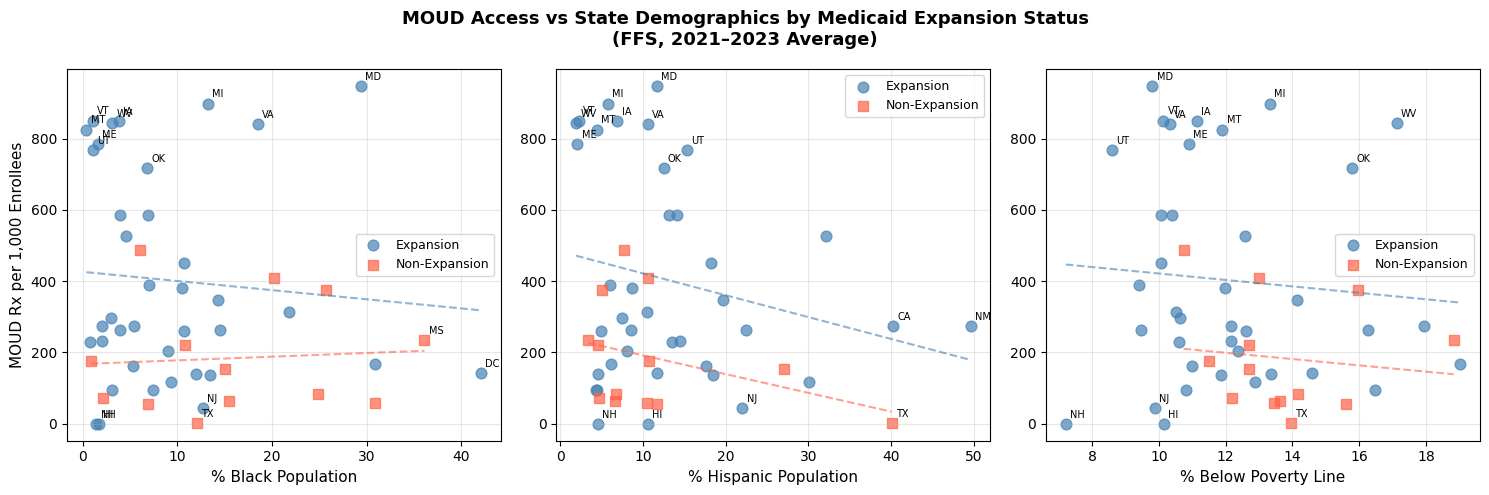

Saved.


In [149]:
import matplotlib.pyplot as plt
import numpy as np

state_summary = wide_demo.groupby(['State','medicaid_expansion']).agg(
    moud_share  = ('moud_share',  'mean'),
    pct_black   = ('pct_black',   'mean'),
    pct_hispanic= ('pct_hispanic','mean'),
    pct_poverty = ('pct_poverty', 'mean')
).reset_index()

state_summary['moud_per_1k'] = state_summary['moud_share'] * 1000

exp   = state_summary[state_summary['medicaid_expansion']==1]
nonexp= state_summary[state_summary['medicaid_expansion']==0]

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
fig.suptitle('MOUD Access vs State Demographics by Medicaid Expansion Status\n(FFS, 2021–2023 Average)', fontsize=13, fontweight='bold')

vars_info = [
    ('pct_black',    '% Black Population'),
    ('pct_hispanic', '% Hispanic Population'),
    ('pct_poverty',  '% Below Poverty Line'),
]

for ax, (var, xlabel) in zip(axes, vars_info):
    ax.scatter(exp[var],    exp['moud_per_1k'],    color='steelblue', alpha=0.7, label='Expansion',     s=60)
    ax.scatter(nonexp[var], nonexp['moud_per_1k'], color='tomato',    alpha=0.7, label='Non-Expansion', s=60, marker='s')

    # Add state labels for outliers
    for _, row in state_summary.iterrows():
        if row['moud_per_1k'] > 700 or row['moud_per_1k'] < 50 or row[var] > 35:
            ax.annotate(row['State'], (row[var], row['moud_per_1k']),
                        fontsize=7, ha='left', va='bottom',
                        xytext=(3, 3), textcoords='offset points')

    # Trend lines
    for grp, color in [(exp,'steelblue'), (nonexp,'tomato')]:
        m, b = np.polyfit(grp[var], grp['moud_per_1k'], 1)
        x_range = np.linspace(grp[var].min(), grp[var].max(), 100)
        ax.plot(x_range, m*x_range + b, color=color, linewidth=1.5, linestyle='--', alpha=0.6)

    ax.set_xlabel(xlabel, fontsize=11)
    ax.set_ylabel('MOUD Rx per 1,000 Enrollees' if var=='pct_black' else '', fontsize=11)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('../Outputs/moud_demographic_scatter.png', dpi=150, bbox_inches='tight')
plt.show()
print("Saved.")

In [150]:
from scipy.stats import spearmanr

print("── Spearman correlations: MOUD per 1k vs demographics ──\n")
for var, label in [('pct_black','% Black'), ('pct_hispanic','% Hispanic'), ('pct_poverty','% Poverty')]:
    for name, grp in [('All states', state_summary), ('Expansion only', exp), ('Non-expansion only', nonexp)]:
        r, p = spearmanr(grp[var], grp['moud_per_1k'])
        sig = '*' if p < 0.05 else ''
        print(f"  {label} | {name:20s}: r={r:+.3f}  p={p:.3f} {sig}")
    print()

── Spearman correlations: MOUD per 1k vs demographics ──

  % Black | All states          : r=-0.146  p=0.306 
  % Black | Expansion only      : r=-0.089  p=0.593 
  % Black | Non-expansion only  : r=+0.082  p=0.789 

  % Hispanic | All states          : r=-0.097  p=0.500 
  % Hispanic | Expansion only      : r=-0.157  p=0.346 
  % Hispanic | Non-expansion only  : r=-0.396  p=0.181 

  % Poverty | All states          : r=-0.218  p=0.124 
  % Poverty | Expansion only      : r=-0.113  p=0.499 
  % Poverty | Non-expansion only  : r=-0.242  p=0.426 



In [151]:
# Full state table — sorted by MOUD access within expansion group
print("── NON-EXPANSION STATES (sorted by MOUD per 1k) ──")
nonexp_detail = state_summary[state_summary['medicaid_expansion']==0][
    ['State','moud_per_1k','pct_black','pct_hispanic','pct_poverty']
].sort_values('moud_per_1k', ascending=False)
print(nonexp_detail.to_string(index=False))

print("\n── EXPANSION STATES (bottom 10 by MOUD per 1k) ──")
exp_detail = state_summary[state_summary['medicaid_expansion']==1][
    ['State','moud_per_1k','pct_black','pct_hispanic','pct_poverty']
].sort_values('moud_per_1k').head(10)
print(exp_detail.to_string(index=False))

── NON-EXPANSION STATES (sorted by MOUD per 1k) ──
State  moud_per_1k  pct_black  pct_hispanic  pct_poverty
   WI   486.310094   6.033333      7.733333    10.733333
   NC   408.930461  20.200000     10.633333    13.000000
   AL   374.851519  25.666667      5.100000    15.966667
   MS   235.323907  36.100000      3.400000    18.833333
   MO   220.786445  10.800000      4.600000    12.700000
   WY   174.829195   0.866667     10.733333    11.500000
   FL   152.919011  15.000000     27.100000    12.700000
   SC    84.378806  24.833333      6.733333    14.166667
   SD    73.159995   2.166667      4.666667    12.200000
   TN    64.910827  15.466667      6.600000    13.633333
   GA    57.645671  30.866667     10.500000    13.433333
   OK    55.369156   6.900000     11.700000    15.600000
   TX     3.026924  12.100000     40.066667    13.966667

── EXPANSION STATES (bottom 10 by MOUD per 1k) ──
State  moud_per_1k  pct_black  pct_hispanic  pct_poverty
   NH     0.000000   1.466667      4.500000

In [154]:
# Check the notes/metadata in your CDC file footer
df_cdc_raw = pd.read_csv('../Data/cdc_drug_overdose_county_2018_2024.csv', nrows=5)
print(df_cdc_raw)

   Notes    State  State Code              County  County Code  Year  Year Code  Deaths  Population  Crude Rate  \
0    NaN  Alabama           1  Autauga County, AL         1001  2021       2021      10       59095        16.9   
1    NaN  Alabama           1  Autauga County, AL         1001  2022       2022      10       59759        16.7   
2    NaN  Alabama           1  Autauga County, AL         1001  2023       2023      10       60342        16.6   
3    NaN  Alabama           1  Baldwin County, AL         1003  2018       2018      29      218022        13.3   
4    NaN  Alabama           1  Baldwin County, AL         1003  2019       2019      32      223234        14.3   

   Crude Rate Lower 95% Confidence Interval  Crude Rate Upper 95% Confidence Interval  
0                                       8.1                                      31.1  
1                                       8.0                                      30.8  
2                                       7.9  

In [155]:
# Read the bottom of the file where CDC WONDER stores query parameters
df_cdc_full = pd.read_csv('../Data/cdc_drug_overdose_county_2018_2024.csv', header=None)
print(df_cdc_full.tail(40).to_string())

                                                                                                                                    0    1    2    3    4    5    6    7    8    9    10   11
8416                         4. Data are Suppressed when the data meet the criteria for confidentiality constraints. More information:  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
8417                                                 http://wonder.cdc.gov/wonder/help/ucd-expanded.html#Assurance of Confidentiality.  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
8418                                    5. The method used to calculate 95% confidence intervals is documented here: More information:  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
8419                                                         http://wonder.cdc.gov/wonder/help/ucd-expanded.html#Confidence-Intervals.  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN  NaN
8420        6. The population figures for year 202

In [156]:
# Find which state/year has pop=0 or missing
print(cdc_state[cdc_state['od_rate'].replace([np.inf, -np.inf], np.nan).isna()][['State','Year','deaths','pop','od_rate']])

# Also check for zero population
print(cdc_state[cdc_state['pop'] == 0])

Empty DataFrame
Columns: [State, Year, deaths, pop, od_rate]
Index: []
Empty DataFrame
Columns: [State, Year, deaths, pop, od_rate]
Index: []


In [157]:
import numpy as np

# Find the inf rows in cdc_state
print(cdc_state[np.isinf(cdc_state['od_rate'])][['State','Year','deaths','pop','od_rate']])

# Also check od_exp (the merged dataframe used in OD analysis)
print(od_exp[np.isinf(od_exp['od_rate'])][['State','Year','deaths','pop','od_rate','medicaid_expansion']])

Empty DataFrame
Columns: [State, Year, deaths, pop, od_rate]
Index: []
Empty DataFrame
Columns: [State, Year, deaths, pop, od_rate, medicaid_expansion]
Index: []


In [158]:
# Check what's actually in od_exp for expansion states 2022/2023
print(od_exp[od_exp['medicaid_expansion']==1].groupby('Year')['od_rate'].describe())

# Check for any non-numeric values
print(od_exp['od_rate'].dtype)
print(od_exp['od_rate'].unique()[:20])

      count       mean        std        min        25%        50%        75%        max
Year                                                                                    
2021   37.0  38.395844  15.679875  14.960016  29.616691  33.937152  45.353424  94.769763
2022   39.0  38.205083  14.185775  16.973085  30.410712  37.562676  43.122537  86.514768
2023   39.0  37.480182  14.181488  11.048215  30.106193  36.745195  45.174240  86.148254
float64
[34.25494664 34.24013262 36.42269446 38.72794895 38.76225984 52.80745485
 39.28002798 38.21323148 37.21683158 23.83566601 24.53755053 19.33325928
 29.03853525 29.20560597 30.39711617 34.243222   33.12875338 33.82017045
 44.31998363 42.3508229 ]


In [159]:
# Re-run the summary using od_exp directly — which we know is clean
print("=== OD rate by expansion status ===")
print(od_exp.groupby('medicaid_expansion')['od_rate'].agg(['mean','median','count']))

print("\n=== OD rate by expansion + year ===")
print(od_exp.groupby(['medicaid_expansion','Year'])['od_rate'].mean().unstack('Year'))

=== OD rate by expansion status ===
                         mean     median  count
medicaid_expansion                             
0                   33.437123  33.980051     38
1                   38.020622  35.902256    115

=== OD rate by expansion + year ===
Year                     2021       2022       2023
medicaid_expansion                                 
0                   33.707809  33.587445  32.971001
1                   38.395844  38.205083  37.480182


In [160]:
with open('../Data/cdc_drug_overdose_county_2018_2024.csv', 'r') as f:
    content = f.read()
print(content[-3000:])

age 2022 postcensal series released by the Census Bureau"
"on June 22, 2023. The 2022 series is based on the Modified Blended Base produced by the US Census Bureau in lieu of the April 1,"
"2020 decennial population count. The Modified Blended Base consists of the blend of Vintage 2020 postcensal population estimates"
"for April 1, 2020, 2020 Demographic Analysis Estimates, and 2020 Census data from the internal Census Edited File (CEF). The"
"population figures for years 2021 are single-race estimates of the July 1 resident population, based on the Blended Base"
"produced by the US Census Bureau in lieu of the April 1, 2020 decennial population count, from the Vintage 2021 postcensal"
"series released by the Census Bureau on June 30, 2022. The population figures for year 2020 are single-race estimates of the"
"July 1 resident population, from the Vintage 2020 postcensal series based on April 2010 Census, released by the Census Bureau on"
"July 27, 2021. The population figures for year

In [161]:
# Pre-period trend test 2018-2020
pre = cdc_state[cdc_state['Year'].isin([2018, 2019, 2020])].merge(
    expansion_tv[expansion_tv['Year']==2021][['State','medicaid_expansion']],
    on='State', how='inner'
)

import statsmodels.formula.api as smf
model_pre = smf.ols(
    'od_rate ~ Year * medicaid_expansion',
    data=pre
).fit()

coef = model_pre.params['Year:medicaid_expansion']
pval = model_pre.pvalues['Year:medicaid_expansion']
print(f"Pre-period Year × Expansion interaction: coef={coef:.4f}, p={pval:.4f}")
print("Parallel trends assumption:", "HOLDS ✅" if pval > 0.05 else "VIOLATED ❌")

ValueError: zero-size array to reduction operation maximum which has no identity

In [162]:
# Rebuild cdc_state with full 2018-2023 range
df_cdc_raw = pd.read_csv('../Data/cdc_drug_overdose_county_2018_2024.csv')

# Clean up
df_cdc_raw = df_cdc_raw[df_cdc_raw['Notes'].isna()].copy()
df_cdc_raw = df_cdc_raw[df_cdc_raw['Deaths'] != 'Suppressed'].copy()
df_cdc_raw['Deaths'] = pd.to_numeric(df_cdc_raw['Deaths'], errors='coerce')
df_cdc_raw['Population'] = pd.to_numeric(df_cdc_raw['Population'], errors='coerce')
df_cdc_raw['Year'] = pd.to_numeric(df_cdc_raw['Year Code'], errors='coerce').astype('Int64')

# Filter 2018-2023 (keep pre-period for parallel trends)
df_cdc_raw = df_cdc_raw[df_cdc_raw['Year'].between(2018, 2023)]

# Aggregate to state level
cdc_state_full = df_cdc_raw.groupby(['State', 'Year']).agg(
    deaths=('Deaths', 'sum'),
    pop=('Population', 'sum')
).reset_index()
cdc_state_full['od_rate'] = cdc_state_full['deaths'] / cdc_state_full['pop'] * 100000

# Map full state names to abbreviations
state_map_full = {
    'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','Florida':'FL','Georgia':'GA',
    'Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA',
    'Kansas':'KS','Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD',
    'Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS',
    'Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV','New Hampshire':'NH',
    'New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC',
    'North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA',
    'Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD','Tennessee':'TN',
    'Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA','Washington':'WA',
    'West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY','District of Columbia':'DC'
}
cdc_state_full['State'] = cdc_state_full['State'].map(state_map_full)
cdc_state_full = cdc_state_full.dropna(subset=['State'])

print(cdc_state_full['Year'].unique())
print(cdc_state_full.shape)

# Now run parallel trends test on 2018-2020
pre = cdc_state_full[cdc_state_full['Year'].isin([2018, 2019, 2020])].merge(
    expansion_tv[expansion_tv['Year']==2021][['State','medicaid_expansion']],
    on='State', how='inner'
)

import statsmodels.formula.api as smf
model_pre = smf.ols('od_rate ~ Year * medicaid_expansion', data=pre).fit()

coef = model_pre.params['Year:medicaid_expansion']
pval = model_pre.pvalues['Year:medicaid_expansion']
print(f"\nPre-period Year × Expansion interaction: coef={coef:.4f}, p={pval:.4f}")
print("Parallel trends assumption:", "HOLDS ✅" if pval > 0.05 else "VIOLATED ❌")

<IntegerArray>
[2018, 2019, 2020, 2021, 2022, 2023]
Length: 6, dtype: Int64
(306, 5)

Pre-period Year × Expansion interaction: coef=-0.2642, p=0.9130
Parallel trends assumption: HOLDS ✅


In [164]:
# 1. Pain drug composition — top 10 by total Rx volume (from df_ffs)
pain_breakdown = (
    df_ffs[df_ffs['opioid_class'] == 'PAIN']
    .groupby('PRODUCT_NAME_U')['Number of Prescriptions']
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)
pain_breakdown['pct_of_pain'] = (
    pain_breakdown['Number of Prescriptions'] / 
    pain_breakdown['Number of Prescriptions'].sum() * 100
).round(1)
print(pain_breakdown.to_string(index=False))

print("\n")

# 2. Pain Rx per 1k enrollee by expansion status
pain_state = (
    df_ffs[df_ffs['opioid_class'] == 'PAIN']
    .groupby(['State', 'Year'])['Number of Prescriptions']
    .sum()
    .reset_index()
    .rename(columns={'Number of Prescriptions': 'rx_pain'})
)

pain_exp = pain_state.merge(
    wide_c[['State', 'Year', 'medicaid_expansion']].drop_duplicates(),
    on=['State', 'Year'], how='inner'
).merge(
    enrollment[['State', 'Year', 'enrollment']],
    on=['State', 'Year'], how='inner'
)

pain_exp['pain_per_1k'] = pain_exp['rx_pain'] / pain_exp['enrollment'] * 1000

print("Pain Rx per 1k by expansion status:")
print(pain_exp.groupby('medicaid_expansion')['pain_per_1k'].describe().round(1))

PRODUCT_NAME_U  Number of Prescriptions  pct_of_pain
     OXYCODONE                3482563.0         39.8
    TRAMADOL H                2346808.0         26.8
    OXYCODONE-                1247105.0         14.3
    MORPHINE S                 787351.0          9.0
    FENTANYL C                 364856.0          4.2
    CODEINE PH                 320752.0          3.7
    OXYCODONE/                  54833.0          0.6
      FENTANYL                  51640.0          0.6
    TRAMADOL T                  48483.0          0.6
    FENTANYL T                  47179.0          0.5


Pain Rx per 1k by expansion status:
                    count  mean   std  min   25%   50%    75%    max
medicaid_expansion                                                  
0                    35.0  60.0  47.2  0.8  12.1  64.2   95.3  163.6
1                   111.0  50.3  64.1  0.0   2.7  10.7  110.7  228.7


In [165]:
# Classify pain drugs as short-acting vs long-acting
short_acting = ['TRAMADOL', 'OXYCODONE', 'HYDROCODONE', 'CODEINE']
long_acting   = ['MORPHINE S', 'FENTANYL', 'HYDROMORPHONE', 'OXYMORPHONE', 
                 'METHADONE']  # methadone for pain, not MOUD

def classify_duration(name):
    name = str(name).upper()
    # Long-acting keywords
    if any(x in name for x in ['MORPHINE', 'FENTANYL', 'HYDROMORPHONE', 
                                 'OXYMORPHONE', 'ER', 'XR', 'CR', 'LA ', 
                                 'EXTENDED', 'SUSTAINED', 'CONTIN']):
        return 'long_acting'
    # Short-acting keywords  
    if any(x in name for x in ['TRAMADOL', 'OXYCODONE', 'HYDROCODONE', 
                                 'CODEINE']):
        return 'short_acting'
    return 'other'

pain_df = df_ffs[df_ffs['opioid_class'] == 'PAIN'].copy()
pain_df['duration'] = pain_df['PRODUCT_NAME_U'].apply(classify_duration)

duration_summary = (
    pain_df.groupby('duration')['Number of Prescriptions']
    .sum()
    .reset_index()
)
duration_summary['pct'] = (
    duration_summary['Number of Prescriptions'] / 
    duration_summary['Number of Prescriptions'].sum() * 100
).round(1)
print(duration_summary.sort_values('Number of Prescriptions', ascending=False).to_string(index=False))

    duration  Number of Prescriptions  pct
short_acting                7569888.0 85.0
 long_acting                1331437.0 15.0


In [167]:
# Aggregate to state-year-duration first, then get median across states
pain_state_duration = (
    pain_exp_duration.groupby(['State', 'Year', 'medicaid_expansion', 'duration'])
    .agg(rx=('Number of Prescriptions', 'sum'),
         enrollment=('enrollment', 'first'))
    .reset_index()
)

pain_state_duration['rx_per_1k'] = (
    pain_state_duration['rx'] / pain_state_duration['enrollment'] * 1000
)

result = (
    pain_state_duration.groupby(['medicaid_expansion', 'duration'])['rx_per_1k']
    .median()
    .round(1)
    .unstack('duration')
)
print(result)

duration            long_acting  short_acting
medicaid_expansion                           
0                          10.0          54.4
1                           1.9           9.0


In [168]:
# MOUD share trend by year and expansion status
trend = (
    wide_c.groupby(['Year', 'medicaid_expansion'])['moud_share']
    .median()
    .round(3)
    .unstack('medicaid_expansion')
    .rename(columns={0: 'Non-expansion', 1: 'Expansion'})
)
trend['ratio'] = (trend['Expansion'] / trend['Non-expansion']).round(2)
print(trend)

print("\n")

# Pain prescribing trend by year and expansion status
pain_trend = (
    pain_state_duration.groupby(['Year', 'medicaid_expansion'])['rx_per_1k']
    .median()
    .round(1)
    .unstack('medicaid_expansion')
    .rename(columns={0: 'Non-expansion', 1: 'Expansion'})
)
print("Pain Rx per 1k trend by year:")
print(pain_trend)

medicaid_expansion  Non-expansion  Expansion  ratio
Year                                               
2021                        0.118      0.247   2.09
2022                        0.156      0.294   1.88
2023                        0.185      0.321   1.74


Pain Rx per 1k trend by year:
medicaid_expansion  Non-expansion  Expansion
Year                                        
2021                         16.6        3.2
2022                         11.9        2.9
2023                         11.1        4.1


In [169]:
# Absolute MOUD Rx per 1k by year and expansion — not share
moud_trend = (
    wide_c.groupby(['Year', 'medicaid_expansion'])['moud_per_1k']
    .median()
    .round(2)
    .unstack('medicaid_expansion')
    .rename(columns={0: 'Non-expansion', 1: 'Expansion'})
)
moud_trend['ratio'] = (moud_trend['Expansion'] / moud_trend['Non-expansion']).round(2)
print(moud_trend)

medicaid_expansion  Non-expansion  Expansion  ratio
Year                                               
2021                         5.41       7.51   1.39
2022                         7.99       8.19   1.03
2023                         7.31       9.81   1.34


In [170]:
from scipy.stats import mannwhitneyu

exp_1k   = wide_c[wide_c['medicaid_expansion']==1]['moud_per_1k'].dropna()
nonexp_1k = wide_c[wide_c['medicaid_expansion']==0]['moud_per_1k'].dropna()

stat, p = mannwhitneyu(exp_1k, nonexp_1k, alternative='greater')
ratio = exp_1k.median() / nonexp_1k.median()

print(f"Expansion median moud_per_1k:     {exp_1k.median():.3f}")
print(f"Non-expansion median moud_per_1k: {nonexp_1k.median():.3f}")
print(f"Ratio: {ratio:.2f}x")
print(f"Mann-Whitney p: {p:.4f}")

Expansion median moud_per_1k:     8.494
Non-expansion median moud_per_1k: 6.193
Ratio: 1.37x
Mann-Whitney p: 0.2268


In [173]:
def get_drug_class(name):
    name = str(name).upper()
    if 'BUPRENORPHINE' in name or any(x in name for x in ['SUBOXONE','SUBUTEX','ZUBSOLV','BUNAVAIL','SUBLOCADE','BRIXIV']):
        return 'BUPRENORPHINE'
    if 'NALTREXONE' in name:
        return 'NALTREXONE'
    if 'METHADONE' in name:
        return 'METHADONE'
    return None

moud_df = df_ffs[df_ffs['opioid_class'] == 'MOUD'].copy()
moud_df['drug_class'] = moud_df['PRODUCT_NAME_U'].apply(get_drug_class)

for drug in ['BUPRENORPHINE', 'NALTREXONE', 'METHADONE']:
    drug_state = (
        moud_df[moud_df['drug_class'] == drug]
        .groupby(['State', 'Year'])['Number of Prescriptions']
        .sum().reset_index()
        .merge(wide_c[['State','Year','medicaid_expansion']].drop_duplicates(), on=['State','Year'])
        .merge(enrollment[['State','Year','enrollment']], on=['State','Year'])
    )
    drug_state['per_1k'] = drug_state['Number of Prescriptions'] / drug_state['enrollment'] * 1000
    
    exp = drug_state[drug_state['medicaid_expansion']==1]['per_1k'].dropna()
    non = drug_state[drug_state['medicaid_expansion']==0]['per_1k'].dropna()
    stat, p = mannwhitneyu(exp, non, alternative='greater')
    print(f"{drug}: exp={exp.median():.3f} non={non.median():.3f} ratio={exp.median()/non.median():.2f}x p={p:.4f}")

BUPRENORPHINE: exp=3.636 non=2.330 ratio=1.56x p=0.2431
NALTREXONE: exp=1.729 non=1.914 ratio=0.90x p=0.2740
METHADONE: exp=0.092 non=0.102 ratio=0.90x p=0.2838


In [172]:
print(df_ffs['opioid_class'].unique())

['PAIN' 'MOUD']


In [179]:
import pandas as pd
import numpy as np
import zipfile, io

def read_xlsx_from_zip(zip_path, xlsx_name, sheet_name):
    with zipfile.ZipFile(zip_path) as z:
        # find the xlsx inside
        matches = [f for f in z.namelist() if f.endswith('.xlsx')]
        print(zip_path, '->', matches)
        with z.open(matches[0]) as f:
            return pd.read_excel(io.BytesIO(f.read()), sheet_name=sheet_name)

nal  = read_xlsx_from_zip('../Data/RAND_EP68090-NAL.zip',  None, 'WEB_NAL_1990-2023')
gsl  = read_xlsx_from_zip('../Data/RAND_EP68218-GSL.zip',  None, 'WEB_GSL_2021')
pdmp = read_xlsx_from_zip('../Data/RAND_EP68218-PDMP.zip', None, 'PDMP')

nal_sub  = nal[nal['year'].between(2021,2023)][['state','year','nal_protocol_standing']].copy()
pdmp_sub = pdmp[pdmp['year'].between(2021,2023)][['state','year','mustaccess']].copy()
pdmp_sub['mustaccess'] = (pdmp_sub['mustaccess'] >= 1.0).astype(int)

gsl_2021 = gsl[gsl['year']==2021][['state','anygsl']].copy()
gsl_rows = []
for yr in [2021,2022,2023]:
    tmp = gsl_2021.copy(); tmp['year'] = yr; gsl_rows.append(tmp)
gsl_panel = pd.concat(gsl_rows)

policy = nal_sub.merge(pdmp_sub, on=['state','year']).merge(gsl_panel, on=['state','year'])

# --- Merge with your panel ---
merged = wide_c.merge(policy, left_on=['State','Year'], right_on=['state','year'], how='left')

print(merged[['State','Year','moud_share','medicaid_expansion',
              'mustaccess','nal_protocol_standing','anygsl']].head(9))
print('\nMissing:', merged[['mustaccess','nal_protocol_standing','anygsl']].isna().sum())

../Data/RAND_EP68090-NAL.zip -> ['NAL/WEB_NAL_1990-2023.xlsx']
../Data/RAND_EP68218-GSL.zip -> ['GSL/WEB_GSL_1990-2021.xlsx']
../Data/RAND_EP68218-PDMP.zip -> ['PDMP July 2026/WEB_PDMP_1990-2023_updated2026.xlsx', '__MACOSX/PDMP July 2026/._WEB_PDMP_1990-2023_updated2026.xlsx']
  State  Year  moud_share  medicaid_expansion  mustaccess  nal_protocol_standing  anygsl
0    AK  2021    0.247198                   1           1                    1.0     1.0
1    AK  2022    0.298458                   1           1                    1.0     1.0
2    AK  2023    0.346273                   1           1                    1.0     1.0
3    AL  2021    0.350180                   0           1                    1.0     1.0
4    AL  2022    0.385557                   0           1                    1.0     1.0
5    AL  2023    0.388817                   0           1                    1.0     1.0
6    AR  2021    0.199266                   1           1                    1.0     1.0
7    AR  

In [180]:
from scipy import stats

# Year dummies for fixed effects
merged['yr2022'] = (merged['Year'] == 2022).astype(int)
merged['yr2023'] = (merged['Year'] == 2023).astype(int)

# Build design matrix
X = merged[['medicaid_expansion','mustaccess','nal_protocol_standing','anygsl','yr2022','yr2023']].copy()
X.insert(0, 'const', 1)
y = merged['moud_share']

X_arr = X.values.astype(float)
y_arr = y.values.astype(float)

# OLS via numpy
beta, res, rank, sv = np.linalg.lstsq(X_arr, y_arr, rcond=None)
y_hat = X_arr @ beta
residuals = y_arr - y_hat
n, k = X_arr.shape
sigma2 = (residuals @ residuals) / (n - k)
var_beta = sigma2 * np.linalg.inv(X_arr.T @ X_arr)
se = np.sqrt(np.diag(var_beta))
t_stats = beta / se
p_vals = 2 * stats.t.sf(np.abs(t_stats), df=n-k)
r2 = 1 - (residuals @ residuals) / ((y_arr - y_arr.mean()) @ (y_arr - y_arr.mean()))

print(f"OLS Results: moud_share ~ expansion + mustaccess + naloxone_standing + good_samaritan + year_FE")
print(f"N={n}, R²={r2:.3f}\n")
print(f"{'Variable':<25} {'Coef':>8} {'SE':>8} {'t':>7} {'p':>8}")
print("-"*60)
for i, var in enumerate(X.columns):
    sig = '***' if p_vals[i]<0.001 else '**' if p_vals[i]<0.01 else '*' if p_vals[i]<0.05 else ''
    print(f"{var:<25} {beta[i]:>8.4f} {se[i]:>8.4f} {t_stats[i]:>7.2f} {p_vals[i]:>8.4f} {sig}")

OLS Results: moud_share ~ expansion + mustaccess + naloxone_standing + good_samaritan + year_FE
N=146, R²=0.112

Variable                      Coef       SE       t        p
------------------------------------------------------------
const                       0.0416   0.1712    0.24   0.8084 
medicaid_expansion          0.1896   0.0587    3.23   0.0016 **
mustaccess                  0.0359   0.0655    0.55   0.5839 
nal_protocol_standing      -0.0039   0.1189   -0.03   0.9741 
anygsl                      0.1307   0.1263    1.03   0.3025 
yr2022                      0.0076   0.0569    0.13   0.8934 
yr2023                      0.0382   0.0569    0.67   0.5028 


In [181]:
print(merged[['mustaccess','nal_protocol_standing','anygsl']].describe())

       mustaccess  nal_protocol_standing      anygsl
count  146.000000             146.000000  146.000000
mean     0.842466               0.958904    0.958904
std      0.365558               0.199195    0.199195
min      0.000000               0.000000    0.000000
25%      1.000000               1.000000    1.000000
50%      1.000000               1.000000    1.000000
75%      1.000000               1.000000    1.000000
max      1.000000               1.000000    1.000000


In [182]:
print(merged.shape)
print(wide_c.shape)
print(merged[merged['mustaccess'].isna()])

(146, 16)
(146, 9)
Empty DataFrame
Columns: [State, Year, rx_MOUD, rx_PAIN, medicaid_expansion, enrollment, moud_share, moud_per_1k, Year_c, state, year, nal_protocol_standing, mustaccess, anygsl, yr2022, yr2023]
Index: []


In [183]:
print(merged.groupby('medicaid_expansion')[['rx_MOUD','rx_PAIN','moud_share','moud_per_1k']].mean())

                         rx_MOUD       rx_PAIN  moud_share  moud_per_1k
medicaid_expansion                                                     
0                   30884.285714  70352.542857    0.189286    23.221643
1                   71759.171171  58008.432432    0.404609   104.127497


In [185]:
from scipy import stats

results = []
for s in merged['State'].unique():
    sub = merged[merged['State'] != s].copy()
    X = sub[['medicaid_expansion','mustaccess','nal_protocol_standing','anygsl','yr2022','yr2023']].copy()
    X.insert(0, 'const', 1)
    y = sub['moud_share'].values
    X_arr = X.values.astype(float)
    beta, _, _, _ = np.linalg.lstsq(X_arr, y, rcond=None)
    residuals = y - X_arr @ beta
    n, k = X_arr.shape
    sigma2 = (residuals @ residuals) / (n - k)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X_arr.T @ X_arr)))
    t = beta[1] / se[1]
    p = 2 * stats.t.sf(abs(t), df=n-k)
    results.append({'dropped': s, 'coef': beta[1], 'p': p})

jk = pd.DataFrame(results).sort_values('coef')
print(jk[['dropped','coef','p']].to_string())
print(f"\nCoef range: {jk['coef'].min():.4f} to {jk['coef'].max():.4f}")
print(f"All p<0.05: {(jk['p'] < 0.05).all()}")
print(f"States where p>=0.05: {jk[jk['p']>=0.05]['dropped'].tolist()}")

   dropped      coef         p
10      GA  0.169962  0.006906
42      UT  0.170193  0.004103
40      TN  0.170862  0.006643
38      SC  0.173201  0.005996
19      MD  0.175459  0.002523
25      MT  0.175707  0.002949
21      MI  0.176775  0.002534
39      SD  0.176940  0.004683
44      VT  0.177953  0.002531
12      IA  0.178036  0.002527
47      WV  0.178164  0.002526
43      VA  0.178383  0.002505
20      ME  0.179747  0.002489
9       FL  0.181533  0.004100
18      MA  0.184934  0.002205
45      WA  0.185057  0.002189
34      OK  0.186088  0.002306
3       AZ  0.186648  0.002056
6       CT  0.188419  0.001906
41      TX  0.189522  0.001720
48      WY  0.189614  0.001710
22      MN  0.190096  0.001746
36      PA  0.190351  0.001721
32      NY  0.190989  0.001631
0       AK  0.192543  0.001500
4       CA  0.192692  0.001420
8       DE  0.193071  0.001177
30      NM  0.193121  0.001441
5       CO  0.193375  0.001414
2       AR  0.193485  0.001403
23      MO  0.194501  0.001527
15      

In [187]:
import pandas as pd
import os

years = [2019, 2020, 2024, 2025]
for yr in years:
    df = pd.read_csv(f'../Data/utilization_{yr}.csv')
    print(f"{yr}: {len(df)} rows, quarters: {sorted(df['Quarter'].unique())}")

2019: 4983002 rows, quarters: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
2020: 4934701 rows, quarters: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
2024: 5308407 rows, quarters: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
2025: 5308547 rows, quarters: [np.int64(1), np.int64(2), np.int64(3), np.int64(4)]


In [189]:
df_2024 = pd.read_csv('../Data/utilization_2024.csv')
df_2025 = pd.read_csv('../Data/utilization_2025.csv')
print("2024 date range:", df_2024['Quarter'].value_counts().sort_index())
print("2025 date range:", df_2025['Quarter'].value_counts().sort_index())
print("\n2024 sample:", df_2024[['Year','Quarter']].drop_duplicates().sort_values(['Year','Quarter']))
print("2025 sample:", df_2025[['Year','Quarter']].drop_duplicates().sort_values(['Year','Quarter']))

2024 date range: Quarter
1    1326779
2    1326224
3    1331155
4    1324249
Name: count, dtype: int64
2025 date range: Quarter
1    1332383
2    1326451
3    1326790
4    1322923
Name: count, dtype: int64

2024 sample:        Year  Quarter
33319  2024        1
22256  2024        2
11317  2024        3
0      2024        4
2025 sample:        Year  Quarter
49400  2025        1
37897  2025        2
21772  2025        3
0      2025        4


In [190]:
enr = pd.read_csv('../Data/enrollment_2021.csv')
print(enr.columns.tolist())
print(enr.head(3))

['State Abbreviation', 'State Name', 'Reporting Period', 'State Expanded Medicaid', 'Preliminary or Updated', 'Final Report', 'New Applications Submitted to Medicaid and CHIP Agencies', 'New Applications Submitted to Medicaid and CHIP Agencies - footnotes', 'Applications for Financial Assistance Submitted to the State Based Marketplace', 'Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes', 'Total Applications for Financial Assistance Submitted at State Level', 'Total Applications for Financial Assistance Submitted at State Level - footnotes', 'Individuals Determined Eligible for Medicaid at Application', 'Individuals Determined Eligible for Medicaid at Application - footnotes', 'Individuals Determined Eligible for CHIP at Application', 'Individuals Determined Eligible for CHIP at Application - footnotes', 'Total Medicaid and CHIP Determinations', 'Total Medicaid and CHIP Determinations - footnotes', 'Medicaid and CHIP Child Enrollment', 'Medicai

In [191]:
enr = pd.read_csv('../Data/enrollment_2021.csv')
print(enr.columns.tolist())
print(enr.head(3))
print(enr.shape)

['State Abbreviation', 'State Name', 'Reporting Period', 'State Expanded Medicaid', 'Preliminary or Updated', 'Final Report', 'New Applications Submitted to Medicaid and CHIP Agencies', 'New Applications Submitted to Medicaid and CHIP Agencies - footnotes', 'Applications for Financial Assistance Submitted to the State Based Marketplace', 'Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes', 'Total Applications for Financial Assistance Submitted at State Level', 'Total Applications for Financial Assistance Submitted at State Level - footnotes', 'Individuals Determined Eligible for Medicaid at Application', 'Individuals Determined Eligible for Medicaid at Application - footnotes', 'Individuals Determined Eligible for CHIP at Application', 'Individuals Determined Eligible for CHIP at Application - footnotes', 'Total Medicaid and CHIP Determinations', 'Total Medicaid and CHIP Determinations - footnotes', 'Medicaid and CHIP Child Enrollment', 'Medicai

In [194]:
import pandas as pd
enr = pd.read_csv('../Data/enrollment_2026.csv')
print(enr.columns.tolist())
print(enr['Reporting Period'].astype(str).str[:4].value_counts().sort_index())

['State Abbreviation', 'State Name', 'Reporting Period', 'State Expanded Medicaid', 'Preliminary or Updated', 'Final Report', 'New Applications Submitted to Medicaid and CHIP Agencies', 'New Applications Submitted to Medicaid and CHIP Agencies - footnotes', 'Applications for Financial Assistance Submitted to the State Based Marketplace', 'Applications for Financial Assistance Submitted to the State Based Marketplace - footnotes', 'Total Applications for Financial Assistance Submitted at State Level', 'Total Applications for Financial Assistance Submitted at State Level - footnotes', 'Individuals Determined Eligible for Medicaid at Application', 'Individuals Determined Eligible for Medicaid at Application - footnotes', 'Individuals Determined Eligible for CHIP at Application', 'Individuals Determined Eligible for CHIP at Application - footnotes', 'Total Medicaid and CHIP Determinations', 'Total Medicaid and CHIP Determinations - footnotes', 'Medicaid and CHIP Child Enrollment', 'Medicai

In [193]:
enr_2025 = enr[enr['Reporting Period'].astype(str).str[:4] == '2025']
print(sorted(enr_2025['Reporting Period'].astype(str).str[-2:].unique()))
print(enr_2025['Reporting Period'].value_counts().sort_index())

['01', '02', '03', '04', '05', '06', '07', '08', '09']
Reporting Period
202501    102
202502    102
202503    102
202504    102
202505    102
202506    102
202507    102
202508    102
202509     51
Name: count, dtype: int64


In [195]:
# Keep only Final Report = Y (updated), or last record per state-month if no Final
import pandas as pd
import numpy as np
from scipy import stats
import zipfile, io

# ── 1. ENROLLMENT ──────────────────────────────────────────────────────────
enr_raw = pd.read_csv('../Data/enrollment_2026.csv')
enr_raw['year'] = enr_raw['Reporting Period'].astype(str).str[:4].astype(int)

# Keep only Final Report = Y to avoid double-counting preliminary + updated
enr_final = enr_raw[enr_raw['Final Report'] == 'Y'].copy()

# Annual average enrollment per state (use 2019-2025 only)
enr_annual = (enr_final[enr_final['year'].between(2019, 2025)]
              .groupby(['State Abbreviation', 'year'])['Total Medicaid Enrollment']
              .mean()
              .reset_index())
enr_annual.columns = ['State', 'Year', 'enrollment']
print("Enrollment shape:", enr_annual.shape)
print(enr_annual.head())

Enrollment shape: (357, 3)
  State  Year     enrollment
0    AK  2019  204683.583333
1    AK  2020  217147.583333
2    AK  2021  236946.250000
3    AK  2022  249174.166667
4    AK  2023  245392.416667


In [197]:
print(expansion_tv['Year'].unique())
print(expansion_tv.shape)

[2021 2022 2023]
(153, 3)


In [198]:
# ══════════════════════════════════════════════════════════════════
# EXTENSION: 2019–2025 PANEL
# All existing 2021-2023 results remain unchanged above
# ══════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
from scipy.stats import mannwhitneyu
from scipy import stats

# ── STEP 1: Extend expansion_tv to 2019–2025 ──────────────────────
# Same rules as before; add years 2019, 2020, 2024, 2025
rows = []
for _, r in exp_raw.dropna(subset=['State']).iterrows():
    state = r['State']
    ever  = r['expansion_ever']
    impl  = r['impl_date']
    late_zero = ['NC', 'SD']

    for year in [2019, 2020, 2021, 2022, 2023, 2024, 2025]:
        if ever == 0 or state in late_zero:
            exp_val = 0
        elif pd.isna(impl):
            exp_val = 1
        else:
            impl_year = pd.Timestamp(impl).year
            if impl_year == 2021:          # MO, OK
                exp_val = 1 if year >= 2022 else 0
            else:
                exp_val = 1 if year >= impl_year else 0
        rows.append({'State': state, 'Year': year, 'medicaid_expansion': exp_val})

expansion_tv7 = pd.DataFrame(rows)
print("expansion_tv7 shape:", expansion_tv7.shape)
print("Years:", sorted(expansion_tv7['Year'].unique()))

# ── STEP 2: Load utilization 2019–2025 ────────────────────────────
frames7 = []
for year in range(2019, 2026):
    tmp = pd.read_csv(f'../Data/utilization_{year}.csv', low_memory=False)
    tmp['Year'] = year
    frames7.append(tmp)
df_raw7 = pd.concat(frames7, ignore_index=True)
print(f"Raw rows 2019-2025: {len(df_raw7):,}")

# Classify — same logic as existing pipeline
df_raw7['PRODUCT_NAME_U'] = df_raw7['Product Name'].astype(str).str.upper().str.strip()
df_raw7['opioid_class'] = df_raw7['PRODUCT_NAME_U'].apply(classify)        # your existing classify()
df_raw7['drug_class']   = df_raw7['PRODUCT_NAME_U'].apply(classify_detail)  # your existing classify_detail()

df_ffs7 = df_raw7[
    (df_raw7['Utilization Type'] == 'FFSU') &
    (df_raw7['State'] != 'XX') &
    (df_raw7['opioid_class'].notna())
].copy()

for col in ['Number of Prescriptions', 'Medicaid Amount Reimbursed']:
    df_ffs7[col] = pd.to_numeric(df_ffs7[col], errors='coerce')

print(f"FFS classified rows: {len(df_ffs7):,}")
print(f"Years: {sorted(df_ffs7['Year'].unique())}")

# ── STEP 3: Build panel ────────────────────────────────────────────
panel7 = (
    df_ffs7.groupby(['State','Year','opioid_class'], as_index=False)
    .agg(rx=('Number of Prescriptions','sum'),
         spend=('Medicaid Amount Reimbursed','sum'))
)

rx_wide7 = panel7.pivot_table(
    index=['State','Year'], columns='opioid_class', values='rx', fill_value=0
).reset_index()
rx_wide7.columns = ['State','Year'] + [f'rx_{c}' for c in rx_wide7.columns[2:]]

wide7 = rx_wide7.copy()
wide7['moud_share'] = wide7['rx_MOUD'] / (wide7['rx_MOUD'] + wide7['rx_PAIN'])
wide7 = wide7[wide7['State'] != 'XX'].copy()

# ── STEP 4: Enrollment ────────────────────────────────────────────
enr_raw = pd.read_csv('../Data/enrollment_2026.csv')
enr_raw['year'] = enr_raw['Reporting Period'].astype(str).str[:4].astype(int)
enr_final = enr_raw[enr_raw['Final Report'] == 'Y'].copy()
enr_annual = (
    enr_final[enr_final['year'].between(2019, 2025)]
    .groupby(['State Abbreviation','year'])['Total Medicaid Enrollment']
    .mean().reset_index()
)
enr_annual.columns = ['State','Year','enrollment']

# ── STEP 5: Merge expansion + enrollment ──────────────────────────
wide7 = wide7.merge(expansion_tv7, on=['State','Year'], how='left')
wide7 = wide7.merge(enr_annual, on=['State','Year'], how='left')
wide7['moud_per_1k'] = wide7['rx_MOUD'] / wide7['enrollment'] * 1000

wide7 = wide7.dropna(subset=['moud_share','medicaid_expansion']).copy()
print(f"\nwide7 shape: {wide7.shape}")
print(f"Years: {sorted(wide7['Year'].unique())}")
print(f"States: {wide7['State'].nunique()}")
print(f"\nExpansion N: {(wide7['medicaid_expansion']==1).sum()}")
print(f"Non-expansion N: {(wide7['medicaid_expansion']==0).sum()}")

# ── STEP 6: Main finding — Mann-Whitney ───────────────────────────
exp7  = wide7[wide7['medicaid_expansion']==1]['moud_share']
nexp7 = wide7[wide7['medicaid_expansion']==0]['moud_share']
_, p7 = mannwhitneyu(exp7, nexp7, alternative='two-sided')

print(f"\n=== MAIN FINDING (2019-2025) ===")
print(f"Expansion mean:     {exp7.mean()*100:.1f}%")
print(f"Non-expansion mean: {nexp7.mean()*100:.1f}%")
print(f"Ratio:              {exp7.mean()/nexp7.mean():.2f}x")
print(f"Mann-Whitney p:     {p7:.4f}")

# ── STEP 7: State FE OLS (now has power) ──────────────────────────
import statsmodels.formula.api as smf

wide7['log_moud_per_1k'] = np.log1p(wide7['moud_per_1k'])

model7_share = smf.ols(
    'moud_share ~ medicaid_expansion + C(State) + C(Year)',
    data=wide7
).fit(cov_type='cluster', cov_kwds={'groups': wide7['State']})

model7_per1k = smf.ols(
    'log_moud_per_1k ~ medicaid_expansion + C(State) + C(Year)',
    data=wide7.dropna(subset=['log_moud_per_1k'])
).fit(cov_type='cluster', cov_kwds={
    'groups': wide7.dropna(subset=['log_moud_per_1k'])['State']
})

print(f"\n=== STATE FE OLS (2019-2025) ===")
print(f"moud_share:     coef={model7_share.params['medicaid_expansion']:.4f}, "
      f"p={model7_share.pvalues['medicaid_expansion']:.4f}, "
      f"R²={model7_share.rsquared:.4f}")
print(f"log_moud_per_1k: coef={model7_per1k.params['medicaid_expansion']:.4f}, "
      f"p={model7_per1k.pvalues['medicaid_expansion']:.4f}, "
      f"R²={model7_per1k.rsquared:.4f}")

# ── STEP 8: Leave-one-out ─────────────────────────────────────────
loo7 = []
for drop_state in wide7['State'].unique():
    sub = wide7[wide7['State'] != drop_state]
    e = sub[sub['medicaid_expansion']==1]['moud_share']
    n = sub[sub['medicaid_expansion']==0]['moud_share']
    if len(e) > 0 and len(n) > 0:
        _, p = mannwhitneyu(e, n, alternative='two-sided')
        loo7.append({'dropped': drop_state, 'p': p, 'exp_mean': e.mean(), 'non_mean': n.mean()})

loo7_df = pd.DataFrame(loo7).sort_values('p', ascending=False)
print(f"\n=== LOO (2019-2025) ===")
print(f"Max p: {loo7_df['p'].max():.4f}")
print(f"All p<0.05: {(loo7_df['p'] < 0.05).all()}")
print(loo7_df.head(5)[['dropped','p','exp_mean','non_mean']])

expansion_tv7 shape: (357, 3)
Years: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Raw rows 2019-2025: 36,092,533
FFS classified rows: 259,572
Years: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

wide7 shape: (348, 8)
Years: [np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
States: 51

Expansion N: 257
Non-expansion N: 91

=== MAIN FINDING (2019-2025) ===
Expansion mean:     40.6%
Non-expansion mean: 17.2%
Ratio:              2.36x
Mann-Whitney p:     0.0000

=== STATE FE OLS (2019-2025) ===
moud_share:     coef=0.2117, p=0.1185, R²=0.9253
log_moud_per_1k: coef=1.1569, p=0.0642, R²=0.9694

=== LOO (2019-2025) ===
Max p: 0.0000
All p<0.05: True
   dropped             p  exp_mean  non_mean
43      TX  2.242493e-10  0.406121  0.185907
10      GA  1.641085e-10  0.406121  0.181605
42      TN  1.2

In [199]:
# ── Drug class split (2019-2025) ──────────────────────────────────
df_ffs7['drug_class'] = df_ffs7['PRODUCT_NAME_U'].apply(classify_detail)
drug7 = df_ffs7[df_ffs7['drug_class'].notna()].copy()
drug7['rx'] = pd.to_numeric(drug7['Number of Prescriptions'], errors='coerce')

total7 = drug7.groupby(['State','Year'])['rx'].sum().reset_index().rename(columns={'rx':'total_rx'})

drug_state7 = (drug7.groupby(['State','Year','drug_class'])['rx']
               .sum().reset_index())
drug_state7 = drug_state7.merge(total7, on=['State','Year'])
drug_state7['drug_share'] = drug_state7['rx'] / drug_state7['total_rx']
drug_state7 = drug_state7.merge(expansion_tv7, on=['State','Year'], how='left')

for drug in ['BUPRENORPHINE','NALTREXONE','METHADONE']:
    d = drug_state7[drug_state7['drug_class']==drug]
    e  = d[d['medicaid_expansion']==1]['drug_share']
    n  = d[d['medicaid_expansion']==0]['drug_share']
    _, p = mannwhitneyu(e, n, alternative='two-sided')
    print(f"{drug}: exp={e.mean()*100:.1f}% non={n.mean()*100:.1f}% ratio={e.mean()/n.mean():.1f}x p={p:.4f}")

# ── Year trend ─────────────────────────────────────────────────────
print("\n── MOUD share by year and expansion ──")
trend7 = (wide7.groupby(['Year','medicaid_expansion'])['moud_share']
          .median().round(3).unstack('medicaid_expansion')
          .rename(columns={0:'Non-expansion',1:'Expansion'}))
trend7['ratio'] = (trend7['Expansion']/trend7['Non-expansion']).round(2)
print(trend7)

BUPRENORPHINE: exp=27.6% non=12.7% ratio=2.2x p=0.0000
NALTREXONE: exp=7.1% non=4.1% ratio=1.7x p=0.0000
METHADONE: exp=6.8% non=1.0% ratio=6.9x p=nan

── MOUD share by year and expansion ──
medicaid_expansion  Non-expansion  Expansion  ratio
Year                                               
2019                        0.104      0.281   2.70
2020                        0.109      0.278   2.55
2021                        0.096      0.241   2.51
2022                        0.156      0.294   1.88
2023                        0.142      0.321   2.26
2024                        0.158      0.331   2.09
2025                        0.201      0.409   2.03


In [200]:
# ══════════════════════════════════════════════════════════════
# BLOCK A: Mann-Whitney by year (2019-2025)
# ══════════════════════════════════════════════════════════════
print("── Mann-Whitney moud_share by year ──")
for yr in sorted(wide7['Year'].unique()):
    e = wide7[(wide7['Year']==yr) & (wide7['medicaid_expansion']==1)]['moud_share']
    n = wide7[(wide7['Year']==yr) & (wide7['medicaid_expansion']==0)]['moud_share']
    _, p = mannwhitneyu(e, n, alternative='two-sided')
    print(f"{yr}: exp={e.mean()*100:.1f}% non={n.mean()*100:.1f}% ratio={e.mean()/n.mean():.2f}x p={p:.4f}")

# ══════════════════════════════════════════════════════════════
# BLOCK B: moud_per_1k Mann-Whitney (absolute, not share)
# ══════════════════════════════════════════════════════════════
print("\n── Mann-Whitney moud_per_1k (absolute) ──")
e1k = wide7[wide7['medicaid_expansion']==1]['moud_per_1k'].dropna()
n1k = wide7[wide7['medicaid_expansion']==0]['moud_per_1k'].dropna()
_, p1k = mannwhitneyu(e1k, n1k, alternative='two-sided')
print(f"Expansion median: {e1k.median():.3f}")
print(f"Non-expansion median: {n1k.median():.3f}")
print(f"Ratio: {e1k.median()/n1k.median():.2f}x  p={p1k:.4f}")

# ══════════════════════════════════════════════════════════════
# BLOCK C: Drug class absolute per_1k Mann-Whitney
# ══════════════════════════════════════════════════════════════
print("\n── Drug class absolute per_1k ──")
for drug in ['BUPRENORPHINE','NALTREXONE','METHADONE']:
    d = df_ffs7[df_ffs7['drug_class']==drug].copy()
    d['rx'] = pd.to_numeric(d['Number of Prescriptions'], errors='coerce')
    ds = d.groupby(['State','Year'])['rx'].sum().reset_index()
    ds = ds.merge(wide7[['State','Year','enrollment','medicaid_expansion']].drop_duplicates(), on=['State','Year'])
    ds['per_1k'] = ds['rx'] / ds['enrollment'] * 1000
    e = ds[ds['medicaid_expansion']==1]['per_1k'].dropna()
    n = ds[ds['medicaid_expansion']==0]['per_1k'].dropna()
    _, p = mannwhitneyu(e, n, alternative='two-sided')
    print(f"{drug}: exp median={e.median():.3f} non median={n.median():.3f} ratio={e.median()/n.median():.2f}x p={p:.4f}")

# ══════════════════════════════════════════════════════════════
# BLOCK D: Rural stratification
# ══════════════════════════════════════════════════════════════
rural_pct = {
    'AL':40.5,'AK':34.6,'AZ':10.6,'AR':43.7,'CA':4.9,'CO':13.7,'CT':6.0,
    'DE':16.7,'DC':0.0,'FL':8.5,'GA':24.7,'HI':7.7,'ID':29.3,'IL':11.7,
    'IN':27.1,'IA':36.0,'KS':29.2,'KY':41.8,'LA':26.9,'ME':61.3,'MD':12.5,
    'MA':7.9,'MI':25.0,'MN':26.7,'MS':50.5,'MO':29.7,'MT':43.9,'NE':27.0,
    'NV':5.4,'NH':39.4,'NJ':5.0,'NM':21.8,'NY':11.9,'NC':33.0,'ND':40.5,
    'OH':20.7,'OK':33.6,'OR':18.6,'PA':21.0,'RI':7.3,'SC':34.0,'SD':43.5,
    'TN':31.5,'TX':14.9,'UT':8.4,'VT':63.9,'VA':24.5,'WA':15.0,'WV':51.3,
    'WI':29.8,'WY':35.2
}
wide7['pct_rural'] = wide7['State'].map(rural_pct)
rural_median = wide7['pct_rural'].median()
wide7['high_rural'] = (wide7['pct_rural'] >= rural_median).astype(int)

print("\n── Rural stratification ──")
for rural_grp, label in [(1,'High-rural'), (0,'Low-rural')]:
    sub = wide7[wide7['high_rural']==rural_grp]
    e = sub[sub['medicaid_expansion']==1]['moud_share']
    n = sub[sub['medicaid_expansion']==0]['moud_share']
    _, p = mannwhitneyu(e, n, alternative='two-sided')
    print(f"{label}: exp={e.mean()*100:.1f}% non={n.mean()*100:.1f}% ratio={e.mean()/n.mean():.2f}x p={p:.4f}")

# ══════════════════════════════════════════════════════════════
# BLOCK E: ACS demographic OLS (2021-2023 years only in wide7)
# ══════════════════════════════════════════════════════════════
import statsmodels.formula.api as smf
wide7_demo = wide7[wide7['Year'].isin([2021,2022,2023])].copy()
wide7_demo = wide7_demo.merge(demo_panel, on=['State','Year'], how='left')
wide7_demo = wide7_demo.dropna(subset=['pct_black','pct_hispanic','pct_poverty','moud_share'])

model_demo = smf.ols(
    'moud_share ~ medicaid_expansion + pct_black + pct_hispanic + pct_poverty + C(Year)',
    data=wide7_demo
).fit()
print(f"\n── ACS demographic OLS (2021-2023 subset) ──")
print(f"Expansion coef: {model_demo.params['medicaid_expansion']:.4f}, p={model_demo.pvalues['medicaid_expansion']:.4f}")
print(f"R²: {model_demo.rsquared:.4f}")

# ══════════════════════════════════════════════════════════════
# BLOCK F: RAND policy OLS + jackknife (2021-2023 subset only)
# ══════════════════════════════════════════════════════════════
import zipfile, io
def read_xlsx_from_zip(zip_path, sheet_name):
    with zipfile.ZipFile(zip_path) as z:
        matches = [f for f in z.namelist() if f.endswith('.xlsx')]
        with z.open(matches[0]) as f:
            return pd.read_excel(io.BytesIO(f.read()), sheet_name=sheet_name)

nal  = read_xlsx_from_zip('../Data/RAND_EP68090-NAL.zip',  'WEB_NAL_1990-2023')
gsl  = read_xlsx_from_zip('../Data/RAND_EP68218-GSL.zip',  'WEB_GSL_2021')
pdmp = read_xlsx_from_zip('../Data/RAND_EP68218-PDMP.zip', 'PDMP')

nal_sub  = nal[nal['year'].between(2021,2023)][['state','year','nal_protocol_standing']].copy()
pdmp_sub = pdmp[pdmp['year'].between(2021,2023)][['state','year','mustaccess']].copy()
pdmp_sub['mustaccess'] = (pdmp_sub['mustaccess'] >= 1.0).astype(int)
gsl_2021 = gsl[gsl['year']==2021][['state','anygsl']].copy()
gsl_panel = pd.concat([gsl_2021.assign(year=yr) for yr in [2021,2022,2023]])

policy = nal_sub.merge(pdmp_sub, on=['state','year']).merge(gsl_panel, on=['state','year'])

wide7_2123 = wide7[wide7['Year'].isin([2021,2022,2023])].copy()
merged7 = wide7_2123.merge(policy, left_on=['State','Year'], right_on=['state','year'], how='left')
merged7 = merged7.dropna(subset=['mustaccess','nal_protocol_standing','anygsl','moud_share'])

merged7['yr2022'] = (merged7['Year']==2022).astype(int)
merged7['yr2023'] = (merged7['Year']==2023).astype(int)

X = merged7[['medicaid_expansion','mustaccess','nal_protocol_standing','anygsl','yr2022','yr2023']].copy()
X.insert(0,'const',1)
y = merged7['moud_share'].values
X_arr = X.values.astype(float)
beta, _, _, _ = np.linalg.lstsq(X_arr, y, rcond=None)
residuals = y - X_arr @ beta
n_obs, k = X_arr.shape
sigma2 = (residuals @ residuals) / (n_obs - k)
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X_arr.T @ X_arr)))
t_stats = beta / se
p_vals = 2 * stats.t.sf(np.abs(t_stats), df=n_obs-k)
r2 = 1 - (residuals @ residuals) / ((y - y.mean()) @ (y - y.mean()))

print(f"\n── RAND Policy OLS (2021-2023 subset, N={n_obs}) ──")
for name, b, s, p in zip(X.columns, beta, se, p_vals):
    print(f"{name:30s} coef={b:.4f}  SE={s:.4f}  p={p:.4f}")
print(f"R²={r2:.4f}")

# Jackknife
jk7 = []
for s in merged7['State'].unique():
    sub = merged7[merged7['State']!=s]
    Xs = sub[['medicaid_expansion','mustaccess','nal_protocol_standing','anygsl','yr2022','yr2023']].copy()
    Xs.insert(0,'const',1)
    ys = sub['moud_share'].values
    Xa = Xs.values.astype(float)
    b, _, _, _ = np.linalg.lstsq(Xa, ys, rcond=None)
    r = ys - Xa@b
    n2,k2 = Xa.shape
    s2 = (r@r)/(n2-k2)
    se2 = np.sqrt(np.diag(s2*np.linalg.inv(Xa.T@Xa)))
    t2 = b[1]/se2[1]
    p2 = 2*stats.t.sf(abs(t2), df=n2-k2)
    jk7.append({'dropped':s,'coef':b[1],'p':p2})

jk7_df = pd.DataFrame(jk7)
print(f"\n── Policy OLS Jackknife ──")
print(f"Coef range: {jk7_df['coef'].min():.4f} to {jk7_df['coef'].max():.4f}")
print(f"All p<0.05: {(jk7_df['p']<0.05).all()}")
print(f"Max p: {jk7_df['p'].max():.4f}")

── Mann-Whitney moud_share by year ──
2019: exp=38.9% non=14.6% ratio=2.67x p=0.0006
2020: exp=39.2% non=14.6% ratio=2.69x p=0.0051
2021: exp=38.3% non=15.0% ratio=2.56x p=0.0122
2022: exp=39.1% non=20.1% ratio=1.95x p=0.0704
2023: exp=42.8% non=19.3% ratio=2.21x p=0.0146
2024: exp=42.2% non=19.4% ratio=2.18x p=0.0103
2025: exp=43.3% non=19.9% ratio=2.18x p=0.0150

── Mann-Whitney moud_per_1k (absolute) ──
Expansion median: 9.524
Non-expansion median: 5.636
Ratio: 1.69x  p=0.0709

── Drug class absolute per_1k ──
BUPRENORPHINE: exp median=4.720 non median=2.536 ratio=1.86x p=0.1304
NALTREXONE: exp median=1.903 non median=2.094 ratio=0.91x p=0.2598
METHADONE: exp median=0.146 non median=0.192 ratio=0.76x p=0.7276

── Rural stratification ──
High-rural: exp=42.3% non=19.6% ratio=2.16x p=0.0000
Low-rural: exp=39.4% non=9.7% ratio=4.08x p=0.0000

── ACS demographic OLS (2021-2023 subset) ──
Expansion coef: 0.2108, p=0.0002
R²: 0.1655

── RAND Policy OLS (2021-2023 subset, N=149) ──
const  

In [201]:
from scipy import stats

# Use merged (wide_c + RAND policy, 2021-2023) — same as original
results_jk_orig = []
for s in merged['State'].unique():
    sub = merged[merged['State'] != s].copy()
    X = sub[['medicaid_expansion','mustaccess','nal_protocol_standing','anygsl','yr2022','yr2023']].copy()
    X.insert(0, 'const', 1)
    y = sub['moud_share'].values
    X_arr = X.values.astype(float)
    beta, _, _, _ = np.linalg.lstsq(X_arr, y, rcond=None)
    residuals = y - X_arr @ beta
    n, k = X_arr.shape
    sigma2 = (residuals @ residuals) / (n - k)
    se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X_arr.T @ X_arr)))
    t = beta[1] / se[1]
    p = 2 * stats.t.sf(abs(t), df=n-k)
    results_jk_orig.append({'dropped': s, 'coef': beta[1], 'p': p})

jk_orig = pd.DataFrame(results_jk_orig).sort_values('coef')
print(jk_orig[['dropped','coef','p']].to_string())
print(f"\nCoef range: {jk_orig['coef'].min():.4f} to {jk_orig['coef'].max():.4f}")
print(f"All p<0.05: {(jk_orig['p'] < 0.05).all()}")
print(f"States where p>=0.05: {jk_orig[jk_orig['p']>=0.05]['dropped'].tolist()}")

   dropped      coef         p
10      GA  0.169962  0.006906
42      UT  0.170193  0.004103
40      TN  0.170862  0.006643
38      SC  0.173201  0.005996
19      MD  0.175459  0.002523
25      MT  0.175707  0.002949
21      MI  0.176775  0.002534
39      SD  0.176940  0.004683
44      VT  0.177953  0.002531
12      IA  0.178036  0.002527
47      WV  0.178164  0.002526
43      VA  0.178383  0.002505
20      ME  0.179747  0.002489
9       FL  0.181533  0.004100
18      MA  0.184934  0.002205
45      WA  0.185057  0.002189
34      OK  0.186088  0.002306
3       AZ  0.186648  0.002056
6       CT  0.188419  0.001906
41      TX  0.189522  0.001720
48      WY  0.189614  0.001710
22      MN  0.190096  0.001746
36      PA  0.190351  0.001721
32      NY  0.190989  0.001631
0       AK  0.192543  0.001500
4       CA  0.192692  0.001420
8       DE  0.193071  0.001177
30      NM  0.193121  0.001441
5       CO  0.193375  0.001414
2       AR  0.193485  0.001403
23      MO  0.194501  0.001527
15      

In [202]:
# ══════════════════════════════════════════════════════════════
# BLOCK G: Pain composition and per_1k (2019-2025)
# ══════════════════════════════════════════════════════════════
print("── Pain drug composition (national FFS 2019-2025) ──")
pain_breakdown7 = (
    df_ffs7[df_ffs7['opioid_class']=='PAIN']
    .groupby('PRODUCT_NAME_U')['Number of Prescriptions']
    .sum().sort_values(ascending=False).head(10).reset_index()
)
pain_breakdown7['pct'] = (pain_breakdown7['Number of Prescriptions'] /
                          pain_breakdown7['Number of Prescriptions'].sum() * 100).round(1)
print(pain_breakdown7[['PRODUCT_NAME_U','Number of Prescriptions','pct']].to_string(index=False))

# Pain per 1k by expansion
pain_state7 = (
    df_ffs7[df_ffs7['opioid_class']=='PAIN']
    .groupby(['State','Year'])['Number of Prescriptions']
    .sum().reset_index().rename(columns={'Number of Prescriptions':'rx_pain'})
)
pain_exp7 = pain_state7.merge(wide7[['State','Year','enrollment','medicaid_expansion']], on=['State','Year'])
pain_exp7['pain_per_1k'] = pain_exp7['rx_pain'] / pain_exp7['enrollment'] * 1000

print("\n── Pain Rx per 1k by expansion (median across states) ──")
print(pain_exp7.groupby('medicaid_expansion')['pain_per_1k'].median())

# Short vs long acting
def classify_duration(name):
    name = str(name).upper()
    if any(x in name for x in ['ER','XR','CR','LA ','EXTENDED','SUSTAINED','CONTIN','MORPHINE','FENTANYL','HYDROMORPHONE','OXYMORPHONE']):
        return 'long_acting'
    if any(x in name for x in ['TRAMADOL','OXYCODONE','HYDROCODONE','CODEINE']):
        return 'short_acting'
    return 'other'

pain_df7 = df_ffs7[df_ffs7['opioid_class']=='PAIN'].copy()
pain_df7['duration'] = pain_df7['PRODUCT_NAME_U'].apply(classify_duration)
pain_df7['rx'] = pd.to_numeric(pain_df7['Number of Prescriptions'], errors='coerce')

pain_dur7 = pain_df7.groupby(['State','Year','duration'])['rx'].sum().reset_index()
pain_dur7 = pain_dur7.merge(wide7[['State','Year','enrollment','medicaid_expansion']], on=['State','Year'])
pain_dur7['per_1k'] = pain_dur7['rx'] / pain_dur7['enrollment'] * 1000

print("\n── Pain per 1k by duration and expansion (median) ──")
print(pain_dur7.groupby(['duration','medicaid_expansion'])['per_1k'].median().unstack())

# ══════════════════════════════════════════════════════════════
# BLOCK H: Pain trend by year (2019-2025)
# ══════════════════════════════════════════════════════════════
print("\n── Pain Rx per 1k trend by year ──")
pain_trend7 = (pain_exp7.groupby(['Year','medicaid_expansion'])['pain_per_1k']
               .median().round(1).unstack()
               .rename(columns={0:'Non-expansion',1:'Expansion'}))
print(pain_trend7)

# ══════════════════════════════════════════════════════════════
# BLOCK I: Spearman correlations — demographics vs moud_per_1k
# ══════════════════════════════════════════════════════════════
from scipy.stats import spearmanr
wide7_demo = wide7[wide7['Year'].isin([2021,2022,2023])].merge(demo_panel, on=['State','Year'], how='left')
wide7_demo = wide7_demo.dropna(subset=['pct_black','pct_hispanic','pct_poverty','moud_per_1k'])

print("\n── Spearman: demographics vs moud_per_1k ──")
for var, label in [('pct_black','% Black'),('pct_hispanic','% Hispanic'),('pct_poverty','% Poverty')]:
    r, p = spearmanr(wide7_demo[var], wide7_demo['moud_per_1k'])
    print(f"{label}: r={r:.3f}, p={p:.4f}")

# ══════════════════════════════════════════════════════════════
# BLOCK J: WI sensitivity — drop WI from main finding
# ══════════════════════════════════════════════════════════════
no_wi7 = wide7[wide7['State'] != 'WI']
e_nowi = no_wi7[no_wi7['medicaid_expansion']==1]['moud_share']
n_nowi = no_wi7[no_wi7['medicaid_expansion']==0]['moud_share']
_, p_nowi = mannwhitneyu(e_nowi, n_nowi, alternative='two-sided')
print(f"\n── WI excluded sensitivity ──")
print(f"Exp={e_nowi.mean()*100:.1f}% Non={n_nowi.mean()*100:.1f}% ratio={e_nowi.mean()/n_nowi.mean():.2f}x p={p_nowi:.4f}")

# ══════════════════════════════════════════════════════════════
# BLOCK K: Methadone blackout — TX/FL/non-expansion detail
# ══════════════════════════════════════════════════════════════
print("\n── Methadone Rx by state (non-expansion, 2019-2025) ──")
meth7 = df_ffs7[df_ffs7['drug_class']=='METHADONE'].copy()
meth7['rx'] = pd.to_numeric(meth7['Number of Prescriptions'], errors='coerce')
meth_state7 = meth7.groupby(['State'])['rx'].sum().reset_index()
meth_state7 = meth_state7.merge(
    wide7[['State','medicaid_expansion']].drop_duplicates('State'), on='State'
)
print("Non-expansion methadone Rx total:")
print(meth_state7[meth_state7['medicaid_expansion']==0].sort_values('rx').to_string(index=False))

# ══════════════════════════════════════════════════════════════
# BLOCK L: NH/HI zero MOUD check
# ══════════════════════════════════════════════════════════════
print("\n── Expansion states with lowest moud_per_1k (avg 2019-2025) ──")
low_moud7 = (wide7[wide7['medicaid_expansion']==1]
             .groupby('State')['moud_per_1k'].mean()
             .sort_values().head(10))
print(low_moud7.round(2))

── Pain drug composition (national FFS 2019-2025) ──
PRODUCT_NAME_U  Number of Prescriptions  pct
     OXYCODONE                8146676.0 40.4
    TRAMADOL H                5099852.0 25.3
    OXYCODONE-                3060365.0 15.2
    MORPHINE S                1799547.0  8.9
    FENTANYL C                 813738.0  4.0
    CODEINE PH                 610364.0  3.0
    TRAMADOL T                 275555.0  1.4
      FENTANYL                 135774.0  0.7
    FENTANYL T                 112479.0  0.6
    OXYCODONE/                 110593.0  0.5

── Pain Rx per 1k by expansion (median across states) ──
medicaid_expansion
0    67.382519
1    13.249105
Name: pain_per_1k, dtype: float64

── Pain per 1k by duration and expansion (median) ──
medicaid_expansion          0          1
duration                                
long_acting          9.688250   2.398119
short_acting        58.145948  11.240697

── Pain Rx per 1k trend by year ──
medicaid_expansion  Non-expansion  Expansion
Year        

In [203]:
print("── Spearman within expansion states only ──")
exp_demo = wide7_demo[wide7_demo['medicaid_expansion']==1]
for var, label in [('pct_black','% Black'),('pct_hispanic','% Hispanic'),('pct_poverty','% Poverty')]:
    r, p = spearmanr(exp_demo[var], exp_demo['moud_per_1k'])
    print(f"{label}: r={r:.3f}, p={p:.4f}")

print("\n── Spearman within non-expansion states only ──")
nexp_demo = wide7_demo[wide7_demo['medicaid_expansion']==0]
for var, label in [('pct_black','% Black'),('pct_hispanic','% Hispanic'),('pct_poverty','% Poverty')]:
    r, p = spearmanr(nexp_demo[var], nexp_demo['moud_per_1k'])
    print(f"{label}: r={r:.3f}, p={p:.4f}")

── Spearman within expansion states only ──
% Black: r=-0.274, p=0.0035
% Hispanic: r=-0.197, p=0.0377
% Poverty: r=-0.105, p=0.2708

── Spearman within non-expansion states only ──
% Black: r=-0.056, p=0.7405
% Hispanic: r=-0.471, p=0.0032
% Poverty: r=-0.170, p=0.3159


In [205]:
cases = ['OK', 'WI', 'TX', 'FL', 'MO']
cs = wide7[wide7['State'].isin(cases)][['State','Year','medicaid_expansion','moud_per_1k','moud_share']]
print(cs.sort_values(['State','Year']).to_string())

    State  Year  medicaid_expansion  moud_per_1k  moud_share
63     FL  2019                   0     0.451035    0.111894
64     FL  2020                   0     0.418395    0.111241
65     FL  2021                   0     0.344519    0.117551
66     FL  2022                   0     0.311084    0.155855
67     FL  2023                   0     0.337004    0.185351
68     FL  2024                   0     0.303572    0.211990
69     FL  2025                   0     0.375845    0.250189
168    MO  2019                   0    58.465000    0.204901
169    MO  2020                   0    52.815514    0.214543
170    MO  2021                   0    48.872750    0.220786
171    MO  2022                   1    50.451222    0.242441
172    MO  2023                   1    60.567203    0.278225
173    MO  2024                   1    68.748820    0.292862
174    MO  2025                   1    75.001844    0.303959
252    OK  2019                   0    22.113404    0.104447
253    OK  2020         

In [206]:
import statsmodels.formula.api as smf

# Need pct_rural in wide7 — if not already merged:
# wide7_rural = wide7.merge(rural_df[['State','pct_rural']], on='State', how='left')
# (use the same pct_rural dict from your existing rural stratification code)

wide7_r = wide7.copy()
# If pct_rural already in wide7 skip the merge above and use wide7_r directly

wide7_r['rural_x_exp'] = wide7_r['pct_rural'] * wide7_r['medicaid_expansion']
wide7_r['Year_c'] = wide7_r['Year'] - 2019  # center year

model_rural = smf.ols(
    'moud_share ~ medicaid_expansion + pct_rural + rural_x_exp + Year_c + C(State)',
    data=wide7_r.dropna(subset=['moud_share','pct_rural'])
).fit(cov_type='cluster', cov_kwds={'groups': wide7_r.dropna(subset=['moud_share','pct_rural'])['State']})

print(model_rural.summary().tables[1])
print(f"\nN={int(model_rural.nobs)}, R²={model_rural.rsquared:.4f}")

                         coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------------
Intercept              0.2305      0.189      1.217      0.224      -0.141       0.602
C(State)[T.AL]         0.3373      0.238      1.418      0.156      -0.129       0.804
C(State)[T.AR]        -0.1087      0.010    -10.398      0.000      -0.129      -0.088
C(State)[T.AZ]         0.2028      0.028      7.357      0.000       0.149       0.257
C(State)[T.CA]         0.0544      0.034      1.593      0.111      -0.013       0.121
C(State)[T.CO]        -0.0371      0.024     -1.544      0.123      -0.084       0.010
C(State)[T.CT]         0.2097      0.033      6.383      0.000       0.145       0.274
C(State)[T.DC]        -0.0628      0.040     -1.580      0.114      -0.141       0.015
C(State)[T.DE]         0.1905      0.021      9.264      0.000       0.150       0.231
C(State)[T.FL]        -0.0421      0.123   

In [207]:
# Re-merge cdc_state with expansion_tv7 instead of old expansion_tv
# expansion_tv7 has correct coding for 2019-2025
cdc_merged7 = cdc_state.merge(
    expansion_tv7.rename(columns={'expansion':'medicaid_expansion'}),
    on=['State','Year'], how='inner'
)
print(cdc_merged7.shape)
print(cdc_merged7.groupby(['medicaid_expansion','Year'])['od_rate'].mean().unstack('medicaid_expansion').round(2))

# DiD 2019-2024
from scipy.stats import mannwhitneyu
for yr in sorted(cdc_merged7['Year'].unique()):
    sub = cdc_merged7[cdc_merged7['Year']==yr]
    exp = sub[sub['medicaid_expansion']==1]['od_rate']
    nexp = sub[sub['medicaid_expansion']==0]['od_rate']
    stat, p = mannwhitneyu(exp, nexp, alternative='two-sided')
    print(f"{yr}: exp={exp.mean():.1f} non={nexp.mean():.1f} p={p:.4f}")

# Parallel trends pre-period (2018-2020) — same as before but with tv7 expansion codes
pre = cdc_merged7[cdc_merged7['Year'].between(2018,2020)].copy()
import statsmodels.formula.api as smf
pt = smf.ols('od_rate ~ Year * medicaid_expansion + C(State)', data=pre).fit()
print(f"\nParallel trends interaction: {pt.params['Year:medicaid_expansion']:.3f}, p={pt.pvalues['Year:medicaid_expansion']:.4f}")

(153, 6)
medicaid_expansion      0      1
Year                            
2021                33.71  38.40
2022                33.59  38.21
2023                32.45  37.48
2021: exp=38.4 non=33.7 p=0.4164
2022: exp=38.2 non=33.6 p=0.3804
2023: exp=37.5 non=32.4 p=0.2621


ValueError: negative dimensions are not allowed

In [208]:
# Check merge first
print(cdc_merged7.shape)
print(cdc_merged7['Year'].unique())
print(cdc_merged7['State'].nunique())

# Pre-period
pre = cdc_merged7[cdc_merged7['Year'].between(2018,2020)].copy()
print(f"Pre shape: {pre.shape}, states: {pre['State'].nunique()}")

# If states < 2, the merge failed — check join keys
print(cdc_merged7[['State','Year','medicaid_expansion']].head(10))

(153, 6)
[2021 2022 2023]
51
Pre shape: (0, 6), states: 0
  State  Year  medicaid_expansion
0    AL  2021                   0
1    AL  2022                   0
2    AL  2023                   0
3    AK  2021                   1
4    AK  2022                   1
5    AK  2023                   1
6    AZ  2021                   1
7    AZ  2022                   1
8    AZ  2023                   1
9    AR  2021                   1


In [209]:
# Rebuild cdc_state_full from raw file with all available years
cdc_raw = pd.read_csv('../Data/cdc_drug_overdose_county_2018_2024.csv')

# Check what years are actually in it
print(cdc_raw['Year'].unique())

# Standard processing
cdc_raw['Year'] = pd.to_numeric(cdc_raw['Year'], errors='coerce')
cdc_raw = cdc_raw.dropna(subset=['Year'])
cdc_raw['Year'] = cdc_raw['Year'].astype(int)

# Keep 2018-2024
cdc_raw = cdc_raw[cdc_raw['Year'].between(2018, 2024)]

# State abbreviation map
state_abbrev = {
    'Alabama':'AL','Alaska':'AK','Arizona':'AZ','Arkansas':'AR','California':'CA',
    'Colorado':'CO','Connecticut':'CT','Delaware':'DE','Florida':'FL','Georgia':'GA',
    'Hawaii':'HI','Idaho':'ID','Illinois':'IL','Indiana':'IN','Iowa':'IA',
    'Kansas':'KS','Kentucky':'KY','Louisiana':'LA','Maine':'ME','Maryland':'MD',
    'Massachusetts':'MA','Michigan':'MI','Minnesota':'MN','Mississippi':'MS',
    'Missouri':'MO','Montana':'MT','Nebraska':'NE','Nevada':'NV','New Hampshire':'NH',
    'New Jersey':'NJ','New Mexico':'NM','New York':'NY','North Carolina':'NC',
    'North Dakota':'ND','Ohio':'OH','Oklahoma':'OK','Oregon':'OR','Pennsylvania':'PA',
    'Rhode Island':'RI','South Carolina':'SC','South Dakota':'SD','Tennessee':'TN',
    'Texas':'TX','Utah':'UT','Vermont':'VT','Virginia':'VA','Washington':'WA',
    'West Virginia':'WV','Wisconsin':'WI','Wyoming':'WY','District of Columbia':'DC'
}
cdc_raw['State'] = cdc_raw['State'].map(state_abbrev)

# Aggregate to state level
cdc_raw['Deaths'] = pd.to_numeric(cdc_raw['Deaths'], errors='coerce')
cdc_raw['Population'] = pd.to_numeric(cdc_raw['Population'], errors='coerce')
cdc_state_full7 = (
    cdc_raw.groupby(['State','Year'])[['Deaths','Population']]
    .sum().reset_index()
)
cdc_state_full7.columns = ['State','Year','deaths','pop']
cdc_state_full7['od_rate'] = cdc_state_full7['deaths'] / cdc_state_full7['pop'] * 100000
print(cdc_state_full7.shape)
print(cdc_state_full7['Year'].unique())

# Merge with expansion_tv7
cdc_merged_full7 = cdc_state_full7.merge(
    expansion_tv7.rename(columns={'expansion':'medicaid_expansion'}),
    on=['State','Year'], how='inner'
)
print(f"Merged: {cdc_merged_full7.shape}, states: {cdc_merged_full7['State'].nunique()}")

# DiD 2021-2024
print("\n── OD by year (2021-2024) ──")
from scipy.stats import mannwhitneyu
for yr in [2021, 2022, 2023, 2024]:
    sub = cdc_merged_full7[cdc_merged_full7['Year']==yr]
    exp = sub[sub['medicaid_expansion']==1]['od_rate']
    nexp = sub[sub['medicaid_expansion']==0]['od_rate']
    stat, p = mannwhitneyu(exp, nexp, alternative='two-sided')
    print(f"{yr}: exp={exp.mean():.1f} non={nexp.mean():.1f} p={p:.4f}")

# Parallel trends 2018-2020
import statsmodels.formula.api as smf
pre = cdc_merged_full7[cdc_merged_full7['Year'].between(2018,2020)].copy()
print(f"\nPre shape: {pre.shape}, states: {pre['State'].nunique()}")
pt = smf.ols('od_rate ~ Year * medicaid_expansion + C(State)', data=pre).fit()
print(f"Parallel trends: coef={pt.params['Year:medicaid_expansion']:.3f}, p={pt.pvalues['Year:medicaid_expansion']:.4f}")

[2021. 2022. 2023. 2018. 2019. 2020. 2024.   nan]
(357, 5)
[2018 2019 2020 2021 2022 2023 2024]
Merged: (306, 6), states: 51

── OD by year (2021-2024) ──
2021: exp=38.4 non=33.7 p=0.4164
2022: exp=inf non=33.6 p=0.3568
2023: exp=inf non=32.4 p=0.2437
2024: exp=inf non=25.0 p=0.2815

Pre shape: (102, 6), states: 51
Parallel trends: coef=0.285, p=0.8506


In [210]:
# Fix: replace 0 population with NaN before rate calculation
cdc_state_full7['pop'] = cdc_state_full7['pop'].replace(0, float('nan'))
cdc_state_full7['od_rate'] = cdc_state_full7['deaths'] / cdc_state_full7['pop'] * 100000

# Forward-fill population within state (same fix as original notebook)
cdc_state_full7 = cdc_state_full7.sort_values(['State','Year'])
cdc_state_full7['pop'] = cdc_state_full7.groupby('State')['pop'].ffill()
cdc_state_full7['od_rate'] = cdc_state_full7['deaths'] / cdc_state_full7['pop'] * 100000

# Re-merge
cdc_merged_full7 = cdc_state_full7.merge(
    expansion_tv7.rename(columns={'expansion':'medicaid_expansion'}),
    on=['State','Year'], how='inner'
)

# Re-run DiD
print("── OD by year (2021-2024) ──")
from scipy.stats import mannwhitneyu
for yr in [2021, 2022, 2023, 2024]:
    sub = cdc_merged_full7[cdc_merged_full7['Year']==yr]
    exp = sub[sub['medicaid_expansion']==1]['od_rate'].replace([float('inf')], float('nan')).dropna()
    nexp = sub[sub['medicaid_expansion']==0]['od_rate'].replace([float('inf')], float('nan')).dropna()
    stat, p = mannwhitneyu(exp, nexp, alternative='two-sided')
    print(f"{yr}: exp={exp.mean():.1f} non={nexp.mean():.1f} p={p:.4f}")

# Parallel trends
import statsmodels.formula.api as smf
pre = cdc_merged_full7[cdc_merged_full7['Year'].between(2018,2020)].copy()
pre['od_rate'] = pre['od_rate'].replace([float('inf')], float('nan'))
pt = smf.ols('od_rate ~ Year * medicaid_expansion + C(State)', data=pre.dropna(subset=['od_rate'])).fit()
print(f"\nParallel trends: coef={pt.params['Year:medicaid_expansion']:.3f}, p={pt.pvalues['Year:medicaid_expansion']:.4f}")

── OD by year (2021-2024) ──
2021: exp=38.4 non=33.7 p=0.4164
2022: exp=38.2 non=33.6 p=0.3804
2023: exp=37.5 non=32.4 p=0.2621
2024: exp=28.8 non=25.0 p=0.3018

Parallel trends: coef=0.285, p=0.8506


In [211]:
# 1. DiD estimate (expansion effect on OD change 2021→2024)
did_df = cdc_merged_full7[cdc_merged_full7['Year'].isin([2021,2024])].copy()
did_df['od_rate'] = did_df['od_rate'].replace([float('inf')], float('nan'))
did_pivot = did_df.pivot(index='State', columns='Year', values=['od_rate','medicaid_expansion'])
did_pivot.columns = ['exp_2021','exp_2024','od_2021','od_2024']
did_pivot['od_change'] = did_pivot['od_2024'] - did_pivot['od_2021']
did_pivot['expansion'] = did_pivot['exp_2021']
exp_change = did_pivot[did_pivot['expansion']==1]['od_change'].mean()
nexp_change = did_pivot[did_pivot['expansion']==0]['od_change'].mean()
print(f"DiD: exp change={exp_change:.2f}, non-exp change={nexp_change:.2f}, DiD={exp_change-nexp_change:.2f}")

# 2. Lag correlation: 2021 moud_share → 2022 OD change
lag_df = wide7[wide7['Year']==2021][['State','moud_share']].merge(
    cdc_merged_full7[cdc_merged_full7['Year'].isin([2021,2022])].pivot(index='State', columns='Year', values='od_rate').reset_index(),
    on='State'
)
lag_df.columns = ['State','moud_share_2021','od_2021','od_2022']
lag_df['od_change_2122'] = lag_df['od_2022'] - lag_df['od_2021']
from scipy.stats import spearmanr
r, p = spearmanr(lag_df['moud_share_2021'].dropna(), lag_df['od_change_2122'].dropna())
print(f"\nLag 2021 moud_share → 2022 OD change: r={r:.3f}, p={p:.4f}, N={lag_df.dropna().shape[0]}")

# 3. Lag correlation: 2022 moud_share → 2023 OD change
lag_df2 = wide7[wide7['Year']==2022][['State','moud_share']].merge(
    cdc_merged_full7[cdc_merged_full7['Year'].isin([2022,2023])].pivot(index='State', columns='Year', values='od_rate').reset_index(),
    on='State'
)
lag_df2.columns = ['State','moud_share_2022','od_2022','od_2023']
lag_df2['od_change_2223'] = lag_df2['od_2023'] - lag_df2['od_2022']
r2, p2 = spearmanr(lag_df2['moud_share_2022'].dropna(), lag_df2['od_change_2223'].dropna())
print(f"Lag 2022 moud_share → 2023 OD change: r={r2:.3f}, p={p2:.4f}, N={lag_df2.dropna().shape[0]}")

# 4. Lag correlation: 2021 moud_share → 2021-2024 OD change (extended)
lag_df3 = wide7[wide7['Year']==2021][['State','moud_share']].merge(
    cdc_merged_full7[cdc_merged_full7['Year'].isin([2021,2024])].pivot(index='State', columns='Year', values='od_rate').reset_index(),
    on='State'
)
lag_df3.columns = ['State','moud_share_2021','od_2021','od_2024']
lag_df3['od_change_2124'] = lag_df3['od_2024'] - lag_df3['od_2021']
r3, p3 = spearmanr(lag_df3['moud_share_2021'].dropna(), lag_df3['od_change_2124'].dropna())
print(f"Lag 2021 moud_share → 2021-2024 OD change: r={r3:.3f}, p={p3:.4f}, N={lag_df3.dropna().shape[0]}")

DiD: exp change=nan, non-exp change=nan, DiD=nan

Lag 2021 moud_share → 2022 OD change: r=-0.170, p=0.2385, N=50
Lag 2022 moud_share → 2023 OD change: r=0.162, p=0.2668, N=49
Lag 2021 moud_share → 2021-2024 OD change: r=-0.056, p=0.6968, N=50


In [212]:
did_exp = cdc_merged_full7[cdc_merged_full7['Year'].isin([2021,2024])][['State','Year','od_rate','medicaid_expansion']].copy()
did_exp['od_rate'] = did_exp['od_rate'].replace([float('inf')], float('nan'))
od_pivot = did_exp.pivot(index='State', columns='Year', values='od_rate').reset_index()
od_pivot.columns = ['State','od_2021','od_2024']
exp_col = did_exp[did_exp['Year']==2021][['State','medicaid_expansion']]
did_final = od_pivot.merge(exp_col, on='State').dropna()
did_final['od_change'] = did_final['od_2024'] - did_final['od_2021']
exp_change = did_final[did_final['medicaid_expansion']==1]['od_change'].mean()
nexp_change = did_final[did_final['medicaid_expansion']==0]['od_change'].mean()
print(f"DiD: exp change={exp_change:.2f}, non-exp change={nexp_change:.2f}, DiD={exp_change-nexp_change:.2f}")

DiD: exp change=-9.57, non-exp change=-8.32, DiD=-1.26
